# Evaluación Parcial 2 — Machine Learning
## CRISP-DM: análisis, preparación, modelado y evaluación

**Caso:** desempeño en partidas de Counter-Strike. 

**Autores:** Oscar Muñoz, Pedro Ocares.

**Curso**: Machine Learning MYL0100_008V

**Profesor**:Matias Ignacion Rojas Tejo

Este informe documenta el análisis y la preparación de los datos, la implementación de dos regresores y cuatro clasificadores, y la evaluación de un modelo seleccionado por tarea. Las decisiones se justifican con las métricas, gráficos y salidas del notebook.

Las secciones 1 a 3 describen el problema y la preparación. Las secciones 4 y 5 desarrollan el modelado y la evaluación.

**Archivos y modo de ejecución:** ejecutar desde esta carpeta, que contiene `datos/demo_round_traces.csv`. Las dependencias se indican en `requirements_ep2.txt`. Se debe ejecutar el notebook completo debido a que la sección 4 depende de datos definidos en secciones anteriores.


In [1]:
from pathlib import Path
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
import pandas as pd
# Mantiene el tratamiento de cadenas compatible con pandas 3.
pd.options.future.infer_string = False
from IPython.display import display, Markdown
ROOT = Path.cwd()
assert (ROOT / "datos/demo_round_traces.csv").exists(), "Ejecutar desde la carpeta del proyecto con datos/ disponible."


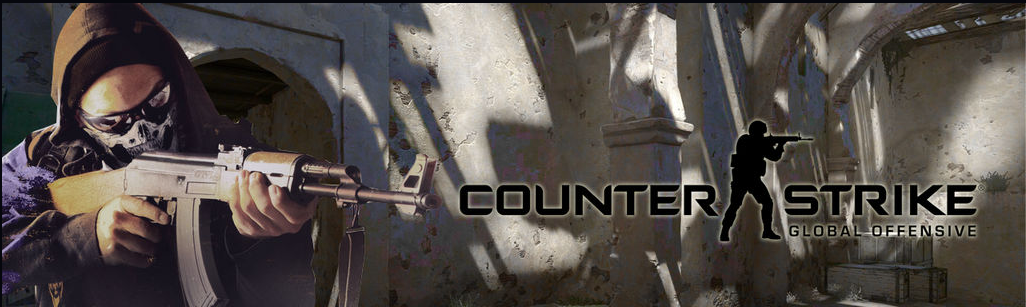

# Comprensión y preparación de los datos
## CRISP-DM: Comprensión del negocio, comprensión de los datos y preparación de los datos

**Dataset:** partidas y rondas de Counter-Strike.


### Objetivo
Desarrollar las tres primeras fases de CRISP-DM mediante un análisis reproducible y justificado. Las decisiones de limpieza, imputación, tratamiento de outliers, encoding y escalamiento se tomarán a partir de la evidencia observada en los datos.

# Contexto del caso

El presente proyecto aborda un problema de Machine Learning aplicado a datos de partidas de Counter-Strike. El conjunto de datos registra información asociada al desempeño de jugadores, equipos y rondas, incluyendo variables relacionadas con mapa, lado de juego, resultados de ronda y partida, supervivencia, equipamiento, distancias, desplazamiento y estadísticas de combate.

La estructura de los datos permite analizar el comportamiento de los jugadores en distintos niveles de granularidad. Cada observación puede asociarse a un jugador dentro de una ronda y una partida determinada mediante variables como `SteamId`, `RoundId`, `MatchId` e `InternalTeamId`. Además, el dataset contiene variables de resultado como `RoundWinner`, `MatchWinner` y `TimeAlive`, las cuales permiten plantear tareas de aprendizaje supervisado. 

A partir de esta información se definen dos problemas predictivos independientes. El primero corresponde a una tarea de **clasificación**, cuyo objetivo es estimar si un equipo ganará una partida utilizando `MatchWinner` como variable objetivo. Para este problema, la información debe ser reorganizada a nivel equipo-partida, de manera que cada observación represente a un equipo dentro de un encuentro.

El segundo corresponde a una tarea de **regresión**, donde se busca estimar el tiempo que un jugador permanece activo dentro de una ronda utilizando `TimeAlive` como variable objetivo. En este caso se mantiene una granularidad jugador-ronda, ya que el valor a predecir depende de cada participante y de la ronda en la que interviene.

El informe aborda las fases de CRISP-DM: **comprensión del negocio, comprensión de los datos, preparación, modelado y evaluación**. A partir del análisis exploratorio se evaluará la calidad de la información, la presencia de valores faltantes, outliers, inconsistencias, variables categóricas y posibles fuentes de *data leakage*, con el objetivo de generar conjuntos de datos adecuados para una futura etapa de modelado.

Se construyen dos conjuntos analíticos independientes, uno orientado a clasificación y otro a regresión. La validación final de los datos para el modelado se documenta en la sección 4.1.

## 0. Preguntas de investigación preliminares

### Pregunta principal de clasificación
**¿Cómo cambia la probabilidad de ganar una partida según el desempeño del equipo en las primeras rondas de cada lado (Terrorist y Counter-Terrorist), considerando además el mapa y la economía disponible?**

- **Target de clasificación:** `MatchWinner`.
- **Unidad analítica futura:** equipo-partida.
- **Momento de predicción:** después de observar las primeras rondas de ambos lados, utilizando solamente información disponible hasta ese momento.

**Alcance del clasificador:** el modelo final predice la clase de victoria y produce scores, no probabilidades calibradas; no se interpreta su salida como un porcentaje de victoria.

### Pregunta principal de regresión
**¿Es posible estimar cuánto tiempo permanecerá con vida un jugador durante una ronda a partir de información disponible al comienzo de la misma?**

- **Target de regresión:** `TimeAlive`.
- **Unidad analítica futura:** jugador-ronda.
- `TimeAlive` es ahora una variable numérica continua interpretable, por lo que constituye un target de regresión adecuado.
- Variables derivadas del propio tiempo de supervivencia o generadas durante/después de la ronda deberán excluirse para evitar *data leakage*.

### Regla metodológica
La clasificación y la regresión tienen granularidades distintas. Por ello, se prepararán dos conjuntos analíticos separados en la Fase 3, evitando mezclar registros jugador-ronda con observaciones equipo-partida.

# 1. Configuración

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import trim_mean

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

DATA_PATH = ROOT / "datos/demo_round_traces.csv"  # dataset local del proyecto

df_raw = pd.read_csv(DATA_PATH, sep=";")

print("Dimensiones:", df_raw.shape)
display(df_raw.head())

Dimensiones: (79157, 37)


,Unnamed: 0,Map,Team,InternalTeamId,MatchId,RoundId,SteamId,RoundWinner,MatchWinner,Survived,AbnormalMatch,TimeAlive,ScaledTimeAlive,AvgCentroidDistance,TravelledDistance,AvgRoundVelocity,AvgKillDistance,AvgSiteDistance,RLethalGrenadesThrown,RNonLethalGrenadesThrown,PrimaryAssaultRifle,PrimarySniperRifle,PrimaryHeavy,PrimarySMG,PrimaryPistol,FirstKillTime,RoundKills,RoundAssists,RoundHeadshots,RoundFlankKills,RoundStartingEquipmentValue,TeamStartingEquipmentValue,MatchKills,MatchFlankKills,MatchAssists,MatchHeadshots,AvgMatchKillDist
0,600,de_inferno,Terrorist,1,4,1,76561198036987787,False,True,False,False,51.1202,0.9623,"322,909.1315","100,831.4074",123.5679,0.0000,"5,988,404.5207",0,4,0.0000,0.0000,0.0000,0.0000,1,0.0000,0,0,0,0,750,4400,0,0,0,0,"501,379.1831"
1,601,de_inferno,Terrorist,1,4,1,76561197971812216,False,True,False,False,43.4866,0.8186,"547,137.4585","60,960.8832",87.8399,0.0000,"5,415,945.3953",0,0,0.0000,0.0000,0.0000,0.0000,1,0.0000,0,0,0,0,800,4400,0,0,0,0,"208,807.5873"
2,602,de_inferno,Terrorist,1,4,1,76561197972240652,False,True,False,False,37.3547,0.7032,0.0000,"56,422.5238",94.6687,0.0000,"6,658,032.5422",0,0,0.0000,0.0000,0.0000,0.0000,1,0.0000,0,0,0,0,1000,4400,0,0,0,0,"381,652.0279"
3,603,de_inferno,Terrorist,1,4,1,76561197975824962,False,True,False,False,47.6789,0.8975,"768,923.1796","89,634.7331",117.7855,0.0000,"5,364,147.1151",0,0,0.0000,0.0000,0.0000,0.0000,1,0.0000,0,0,0,0,850,4400,0,0,0,0,"289,754.5031"
4,604,de_inferno,Terrorist,1,4,1,76561197960331095,False,True,True,False,53.1225,1.0000,"202,397.4468","108,656.4973",128.1327,0.0000,"4,878,228.1909",1,1,0.0000,0.0000,0.0000,0.0000,1,0.0000,0,0,0,0,1000,4400,0,0,0,0,"254,527.6912"


# FASE 1 — COMPRENSIÓN DEL NEGOCIO

## 1.1 Identificación del problema

Counter-Strike se organiza en partidas compuestas por rondas. Durante la partida, los equipos alternan entre los lados Terrorist y CounterTerrorist. El desempeño temprano puede generar ventajas competitivas y económicas que potencialmente afectan el resultado final.

El proyecto busca estudiar cuánto aporta el desempeño de las primeras rondas a la explicación y eventual predicción del resultado final de una partida.

## 1.2 Objetivos

### Objetivo general
Analizar los factores asociados al resultado de una partida y preparar un conjunto de datos apto para tareas supervisadas de clasificación y regresión.

### Objetivos específicos
1. Describir estadísticamente las variables del dataset.
2. Identificar problemas de calidad, valores faltantes, duplicados y valores atípicos.
3. Analizar la relación entre mapa, lado, rondas iniciales, economía y resultado.
4. Definir un target para clasificación y otro para regresión.
5. Determinar qué técnicas de imputación, encoding y escalamiento son apropiadas.
6. Construir un dataset preparado para una futura fase de modelado.

## 1.3 Criterios de éxito preliminares

- Obtener variables correctamente tipadas y documentadas.
- Justificar el tratamiento de missing values y outliers.
- Evitar utilizar identificadores o información futura como variables predictoras.
- Construir variables derivadas coherentes con la pregunta de investigación.

### Conclusión Fase 1 — Comprensión del negocio

El análisis propuesto busca determinar cómo el desempeño inicial y las condiciones económicas de los equipos influyen en el desarrollo de una partida de Counter-Strike y en la probabilidad de obtener la victoria. En particular, se analizará la importancia de las primeras rondas jugadas tanto del lado Terrorist como Counter-Terrorist, considerando que el resultado de estas rondas puede afectar la economía disponible, las decisiones estratégicas posteriores y, eventualmente, el resultado final de la partida.

El conocimiento obtenido puede ser útil para los jugadores, ya que permitirá cuantificar mediante datos la importancia de comenzar favorablemente cada lado de una partida. Esto puede ayudar a comprender mejor el impacto de las decisiones tomadas durante las primeras rondas y apoyar una preparación estratégica más informada.

Como objetivo de **clasificación** se establece `MatchWinner`, que indica si el equipo obtuvo la victoria final. Las variables resumen el rendimiento y el equipamiento de las primeras rondas observadas de ambos lados. En EP2 se realiza una única predicción por equipo después de disponer de esas observaciones, no una predicción al inicio de cada lado.

Como objetivo de **regresión** se establece `TimeAlive`. En el dataset esta variable se encuentra representada como un valor numérico continuo y posee una interpretación directa en términos de tiempo de supervivencia durante la ronda. La regresión se planteará a nivel jugador-ronda y buscará estimar `TimeAlive` utilizando únicamente información disponible al comienzo de la ronda.

Las dos tareas requieren controlar explícitamente el *data leakage*. Para predecir `MatchWinner` no se utilizarán estadísticas finales de la partida ni información de rondas posteriores al instante de predicción. Para predecir `TimeAlive` tampoco se utilizarán variables derivadas del propio tiempo de supervivencia ni eventos que ocurren durante o después de la ronda.

De esta manera, el proyecto mantiene una misma temática de análisis del desempeño en Counter-Strike, pero diferencia correctamente dos problemas supervisados: clasificación a nivel equipo-partida y regresión a nivel jugador-ronda.

# FASE 2 — COMPRENSIÓN DE LOS DATOS

Se observan **37 columnas**. Entre los campos aparecen:

- `SteamId`: identificador del jugador.
- `ScaledTimeAlive`: versión escalada de `TimeAlive`.
- `AvgCentroidDistance`: distancia media respecto de un centroide.
- `AvgRoundVelocity`: velocidad media durante la ronda.
- `AvgKillDistance`: distancia media de las eliminaciones.
- `AvgSiteDistance`: distancia media respecto del sitio.
- `AvgMatchKillDist`: distancia media de eliminación a nivel de partida.

 `TimeAlive`, `TravelledDistance` y `FirstKillTime` aparecen como variables numéricas (`float64`) y son directamente analizables.

In [3]:
print("Dimensiones:", df_raw.shape)
print("\nColumnas:")
print(df_raw.columns.tolist())

print("\nInformación del dataset:")
df_raw.info()

Dimensiones: (79157, 37)

Columnas:
['Unnamed: 0', 'Map', 'Team', 'InternalTeamId', 'MatchId', 'RoundId', 'SteamId', 'RoundWinner', 'MatchWinner', 'Survived', 'AbnormalMatch', 'TimeAlive', 'ScaledTimeAlive', 'AvgCentroidDistance', 'TravelledDistance', 'AvgRoundVelocity', 'AvgKillDistance', 'AvgSiteDistance', 'RLethalGrenadesThrown', 'RNonLethalGrenadesThrown', 'PrimaryAssaultRifle', 'PrimarySniperRifle', 'PrimaryHeavy', 'PrimarySMG', 'PrimaryPistol', 'FirstKillTime', 'RoundKills', 'RoundAssists', 'RoundHeadshots', 'RoundFlankKills', 'RoundStartingEquipmentValue', 'TeamStartingEquipmentValue', 'MatchKills', 'MatchFlankKills', 'MatchAssists', 'MatchHeadshots', 'AvgMatchKillDist']

Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79157 entries, 0 to 79156
Data columns (total 37 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Unnamed: 0                   79157 non-null  int64  
 1  

In [4]:
# Tipo, número de valores únicos y cantidad de nulos por columna
resumen_estructura = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(dropna=True),
    "missing": df_raw.isna().sum(),
    "missing_pct": df_raw.isna().mean() * 100
}).sort_values("missing_pct", ascending=False)

display(resumen_estructura)

,dtype,n_unique,missing,missing_pct
Unnamed: 0,int64,79157,0,0.0000
Map,object,4,0,0.0000
Team,object,2,0,0.0000
InternalTeamId,int64,2,0,0.0000
MatchId,int64,333,0,0.0000
RoundId,int64,36,0,0.0000
SteamId,int64,362,0,0.0000
RoundWinner,bool,2,0,0.0000
MatchWinner,bool,2,0,0.0000
Survived,bool,2,0,0.0000


### Interpretación inicial del esquema

A partir del dataset se puede establecer preliminarmente que:

- la unidad original corresponde a **un jugador dentro de una ronda**;
- `Map` y `Team` son variables categóricas nominales;
- `RoundWinner`, `MatchWinner`, `Survived` y `AbnormalMatch` aparecen como booleanas;
- `TimeAlive`, `TravelledDistance`, `FirstKillTime` y las medidas de distancia/velocidad aparecen como variables numéricas continuas;
- `MatchId`, `InternalTeamId` y `SteamId` son identificadores y no deben interpretarse como magnitudes;
- `RoundId` funciona como identificador/posición temporal de la ronda dentro de una partida;
- `Unnamed: 0` corresponde a un índice exportado y es candidato a eliminación.

La presencia de `SteamId` permite identificar jugadores de manera persistente, pero no se utilizará directamente como una variable numérica predictora porque su valor entero no representa una magnitud ni un orden.

## 2.2 Verificar la granularidad del dataset

Antes de calcular probabilidades o construir targets derivados debemos saber qué representa una fila.

In [5]:
cols_granularidad = [
    c for c in ["MatchId", "RoundId", "InternalTeamId", "SteamId", "Team"]
    if c in df_raw.columns
]

display(df_raw[cols_granularidad].head(20))

if {"MatchId", "RoundId", "InternalTeamId"}.issubset(df_raw.columns):
    jugadores_por_equipo_ronda = (
        df_raw.groupby(["MatchId", "RoundId", "InternalTeamId"])
        .size()
        .describe()
    )
    print("Filas por equipo/ronda:")
    display(jugadores_por_equipo_ronda)

if {"MatchId", "RoundId", "InternalTeamId", "SteamId"}.issubset(df_raw.columns):
    repeticion_jugador = (
        df_raw.groupby(["MatchId", "RoundId", "InternalTeamId"])["SteamId"]
        .nunique()
        .describe()
    )
    print("Jugadores únicos por equipo/ronda:")
    display(repeticion_jugador)

,MatchId,RoundId,InternalTeamId,SteamId,Team
0,4,1,1,76561198036987787,Terrorist
1,4,1,1,76561197971812216,Terrorist
2,4,1,1,76561197972240652,Terrorist
3,4,1,1,76561197975824962,Terrorist
4,4,1,1,76561197960331095,Terrorist
5,4,1,2,76561198106907258,CounterTerrorist
6,4,1,2,76561198019196091,CounterTerrorist
7,4,1,2,76561197965932989,CounterTerrorist
8,4,1,2,76561198001822267,CounterTerrorist
9,4,1,2,76561198006466707,CounterTerrorist


Filas por equipo/ronda:


count   15,832.0000
mean         4.9998
std          0.0138
min          4.0000
25%          5.0000
50%          5.0000
75%          5.0000
max          5.0000
dtype: float64

Jugadores únicos por equipo/ronda:


count   15,832.0000
mean         4.9998
std          0.0138
min          4.0000
25%          5.0000
50%          5.0000
75%          5.0000
max          5.0000
Name: SteamId, dtype: float64

### Interpretación de la granularidad

La combinación `MatchId + RoundId + InternalTeamId` representa un equipo dentro de una ronda determinada. El dataset completo contiene 15.832 grupos equipo-ronda.

En condiciones normales, cada grupo contiene cinco jugadores distintos. Esto se cumple en 15.829 grupos, mientras que únicamente tres grupos presentan cuatro jugadores. La comparación entre el número de filas y la cantidad de `SteamId` únicos por grupo entrega la misma distribución, lo que indica que no existen jugadores duplicados dentro de una misma combinación equipo-ronda.

Por lo tanto, cada fila del dataset representa a un jugador específico dentro de una ronda, equipo y partida determinados.

Esta granularidad también explica que variables de nivel superior, como `RoundWinner`, `MatchWinner` o `TeamStartingEquipmentValue`, puedan aparecer repetidas en las filas correspondientes a los distintos jugadores de un mismo equipo. En consecuencia, los análisis a nivel de ronda o partida deberán realizarse mediante agregación o deduplicación previa, evitando interpretar directamente cada fila como una observación independiente de equipo o partido.

## 2.3 Duplicados

In [6]:
print("Filas completamente duplicadas:", df_raw.duplicated().sum())

if {"MatchId", "RoundId", "InternalTeamId"}.issubset(df_raw.columns):
    print("\nEjemplos de grupos equipo/ronda:")
    display(
        df_raw.groupby(["MatchId", "RoundId", "InternalTeamId"])
        .size()
        .value_counts()
        .sort_index()
    )

Filas completamente duplicadas: 0

Ejemplos de grupos equipo/ronda:


4        3
5    15829
Name: count, dtype: int64

### Interpretación de duplicados

No se detectaron filas completamente duplicadas en el dataset, por lo que no es necesario aplicar una eliminación de registros duplicados a nivel de fila completa.

Al agrupar por `MatchId`, `RoundId` e `InternalTeamId`, se obtienen 15.832 grupos equipo-ronda. De ellos, 15.829 contienen cinco registros, mientras que sólo tres grupos contienen cuatro registros.

Este resultado es consistente con la granularidad observada previamente y confirma que la estructura esperada de cinco jugadores por equipo-ronda se cumple prácticamente en todo el dataset. Los tres grupos con cuatro registros se conservarán inicialmente, ya que una menor cantidad de jugadores no constituye por sí sola evidencia suficiente para considerar esos registros erróneos.

## 2.4 Variables categóricas y binarias

In [7]:
categoricas = df_raw.select_dtypes(include=["object", "category"]).columns.tolist()
booleanas = df_raw.select_dtypes(include=["bool"]).columns.tolist()

print("Categóricas:", categoricas)
print("Booleanas:", booleanas)

for col in categoricas:
    print(f"\n--- {col} ---")
    display(df_raw[col].value_counts(dropna=False).head(20))

for col in booleanas:
    print(f"\n--- {col} ---")
    display(df_raw[col].value_counts(dropna=False, normalize=False))
    display((df_raw[col].value_counts(dropna=False, normalize=True) * 100).round(2))

Categóricas: ['Map', 'Team']
Booleanas: ['RoundWinner', 'MatchWinner', 'Survived', 'AbnormalMatch']

--- Map ---


Map
de_inferno    28869
de_dust2      19120
de_mirage     19019
de_nuke       12149
Name: count, dtype: int64


--- Team ---


Team
Terrorist           39592
CounterTerrorist    39565
Name: count, dtype: int64


--- RoundWinner ---


...

Survived
False    47214
True     31943
Name: count, dtype: int64

Survived
False   59.6500
True    40.3500
Name: proportion, dtype: float64


--- AbnormalMatch ---


AbnormalMatch
False    79157
Name: count, dtype: int64

AbnormalMatch
False   100.0000
Name: proportion, dtype: float64

### Interpretación de variables categóricas y binarias

El dataset contiene dos variables categóricas nominales: `Map` y `Team`.

`Map` presenta cuatro categorías, siendo `de_inferno` la más frecuente, seguida por `de_dust2`, `de_mirage` y `de_nuke`. Estas categorías no poseen un orden natural, por lo que en una etapa posterior deberán tratarse mediante una técnica de codificación nominal, como One-Hot Encoding.

`Team` presenta dos categorías (`Terrorist` y `CounterTerrorist`) con una distribución prácticamente equilibrada: 39.592 y 39.565 observaciones, respectivamente.

Las variables booleanas `RoundWinner` y `MatchWinner` representan resultados de ronda y de partida. `RoundWinner` se encuentra prácticamente equilibrada entre ambas clases, mientras que `MatchWinner` presenta una ligera mayor frecuencia de la clase `False` (53,08 %) respecto de `True` (46,92 %).

La variable `Survived` presenta una distribución menos equilibrada, con 59,65 % de observaciones `False` y 40,35 % `True`, aunque sin evidenciar un desbalance extremo.

Finalmente, `AbnormalMatch` presenta únicamente el valor `False` en las 79.157 observaciones, confirmando que se trata de una variable constante y, por lo tanto, sin capacidad discriminante para el modelado.

## 2.5 Validación semántica de variables y posible data leakage

Una variable puede estar correctamente tipada desde el punto de vista técnico y, aun así, no ser adecuada como predictor.

Por este motivo, en esta sección no sólo se revisa el tipo de dato, sino también:

- qué representa cada variable;
- si corresponde a un identificador, una medida numérica, un conteo o una categoría;
- en qué momento de la ronda o partida se encuentra disponible;
- si contiene información generada después del evento que se desea predecir;
- y si podría introducir *data leakage*.

El resumen de tipos y cardinalidad se utiliza como punto de partida para esta validación semántica.

In [8]:
# Resumen de tipos y cardinalidad
perfil_variables = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(dropna=True),
    "missing": df_raw.isna().sum(),
    "missing_pct": df_raw.isna().mean() * 100
})

display(perfil_variables)

,dtype,n_unique,missing,missing_pct
Unnamed: 0,int64,79157,0,0.0000
Map,object,4,0,0.0000
Team,object,2,0,0.0000
InternalTeamId,int64,2,0,0.0000
MatchId,int64,333,0,0.0000
RoundId,int64,36,0,0.0000
SteamId,int64,362,0,0.0000
RoundWinner,bool,2,0,0.0000
MatchWinner,bool,2,0,0.0000
Survived,bool,2,0,0.0000


### 2.5.1 Roles preliminares de las variables

A partir del nombre y estructura de los campos, se propone la siguiente clasificación inicial:

**Identificadores / agrupación**
- `Unnamed: 0`: índice exportado.
- `MatchId`: identifica la partida.
- `InternalTeamId`: identifica al equipo dentro de la partida.
- `SteamId`: identifica al jugador.

**Contexto conocido antes o al inicio de la ronda**
- `Map`
- `Team`
- `RoundId`
- `RoundStartingEquipmentValue`
- `TeamStartingEquipmentValue`

**Targets**
- `MatchWinner`: clasificación.
- `TimeAlive`: regresión.

**Información generada durante o después de la ronda**
- `RoundWinner`
- `Survived`
- `ScaledTimeAlive`
- `TravelledDistance`
- `AvgRoundVelocity`
- `AvgKillDistance`
- `AvgCentroidDistance`
- `AvgSiteDistance`
- `RLethalGrenadesThrown`
- `RNonLethalGrenadesThrown`
- `FirstKillTime`
- `RoundKills`
- `RoundAssists`
- `RoundHeadshots`
- `RoundFlankKills`

**Información de partida completa o potencialmente posterior al instante de predicción**
- `MatchKills`
- `MatchFlankKills`
- `MatchAssists`
- `MatchHeadshots`
- `AvgMatchKillDist`

Las variables `PrimaryAssaultRifle`, `PrimarySniperRifle`, `PrimaryHeavy`, `PrimarySMG` y `PrimaryPistol` requieren validación de su definición exacta antes de decidir si representan información disponible al inicio de la ronda o estadísticas generadas durante ella.

### 2.5.2 Auditoría de `TimeAlive` y variables derivadas

`TimeAlive` es interpretable como variable continua. Sin embargo, el dataset muestra que `ScaledTimeAlive` parece ser una transformación directa de `TimeAlive`.

Si esta relación se confirma en análisis, `ScaledTimeAlive` debe excluirse de los predictores de la regresión porque entregaría al modelo información derivada directamente del target.

In [9]:
# Auditoría de TimeAlive y ScaledTimeAlive

print("Correlación TimeAlive vs ScaledTimeAlive:")
display(
    df_raw[["TimeAlive", "ScaledTimeAlive"]].corr(method="pearson")
)

# Hipótesis:
# ScaledTimeAlive ≈ TimeAlive / max(TimeAlive dentro de la ronda)

max_timealive_ronda = (
    df_raw
    .groupby(["MatchId", "RoundId"])["TimeAlive"]
    .transform("max")
)

scaled_calculado = (
    df_raw["TimeAlive"] / max_timealive_ronda
)

coincide = np.isclose(
    df_raw["ScaledTimeAlive"],
    scaled_calculado,
    rtol=1e-5,
    atol=1e-8,
    equal_nan=False
)

print(
    "\nPorcentaje compatible con "
    "TimeAlive / max(TimeAlive de la ronda):",
    round(coincide.mean() * 100, 4),
    "%"
)

print(
    "Coinciden:",
    int(coincide.sum()),
    "de",
    len(coincide),
    "registros"
)

comparacion = pd.DataFrame({
    "MatchId": df_raw["MatchId"],
    "RoundId": df_raw["RoundId"],
    "TimeAlive": df_raw["TimeAlive"],
    "MaxTimeAliveRonda": max_timealive_ronda,
    "ScaledTimeAlive_real": df_raw["ScaledTimeAlive"],
    "ScaledTimeAlive_calculado": scaled_calculado,
    "Coincide": coincide
})

print("\nEjemplos donde la hipótesis NO coincide:")
display(
    comparacion[
        ~comparacion["Coincide"]
    ].head(20)
)

Correlación TimeAlive vs ScaledTimeAlive:


,TimeAlive,ScaledTimeAlive
TimeAlive,1.0000,0.3503
ScaledTimeAlive,0.3503,1.0000



Porcentaje compatible con TimeAlive / max(TimeAlive de la ronda): 99.4315 %
Coinciden: 78707 de 79157 registros

Ejemplos donde la hipótesis NO coincide:


,MatchId,RoundId,TimeAlive,MaxTimeAliveRonda,ScaledTimeAlive_real,ScaledTimeAlive_calculado,Coincide
29919,175,1,127.0806,127.0806,1.6099,1.0000,False
29920,175,1,28.0306,127.0806,0.3551,0.2206,False
29921,175,1,55.2442,127.0806,0.6998,0.4347,False
29922,175,1,32.2415,127.0806,0.4084,0.2537,False
29923,175,1,48.8965,127.0806,0.6194,0.3848,False
29924,175,1,29.2876,127.0806,0.3710,0.2305,False
29925,175,1,78.9383,127.0806,1.0000,0.6212,False
29926,175,1,78.9383,127.0806,1.0000,0.6212,False
29927,175,1,26.8993,127.0806,0.3408,0.2117,False
29928,175,1,50.2163,127.0806,0.6361,0.3952,False


### Interpretación de `ScaledTimeAlive`

La correlación de Pearson entre `TimeAlive` y `ScaledTimeAlive` es de aproximadamente 0,35. Por lo tanto, al analizar todas las observaciones en conjunto no se observa una relación lineal global fuerte entre ambas variables.

Sin embargo, al comprobar directamente la hipótesis de que `ScaledTimeAlive` corresponde a `TimeAlive` dividido por el máximo `TimeAlive` observado dentro de cada ronda, se obtuvo una coincidencia del 99,43 %, equivalente a 78.707 de 79.157 registros.

Este resultado demuestra que `ScaledTimeAlive` mantiene una dependencia directa con `TimeAlive` en la gran mayoría de las observaciones. Los 450 registros que no coinciden con la fórmula evaluada indican que no puede afirmarse que esta relación represente exactamente el mecanismo de cálculo para la totalidad del dataset.

Aun así, la evidencia es suficiente para considerar que `ScaledTimeAlive` contiene información derivada directamente del target de regresión. Por este motivo, dado que `TimeAlive` será utilizado como variable objetivo, `ScaledTimeAlive` será excluida de los predictores para evitar *data leakage* y una evaluación artificialmente optimista del modelo.

### 2.5.3 Auditoría de identificadores y variables constantes

Las variables identificadoras son necesarias para agrupar correctamente los datos, pero no deben entrar al modelo como si fueran magnitudes continuas.

In [10]:
perfil_cardinalidad = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(dropna=True),
    "unique_pct": df_raw.nunique(dropna=True) / len(df_raw) * 100,
    "missing": df_raw.isna().sum()
}).sort_values(["n_unique", "unique_pct"])

display(perfil_cardinalidad)

constantes = perfil_cardinalidad[perfil_cardinalidad["n_unique"] <= 1]
print("\nVariables constantes o sin variación:")
display(constantes)

ids_esperados = [
    c for c in ["Unnamed: 0", "MatchId", "InternalTeamId", "SteamId"]
    if c in df_raw.columns
]
print("\nIdentificadores esperados:")
display(perfil_cardinalidad.loc[ids_esperados])

,dtype,n_unique,unique_pct,missing
AbnormalMatch,bool,1,0.0013,0
Team,object,2,0.0025,0
InternalTeamId,int64,2,0.0025,0
RoundWinner,bool,2,0.0025,0
MatchWinner,bool,2,0.0025,0
Survived,bool,2,0.0025,0
PrimaryPistol,int64,2,0.0025,0
Map,object,4,0.0051,0
RLethalGrenadesThrown,int64,5,0.0063,0
RoundAssists,int64,5,0.0063,0



Variables constantes o sin variación:


,dtype,n_unique,unique_pct,missing
AbnormalMatch,bool,1,0.0013,0



Identificadores esperados:


,dtype,n_unique,unique_pct,missing
Unnamed: 0,int64,79157,100.0000,0
MatchId,int64,333,0.4207,0
InternalTeamId,int64,2,0.0025,0
SteamId,int64,362,0.4573,0


El análisis de cardinalidad permite distinguir variables numéricas que cumplen una función estructural de aquellas que representan magnitudes potencialmente utilizables como predictores.

`Unnamed: 0` presenta 79.157 valores distintos para 79.157 observaciones, equivalentes al 100 % de unicidad. Este comportamiento es consistente con un índice generado durante la exportación del dataset y, por lo tanto, no contiene información útil para el problema predictivo. Será eliminado durante la fase de preparación.

`AbnormalMatch` presenta un único valor (`False`) en todo el dataset. Al no contener variación, no posee capacidad discriminante y también será excluida de los conjuntos destinados al modelado.

`MatchId` identifica las 333 partidas presentes en el dataset, mientras que `SteamId` identifica 362 jugadores distintos. Ambas variables son necesarias para preservar la estructura de los datos, realizar agrupaciones y controlar la separación de observaciones, pero no deben ser interpretadas directamente como variables numéricas continuas.

`InternalTeamId` presenta únicamente dos valores posibles, pero corresponde a un identificador local del equipo dentro de cada partida. Su baja cardinalidad no implica que deba tratarse como una variable binaria predictiva; será utilizada principalmente para mantener la estructura equipo-partida durante las agregaciones.

En consecuencia, la selección de variables no se realizará únicamente a partir de su tipo de dato o cardinalidad, sino también considerando su significado dentro del problema.

### 2.5.4 Consistencia de variables repetidas por grupo

Algunas variables deberían ser constantes dentro de un grupo lógico. Esta comprobación permite detectar errores sin depender de una inspección manual.

In [11]:
chequeos_consistencia = {}

if {"MatchId", "Map"}.issubset(df_raw.columns):
    chequeos_consistencia["Map por MatchId"] = (
        df_raw.groupby("MatchId")["Map"].nunique(dropna=True)
    )

if {"MatchId", "RoundId", "InternalTeamId", "Team"}.issubset(df_raw.columns):
    chequeos_consistencia["Team por equipo-ronda"] = (
        df_raw.groupby(
            ["MatchId", "RoundId", "InternalTeamId"]
        )["Team"].nunique(dropna=True)
    )

if {"MatchId", "RoundId", "InternalTeamId", "RoundWinner"}.issubset(df_raw.columns):
    chequeos_consistencia["RoundWinner por equipo-ronda"] = (
        df_raw.groupby(
            ["MatchId", "RoundId", "InternalTeamId"]
        )["RoundWinner"].nunique(dropna=True)
    )

if {"MatchId", "InternalTeamId", "MatchWinner"}.issubset(df_raw.columns):
    chequeos_consistencia["MatchWinner por equipo-partida"] = (
        df_raw.groupby(
            ["MatchId", "InternalTeamId"]
        )["MatchWinner"].nunique(dropna=True)
    )

for nombre, serie in chequeos_consistencia.items():
    inconsistentes = serie[serie > 1]
    print(f"\n{nombre}")
    print("Grupos inconsistentes:", len(inconsistentes))
    if len(inconsistentes):
        display(inconsistentes.head(20))


Map por MatchId
Grupos inconsistentes: 0

Team por equipo-ronda
Grupos inconsistentes: 18


MatchId  RoundId  InternalTeamId
6        8        1                 2
         9        1                 2
         10       1                 2
         11       1                 2
         12       1                 2
                  2                 2
         13       1                 2
                  2                 2
         14       1                 2
                  2                 2
         15       1                 2
         16       1                 2
29       21       1                 2
         34       1                 2
395      14       1                 2
                  2                 2
         15       1                 2
                  2                 2
Name: Team, dtype: int64


RoundWinner por equipo-ronda
Grupos inconsistentes: 0

MatchWinner por equipo-partida
Grupos inconsistentes: 0


In [12]:
# Identificar los grupos donde un mismo equipo-ronda
# contiene más de un valor de Team

team_por_grupo = (
    df_raw
    .groupby(["MatchId", "RoundId", "InternalTeamId"])["Team"]
    .nunique(dropna=True)
)

grupos_team_inconsistente = (
    team_por_grupo[team_por_grupo > 1]
    .reset_index()
)

print(
    "Cantidad de grupos inconsistentes:",
    len(grupos_team_inconsistente)
)

# Recuperar todas las filas pertenecientes a esos grupos
detalle_team_inconsistente = df_raw.merge(
    grupos_team_inconsistente[
        ["MatchId", "RoundId", "InternalTeamId"]
    ],
    on=["MatchId", "RoundId", "InternalTeamId"],
    how="inner"
)

columnas_revision = [
    c for c in [
        "MatchId",
        "RoundId",
        "InternalTeamId",
        "SteamId",
        "Team",
        "RoundWinner",
        "MatchWinner",
        "RoundStartingEquipmentValue",
        "TeamStartingEquipmentValue"
    ]
    if c in detalle_team_inconsistente.columns
]

display(
    detalle_team_inconsistente[columnas_revision]
    .sort_values(
        ["MatchId", "RoundId", "InternalTeamId", "Team"]
    )
)

Cantidad de grupos inconsistentes: 18


,MatchId,RoundId,InternalTeamId,SteamId,Team,RoundWinner,MatchWinner,RoundStartingEquipmentValue,TeamStartingEquipmentValue
4,6,8,1,76561197960725934,CounterTerrorist,True,True,0,9200
0,6,8,1,76561197979126082,Terrorist,True,True,4400,9200
1,6,8,1,76561197973845818,Terrorist,True,True,4400,9200
2,6,8,1,76561197960499780,Terrorist,True,True,200,9200
3,6,8,1,76561197982141573,Terrorist,True,True,200,9200
...,...,...,...,...,...,...,...,...,...
85,395,15,2,76561198040582929,CounterTerrorist,False,True,200,2350
86,395,15,2,76561197986958527,CounterTerrorist,False,True,300,2350
88,395,15,2,76561197988535576,CounterTerrorist,False,True,200,2350
89,395,15,2,76561198012299323,CounterTerrorist,False,True,1450,2350


In [13]:
conteo_team_inconsistente = (
    detalle_team_inconsistente
    .groupby(
        ["MatchId", "RoundId", "InternalTeamId", "Team"],
        dropna=False
    )
    .size()
    .reset_index(name="n_jugadores")
)

display(conteo_team_inconsistente)

,MatchId,RoundId,InternalTeamId,Team,n_jugadores
0,6,8,1,CounterTerrorist,1
1,6,8,1,Terrorist,4
2,6,9,1,CounterTerrorist,1
3,6,9,1,Terrorist,4
4,6,10,1,CounterTerrorist,1
5,6,10,1,Terrorist,4
6,6,11,1,CounterTerrorist,1
7,6,11,1,Terrorist,4
8,6,12,1,CounterTerrorist,1
9,6,12,1,Terrorist,4


In [14]:
# Resumir la distribución de jugadores por Team
# dentro de cada grupo inconsistente

patrones_team = (
    conteo_team_inconsistente
    .pivot_table(
        index=["MatchId", "RoundId", "InternalTeamId"],
        columns="Team",
        values="n_jugadores",
        fill_value=0
    )
    .reset_index()
)

display(patrones_team)

# Frecuencia de cada patrón
columnas_team = [
    c for c in ["Terrorist", "CounterTerrorist"]
    if c in patrones_team.columns
]

print("\nFrecuencia de patrones:")
display(
    patrones_team[columnas_team]
    .value_counts()
    .reset_index(name="n_grupos")
)

Team,MatchId,RoundId,InternalTeamId,CounterTerrorist,Terrorist
0,6,8,1,1.0000,4.0000
1,6,9,1,1.0000,4.0000
2,6,10,1,1.0000,4.0000
3,6,11,1,1.0000,4.0000
4,6,12,1,1.0000,4.0000
5,6,12,2,1.0000,4.0000
6,6,13,1,1.0000,4.0000
7,6,13,2,1.0000,4.0000
8,6,14,1,1.0000,4.0000
9,6,14,2,1.0000,4.0000



Frecuencia de patrones:


,Terrorist,CounterTerrorist,n_grupos
0,4.0000,1.0000,14
1,1.0000,4.0000,4


La validación de variables repetidas mostró que `Map`, `RoundWinner` y `MatchWinner` mantienen valores consistentes dentro de sus respectivas unidades lógicas. La variable `Team`, en cambio, presenta 18 grupos inconsistentes definidos por la combinación `MatchId + RoundId + InternalTeamId`, correspondientes a 90 registros.

Las inconsistencias se concentran en las partidas `6`, `29` y `395`. Todos los grupos afectados contienen los cinco jugadores esperados y presentan una distribución 4–1 entre las categorías `Terrorist` y `CounterTerrorist`: 14 grupos contienen cuatro registros `Terrorist` y uno `CounterTerrorist`, mientras que cuatro grupos presentan el patrón inverso.

Aunque inicialmente esta distribución podría sugerir una corrección utilizando la categoría mayoritaria, una validación adicional demuestra que esta estrategia no es segura. En `MatchId = 6`, específicamente en las rondas 12, 13 y 14, aplicar la regla de mayoría provocaría que ambos `InternalTeamId` quedaran clasificados como `Terrorist` dentro de una misma ronda.

Este resultado contradice la estructura esperada del juego, ya que los dos equipos de una misma ronda deben ocupar lados opuestos. Por lo tanto, la categoría mayoritaria no puede considerarse necesariamente como la etiqueta correcta.

En consecuencia, no se realizará una corrección automática de `Team` por mayoría. Las observaciones afectadas se mantendrán identificadas como inconsistencias de calidad y serán tratadas de forma conservadora durante la fase de preparación de datos.

Para el problema de regresión a nivel jugador-ronda podrán excluirse específicamente los registros pertenecientes a los grupos inconsistentes. Para el problema de clasificación a nivel equipo-partida se evaluará la exclusión completa de las partidas afectadas (`MatchId` 6, 29 y 395), con el objetivo de evitar que estas inconsistencias se propaguen hacia las agregaciones utilizadas para construir las variables predictoras.

### 2.5.5 Missing values en su contexto

El tratamiento se decidirá utilizando el dataset completo. Antes de imputar, se cuantifican los valores faltantes y se determina si pueden recuperarse mediante información repetida dentro de los grupos lógicos.

In [15]:
missing_25 = pd.DataFrame({
    "cantidad": df_raw.isna().sum(),
    "porcentaje": df_raw.isna().mean() * 100
})
missing_25 = missing_25[missing_25["cantidad"] > 0].sort_values(
    "porcentaje", ascending=False
)
display(missing_25)

# Mostrar contexto de variables clave sólo si presentan missing.
for col in ["Team", "RoundWinner", "MatchWinner"]:
    if col in df_raw.columns and df_raw[col].isna().any():
        print(f"\n### Missing en {col}")
        filas = df_raw[df_raw[col].isna()]
        display(filas.head(20))

,cantidad,porcentaje


### Conclusiones de la validación semántica y de calidad

1. `TimeAlive`, `TravelledDistance`, `FirstKillTime` y las demás variables cuantitativas pueden utilizarse en el análisis descriptivo de distribuciones, dispersión, outliers y relaciones entre variables.

2. `SteamId`, `MatchId` e `InternalTeamId` cumplen principalmente funciones de identificación y agrupación. Aunque se almacenan como valores numéricos, no deben interpretarse como magnitudes continuas ni incorporarse directamente al modelo con ese significado.

3. `ScaledTimeAlive` fue auditada respecto de `TimeAlive`. La hipótesis `TimeAlive / max(TimeAlive de la ronda)` reproduce el 99,43 % de sus valores (78.707 de 79.157 registros), evidenciando una dependencia directa con el target de regresión. Por esta razón se excluirá de sus predictores para evitar *data leakage*.

4. `AbnormalMatch` presenta un único valor (`False`) en las 79.157 observaciones. Al ser una variable constante y no aportar capacidad discriminante, será excluida durante la preparación de los datos.

5. No se detectaron valores faltantes en ninguna de las 37 variables del dataset completo. En consecuencia, no será necesario aplicar técnicas de imputación ni eliminar observaciones por *missing values*.

6. La variable `Team` presenta 18 grupos equipo-ronda inconsistentes, correspondientes a 90 registros y concentrados en las partidas 6, 29 y 395. Una corrección automática por mayoría no es segura, ya que en algunas rondas produciría que ambos equipos quedaran asignados al mismo lado. Estas observaciones serán tratadas de forma conservadora durante la preparación de los datos.

7. Para el problema de clasificación de `MatchWinner`, sólo podrán utilizarse variables disponibles en el instante definido para realizar la predicción. En particular, el escenario planteado utilizará información obtenida a partir de las primeras dos rondas observadas de cada equipo en cada lado (`Terrorist` y `CounterTerrorist`), evitando incorporar estadísticas correspondientes al resultado final de la partida.

8. Para el problema de regresión de `TimeAlive`, se utilizarán únicamente variables conocidas antes o al inicio de la ronda. Las características generadas durante o después de la ronda, como resultados, supervivencia, movimiento, distancias, kills o asistencias, no serán utilizadas como predictores cuando impliquen información posterior al instante de predicción.

9. Las variables `PrimaryAssaultRifle`, `PrimarySniperRifle`, `PrimaryHeavy`, `PrimarySMG` y `PrimaryPistol` requieren cautela en su interpretación semántica. Su inclusión como predictores dependerá de poder establecer que representan información disponible en el momento definido para realizar la predicción.

## 2.6 Estadística descriptiva de variables numéricas

In [16]:
# Identificación explícita de las columnas numéricas.
numericas = df_raw.select_dtypes(include="number").columns.tolist()

# Variables que no se analizarán como magnitudes numéricas continuas
columnas_estructurales = [
    c for c in [
        "Unnamed: 0",
        "MatchId",
        "InternalTeamId",
        "SteamId",
        "RoundId"
    ]
    if c in numericas
]

numericas_analisis = [
    c for c in numericas
    if c not in columnas_estructurales
]

print("Variables numéricas detectadas:", numericas)
print(
    "Variables estructurales/ordinales excluidas del resumen analítico:",
    columnas_estructurales
)
print("Variables para análisis descriptivo:", numericas_analisis)

display(df_raw[numericas_analisis].describe().T)

Variables numéricas detectadas: ['Unnamed: 0', 'InternalTeamId', 'MatchId', 'RoundId', 'SteamId', 'TimeAlive', 'ScaledTimeAlive', 'AvgCentroidDistance', 'TravelledDistance', 'AvgRoundVelocity', 'AvgKillDistance', 'AvgSiteDistance', 'RLethalGrenadesThrown', 'RNonLethalGrenadesThrown', 'PrimaryAssaultRifle', 'PrimarySniperRifle', 'PrimaryHeavy', 'PrimarySMG', 'PrimaryPistol', 'FirstKillTime', 'RoundKills', 'RoundAssists', 'RoundHeadshots', 'RoundFlankKills', 'RoundStartingEquipmentValue', 'TeamStartingEquipmentValue', 'MatchKills', 'MatchFlankKills', 'MatchAssists', 'MatchHeadshots', 'AvgMatchKillDist']
Variables estructurales/ordinales excluidas del resumen analítico: ['Unnamed: 0', 'MatchId', 'InternalTeamId', 'SteamId', 'RoundId']
Variables para análisis descriptivo: ['TimeAlive', 'ScaledTimeAlive', 'AvgCentroidDistance', 'TravelledDistance', 'AvgRoundVelocity', 'AvgKillDistance', 'AvgSiteDistance', 'RLethalGrenadesThrown', 'RNonLethalGrenadesThrown', 'PrimaryAssaultRifle', 'PrimarySn

,count,mean,std,min,25%,50%,75%,max
TimeAlive,"79,157.0000",72.7957,48.3210,0.0000,47.0801,69.2396,92.6478,"2,990.5604"
ScaledTimeAlive,"79,157.0000",0.8296,0.2108,0.0000,0.6989,0.9228,1.0000,2.0000
AvgCentroidDistance,"79,157.0000","1,122,538.2040","1,134,700.4697",0.0000,"257,882.5179","740,980.3557","1,753,171.7237","22,023,456.0721"
TravelledDistance,"79,157.0000","104,188.8274","354,348.6989",0.0000,"58,982.5483","86,015.5711","121,396.6206","39,646,454.2725"
AvgRoundVelocity,"79,157.0000",84.3518,171.8901,0.0000,56.2026,83.6173,104.1311,"24,111.8198"
AvgKillDistance,"79,157.0000","288,037.9390","603,630.6890",0.0000,0.0000,0.0000,"360,339.4116","11,045,641.3975"
AvgSiteDistance,"79,157.0000","2,828,656.6397","1,528,175.3656",0.0000,"1,508,094.6700","2,699,213.6893","3,728,018.2542","12,034,402.8967"
RLethalGrenadesThrown,"79,157.0000",0.4987,0.5980,0.0000,0.0000,0.0000,1.0000,4.0000
RNonLethalGrenadesThrown,"79,157.0000",1.2581,1.1849,0.0000,0.0000,1.0000,2.0000,6.0000
PrimaryAssaultRifle,"79,157.0000",0.6754,0.4641,0.0000,0.0000,1.0000,1.0000,1.0000


### Clasificación semántica de variables numéricas

El tipo `int64` o `float64` de Python no define por sí solo el significado estadístico. Se separarán identificadores, variables binarias, conteos y medidas continuas.

Esta distinción será importante al elegir gráficos, métodos de outliers y escalamiento.

In [17]:
roles_numericos = {

    "identificadores": [
        c for c in [
            "Unnamed: 0",
            "MatchId",
            "InternalTeamId",
            "SteamId"
        ]
        if c in df_raw.columns
    ],

    "ordinal_temporal": [
        c for c in ["RoundId"]
        if c in df_raw.columns
    ],

    "binarias": [
        c for c in ["PrimaryPistol"]
        if c in df_raw.columns
    ],

    "conteos": [
        c for c in [
            "RLethalGrenadesThrown",
            "RNonLethalGrenadesThrown",
            "RoundKills",
            "RoundAssists",
            "RoundHeadshots",
            "RoundFlankKills",
            "MatchKills",
            "MatchFlankKills",
            "MatchAssists",
            "MatchHeadshots"
        ]
        if c in df_raw.columns
    ],

    "continuas": [
        c for c in [
            "TimeAlive",
            "ScaledTimeAlive",
            "AvgCentroidDistance",
            "TravelledDistance",
            "AvgRoundVelocity",
            "AvgKillDistance",
            "AvgSiteDistance",
            "FirstKillTime",
            "RoundStartingEquipmentValue",
            "TeamStartingEquipmentValue",
            "AvgMatchKillDist"
        ]
        if c in df_raw.columns
    ],

    "armas_requieren_validacion": [
        c for c in [
            "PrimaryAssaultRifle",
            "PrimarySniperRifle",
            "PrimaryHeavy",
            "PrimarySMG"
        ]
        if c in df_raw.columns
    ]
}

for rol, columnas in roles_numericos.items():
    print(f"{rol}: {columnas}")

identificadores: ['Unnamed: 0', 'MatchId', 'InternalTeamId', 'SteamId']
ordinal_temporal: ['RoundId']
binarias: ['PrimaryPistol']
conteos: ['RLethalGrenadesThrown', 'RNonLethalGrenadesThrown', 'RoundKills', 'RoundAssists', 'RoundHeadshots', 'RoundFlankKills', 'MatchKills', 'MatchFlankKills', 'MatchAssists', 'MatchHeadshots']
continuas: ['TimeAlive', 'ScaledTimeAlive', 'AvgCentroidDistance', 'TravelledDistance', 'AvgRoundVelocity', 'AvgKillDistance', 'AvgSiteDistance', 'FirstKillTime', 'RoundStartingEquipmentValue', 'TeamStartingEquipmentValue', 'AvgMatchKillDist']
armas_requieren_validacion: ['PrimaryAssaultRifle', 'PrimarySniperRifle', 'PrimaryHeavy', 'PrimarySMG']


In [18]:
def resumen_estadistico(df, columnas):
    filas = []
    for col in columnas:
        x = df[col].dropna()
        if len(x) == 0:
            continue

        q1 = x.quantile(0.25)
        q3 = x.quantile(0.75)

        filas.append({
            "variable": col,
            "n": x.size,
            "media": x.mean(),
            "media_recortada_10%": trim_mean(x, 0.10) if x.size >= 10 else np.nan,
            "mediana": x.median(),
            "moda": x.mode().iloc[0] if not x.mode().empty else np.nan,
            "varianza": x.var(),
            "desv_std": x.std(),
            "min": x.min(),
            "q1": q1,
            "q3": q3,
            "IQR": q3 - q1,
            "max": x.max(),
            "rango": x.max() - x.min(),
            "skewness": x.skew()
        })

    return pd.DataFrame(filas).set_index("variable")

resumen_num = resumen_estadistico(df_raw, numericas_analisis)
display(resumen_num)


,n,media,media_recortada_10%,mediana,moda,varianza,desv_std,min,q1,q3,IQR,max,rango,skewness
variable,,,,,,,,,,,,,,
TimeAlive,79157,72.7957,69.9520,69.2396,0.0000,"2,334.9224",48.3210,0.0000,47.0801,92.6478,45.5677,"2,990.5604","2,990.5604",26.9713
ScaledTimeAlive,79157,0.8296,0.8647,0.9228,1.0000,0.0445,0.2108,0.0000,0.6989,1.0000,0.3011,2.0000,2.0000,-1.0516
AvgCentroidDistance,79157,"1,122,538.2040","954,693.2479","740,980.3557",0.0000,"1,287,545,155,848.2688","1,134,700.4697",0.0000,"257,882.5179","1,753,171.7237","1,495,289.2059","22,023,456.0721","22,023,456.0721",1.4466
TravelledDistance,79157,"104,188.8274","89,896.6872","86,015.5711",0.0000,"125,563,000,410.2831","354,348.6989",0.0000,"58,982.5483","121,396.6206","62,414.0724","39,646,454.2725","39,646,454.2725",47.6316
AvgRoundVelocity,79157,84.3518,80.6321,83.6173,0.0000,"29,546.2199",171.8901,0.0000,56.2026,104.1311,47.9285,"24,111.8198","24,111.8198",69.7464
AvgKillDistance,79157,"288,037.9390","152,234.9625",0.0000,0.0000,"364,370,008,688.2668","603,630.6890",0.0000,0.0000,"360,339.4116","360,339.4116","11,045,641.3975","11,045,641.3975",5.0712
AvgSiteDistance,79157,"2,828,656.6397","2,684,569.1338","2,699,213.6893","9,621,644.6401","2,335,319,948,036.8882","1,528,175.3656",0.0000,"1,508,094.6700","3,728,018.2542","2,219,923.5842","12,034,402.8967","12,034,402.8967",0.8710
RLethalGrenadesThrown,79157,0.4987,0.4327,0.0000,0.0000,0.3576,0.5980,0.0000,0.0000,1.0000,1.0000,4.0000,4.0000,0.7978
RNonLethalGrenadesThrown,79157,1.2581,1.1727,1.0000,0.0000,1.4040,1.1849,0.0000,0.0000,2.0000,2.0000,6.0000,6.0000,0.4672


### Interpretación del análisis estadístico descriptivo

El resumen estadístico muestra que las 26 variables numéricas analizadas cuentan con 79.157 observaciones, por lo que no se observan valores faltantes en estas columnas. Sin embargo, existen diferencias importantes en sus distribuciones, escalas y naturaleza estadística que deberán considerarse durante la preparación de los datos.

#### `TimeAlive`

`TimeAlive`, definido como target del problema de regresión, presenta una media de 72,80 y una mediana de 69,24. La media recortada al 10 % es 69,95, valor más cercano a la mediana que a la media original, lo que indica que los valores extremos superiores ejercen influencia sobre el promedio.

El 50 % central de las observaciones se encuentra aproximadamente entre 47,08 y 92,65, con un IQR de 45,57. Sin embargo, el valor máximo alcanza 2.990,56 y la distribución presenta una asimetría positiva extremadamente elevada (`skewness = 26,97`).

Por lo tanto, aunque la mayor parte de los tiempos se concentra en un rango relativamente acotado, existen valores extremos muy alejados del comportamiento general. Estos registros deberán estudiarse antes de construir el modelo de regresión para determinar si corresponden a situaciones válidas del juego o a anomalías. Para describir la tendencia central de `TimeAlive`, la mediana y la media recortada resultan más robustas que la media simple.

#### Variables de movimiento y distancia

`TravelledDistance` presenta una media de aproximadamente 104.189 y una mediana de 86.016. Su media recortada disminuye hasta aproximadamente 89.897, lo que evidencia una influencia considerable de valores extremos. Esta observación se refuerza con una asimetría de 47,63 y un valor máximo de aproximadamente 39,6 millones.

Un comportamiento todavía más extremo aparece en `AvgRoundVelocity`, cuya mediana es 83,62 y la media 84,35, pero cuyo máximo alcanza aproximadamente 24.112 y presenta una asimetría de 69,75. Esto indica que existe un número reducido de valores muy alejados del comportamiento general, que deberán ser inspeccionados antes de decidir cualquier eliminación o transformación.

`AvgCentroidDistance` también presenta asimetría positiva (`1,45`). Su media, aproximadamente 1,12 millones, es considerablemente superior a su mediana de aproximadamente 741 mil, mostrando una cola hacia valores elevados.

`AvgSiteDistance`, en comparación, presenta una distribución menos asimétrica (`skewness = 0,87`), aunque todavía mantiene una ligera cola hacia valores altos.

Estos resultados muestran que varias variables continuas no presentan distribuciones aproximadamente normales y contienen valores extremos. Por ello, no sería adecuado utilizar automáticamente métodos basados en Z-score para todas ellas. El método IQR, acompañado de boxplots y análisis del dominio, será más apropiado como primera aproximación para detectar observaciones extremas.

#### `AvgKillDistance` y los valores cero

`AvgKillDistance` presenta una característica especialmente relevante: su mediana y primer cuartil son iguales a cero, mientras que su media alcanza aproximadamente 288 mil y su tercer cuartil aproximadamente 360 mil. Además, presenta una asimetría positiva de 5,07.

Esto sugiere una importante concentración de observaciones en cero junto con una distribución positiva para el resto de los casos. Antes de interpretar estos ceros como valores bajos o faltantes será necesario validar su significado dentro del dataset. Una hipótesis plausible es que un valor cero corresponda a jugadores que no realizaron eliminaciones durante la ronda, en cuyo caso se trataría de un cero estructural y no de un valor faltante.

Un comportamiento similar deberá verificarse en `FirstKillTime`, cuya moda es cero, aunque su mediana es aproximadamente 54,77. En este caso también será necesario determinar qué representa exactamente el valor cero antes de aplicar transformaciones.

#### Variables de conteo

Variables como `RoundKills`, `RoundAssists`, `RoundHeadshots` y `RoundFlankKills` presentan distribuciones fuertemente concentradas en valores pequeños y, en varios casos, una mediana y moda iguales a cero.

Por ejemplo, `RoundKills` presenta una media de 0,67 y mediana de 0, mientras que `RoundAssists`, `RoundHeadshots` y `RoundFlankKills` muestran una alta concentración en cero.

Estas variables corresponden a conteos discretos y naturalmente pueden presentar distribuciones asimétricas. Por esta razón, un valor alto no debe interpretarse automáticamente como un error.

En particular, cuando `Q1` y `Q3` son iguales a cero, el IQR también es cero, por lo que aplicar mecánicamente la regla de `1,5 × IQR` marcaría prácticamente cualquier valor positivo como outlier. Para estas variables será más apropiado analizar frecuencias y considerar límites coherentes con la naturaleza del juego.

#### Variables de armamento

Las variables relacionadas con armamento requieren un tratamiento diferenciado.

`PrimaryPistol` presenta únicamente dos valores distintos (`0` y `1`), por lo que puede interpretarse como una variable binaria. Su media de aproximadamente 0,2218 indica que el valor `1` aparece en torno al 22,18 % de las observaciones.

En cambio, `PrimaryAssaultRifle`, `PrimarySniperRifle`, `PrimaryHeavy` y `PrimarySMG`, aunque presentan valores comprendidos entre 0 y 1, contienen respectivamente 4.324, 4.049, 187 y 160 valores distintos. Por lo tanto, no corresponden a variables binarias simples.

Su rango acotado entre 0 y 1 sugiere que podrían representar proporciones, ponderaciones u otra medida normalizada relacionada con el uso de cada tipo de arma. Debido a que su definición exacta no puede determinarse únicamente a partir de su tipo de dato y distribución, se mantendrán como variables que requieren validación semántica antes de decidir su utilización como predictores.

En consecuencia, `PrimaryPistol` debe analizarse principalmente mediante frecuencias y proporciones, mientras que las restantes variables `Primary...` no serán clasificadas definitivamente hasta establecer con mayor seguridad su significado dentro del dataset.

#### Economía inicial

Las variables económicas son especialmente relevantes para la pregunta de negocio del proyecto.

`RoundStartingEquipmentValue` presenta una media de aproximadamente 3.778 y una mediana de 4.700. El 50 % central de las observaciones se encuentra entre 1.600 (`Q1`) y 5.200 (`Q3`), correspondiente a un IQR de 3.600. Su asimetría es negativa (`-0,54`).

Por su parte, `TeamStartingEquipmentValue` presenta una media aproximada de 18.890 y una mediana de 22.550. El 50 % central se encuentra entre 10.900 y 26.050, con un IQR de 15.150 y una asimetría de `-0,74`.

En ambos casos la mediana es superior a la media, lo que evidencia una mayor extensión de la distribución hacia valores económicos bajos. Este patrón es coherente con la existencia de rondas con distintos niveles de equipamiento.

Estas variables resultan especialmente relevantes para el objetivo del proyecto, ya que permiten estudiar si los diferentes niveles económicos disponibles al comienzo de una ronda se relacionan con el desempeño observado y con el resultado posterior de la partida.

Será conveniente analizar sus histogramas y distribución antes de decidir si es necesario aplicar escalamiento o construir categorías económicas. Cualquier categorización posterior deberá justificarse a partir de la distribución observada o del conocimiento del dominio.

#### Estadísticas acumuladas de partida

`MatchKills`, `MatchAssists`, `MatchHeadshots` y `MatchFlankKills` presentan distribuciones con asimetría positiva moderada.

Por ejemplo, `MatchKills` presenta una media de 8,51, una mediana de 8 y un máximo de 41, mientras que `MatchHeadshots` presenta una media de 3,86, mediana de 3 y máximo de 22.

Estas variables pueden resultar útiles para describir el comportamiento de los jugadores, pero no deben utilizarse como predictores de `MatchWinner` en el escenario definido para el proyecto. La predicción se construirá utilizando información obtenida de las primeras dos rondas observadas de cada equipo en cada lado (`Terrorist` y `CounterTerrorist`).

Las estadísticas acumuladas de la partida contienen información posterior al instante definido para realizar la predicción y, por lo tanto, su incorporación como predictores produciría *data leakage*.

#### `ScaledTimeAlive`

`ScaledTimeAlive` presenta una mediana de aproximadamente 0,92, una moda de 1 y un tercer cuartil igual a 1. Su distribución presenta asimetría negativa (`-1,05`).

Sin embargo, el análisis anterior mostró que aproximadamente el 99,43 % de sus valores son compatibles con la hipótesis de una transformación de `TimeAlive` basada en el máximo observado dentro de la ronda.

Aunque esta relación no explica exactamente la totalidad de los registros, la evidencia demuestra una dependencia directa con el target de regresión en la gran mayoría de las observaciones.

Por esta razón, `ScaledTimeAlive` no será considerada una característica predictora independiente y será excluida del futuro modelo de regresión para evitar *data leakage*.

### Conclusión general

El análisis descriptivo evidencia comportamientos estadísticos diferentes entre las variables del dataset.

Las medidas continuas relacionadas con tiempo, distancia y velocidad presentan, en varios casos, distribuciones fuertemente asimétricas y valores extremos que deberán analizarse antes del modelado.

Las variables de conteo muestran una elevada concentración en valores bajos o cero y requieren un tratamiento distinto al de las variables continuas, evitando aplicar mecánicamente técnicas como IQR o Z-score sin considerar su naturaleza discreta.

Las variables binarias, como `PrimaryPistol`, deben analizarse principalmente mediante frecuencias y proporciones. En cambio, `PrimaryAssaultRifle`, `PrimarySniperRifle`, `PrimaryHeavy` y `PrimarySMG` permanecen sujetas a validación semántica debido a que contienen múltiples valores comprendidos entre 0 y 1.

Las variables económicas presentan una dispersión considerable y asimetría hacia valores bajos, lo que las convierte en características relevantes para estudiar la relación entre la economía disponible, el desempeño observado en las primeras rondas de cada lado y el resultado de la partida.

Finalmente, las diferencias observadas en escala, distribución y naturaleza estadística justifican que el tratamiento de outliers, el escalamiento y las transformaciones posteriores se realicen de forma diferenciada según cada variable, evitando aplicar una única estrategia de manera automática a todo el conjunto de datos.

## 2.7 Distribuciones

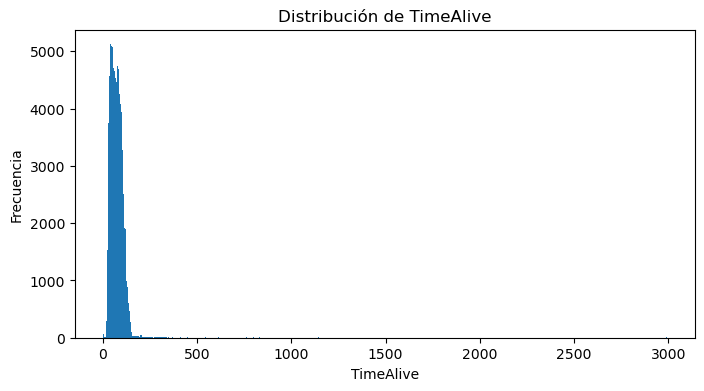

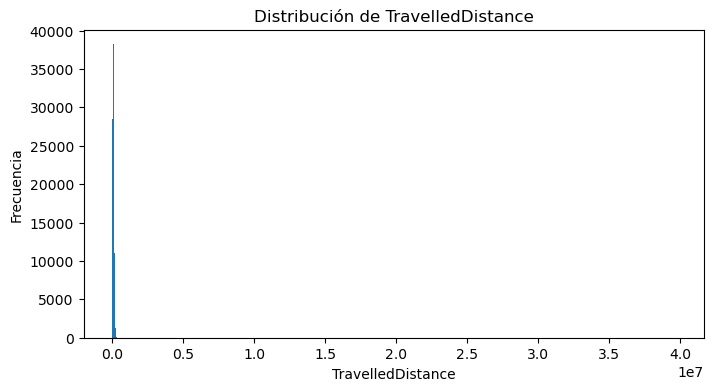

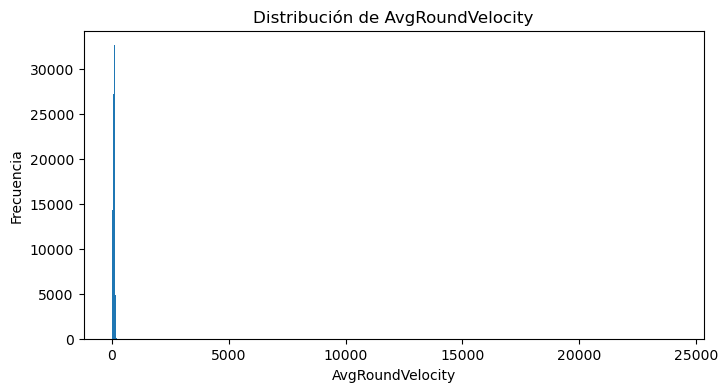

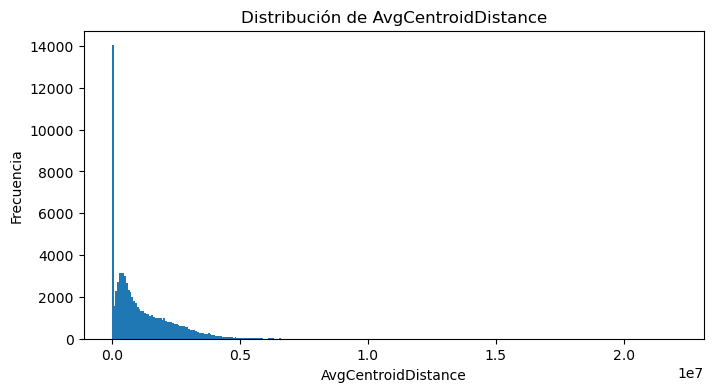

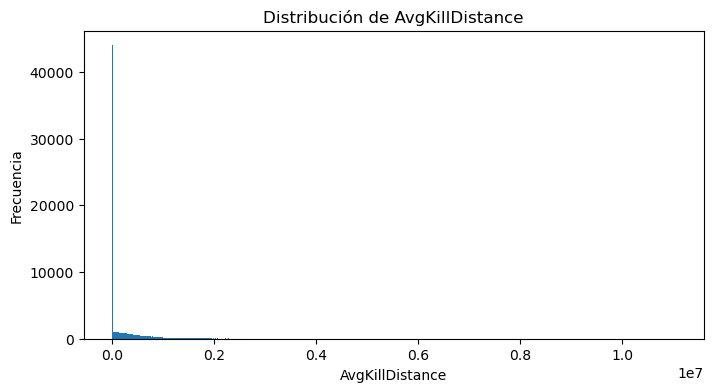

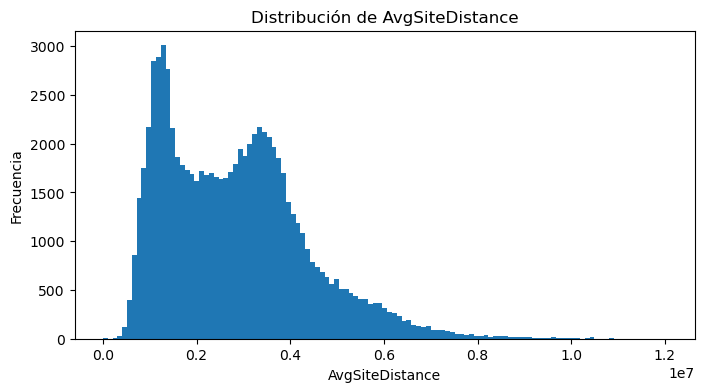

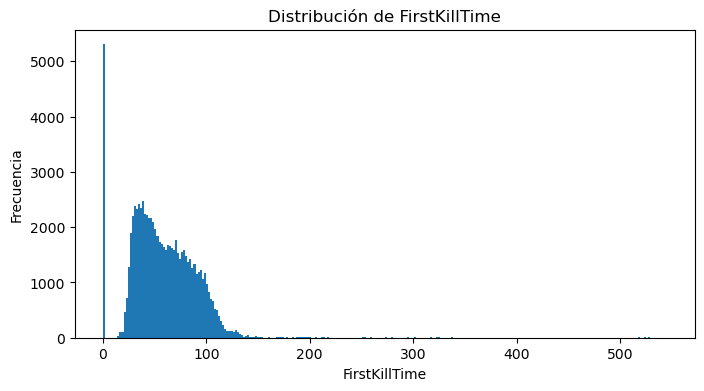

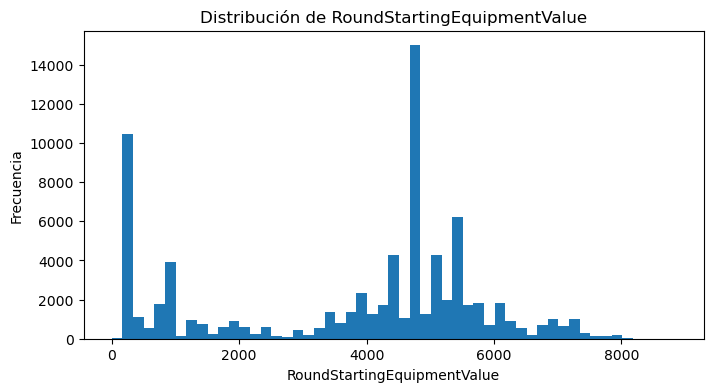

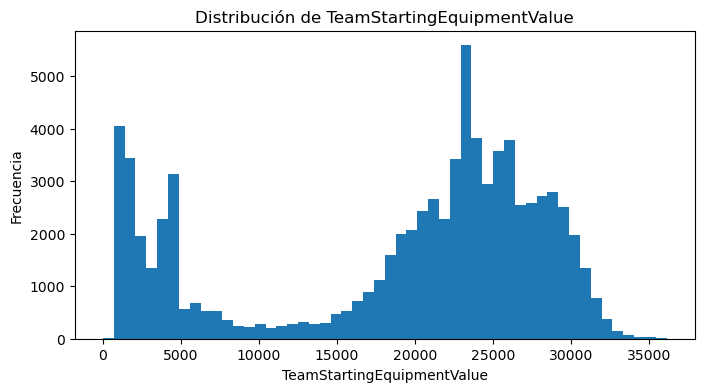

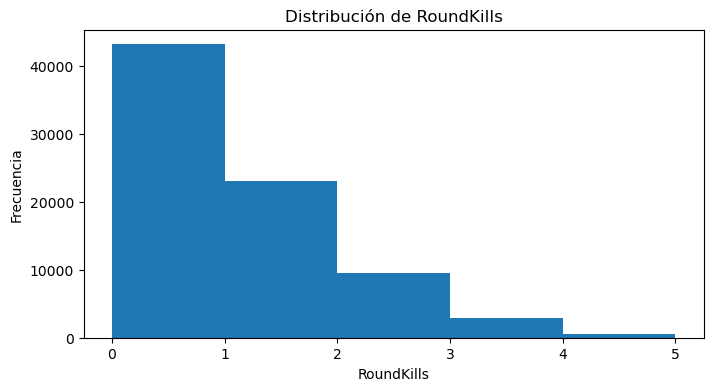

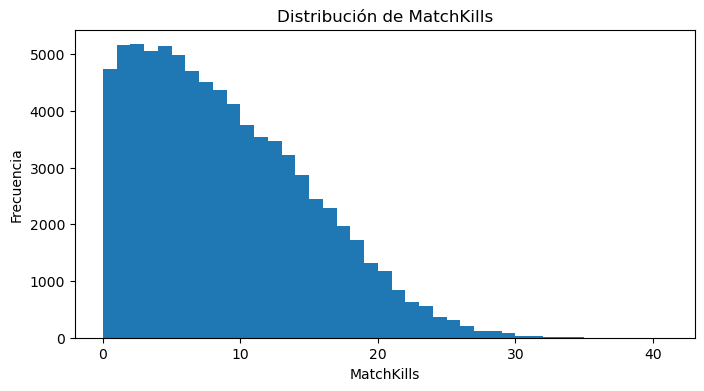

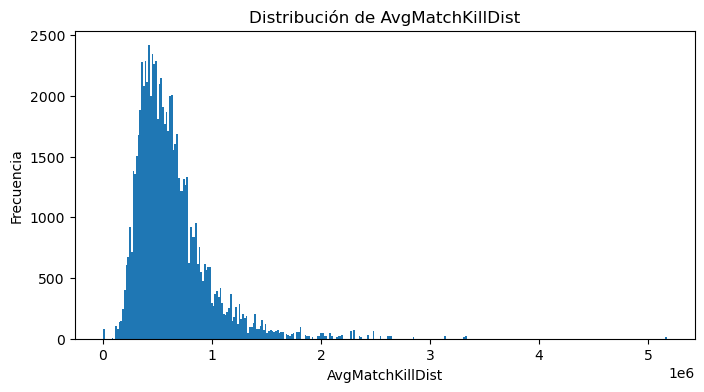

In [19]:
variables_distribucion = [
    c for c in [
        "TimeAlive",
        "TravelledDistance",
        "AvgRoundVelocity",
        "AvgCentroidDistance",
        "AvgKillDistance",
        "AvgSiteDistance",
        "FirstKillTime",
        "RoundStartingEquipmentValue",
        "TeamStartingEquipmentValue",
        "RoundKills",
        "MatchKills",
        "AvgMatchKillDist"
    ]
    if c in df_raw.columns
]

for col in variables_distribucion:
    s = df_raw[col].dropna()

    if len(s) == 0:
        continue

    plt.figure(figsize=(8, 4))
    plt.hist(s, bins="auto")
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

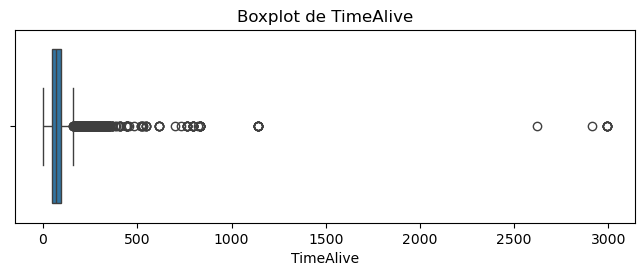

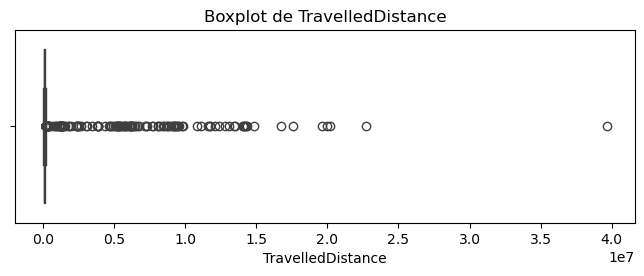

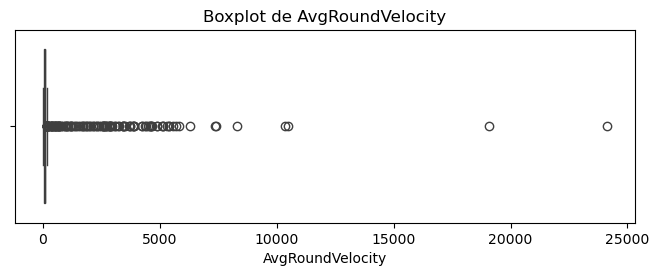

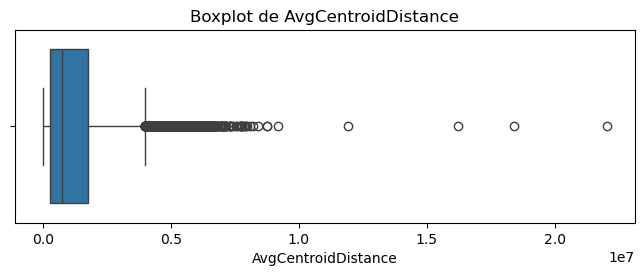

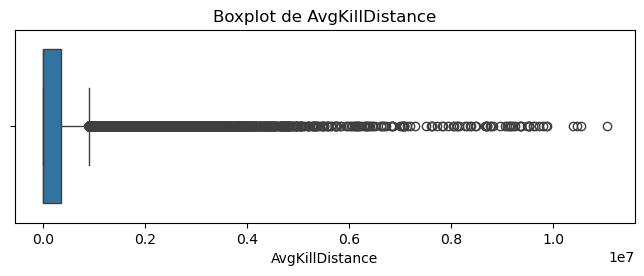

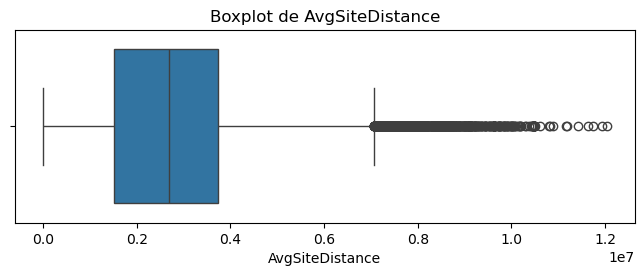

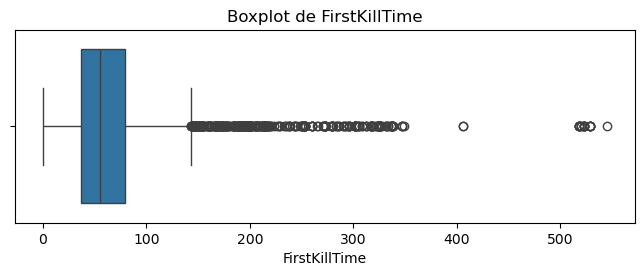

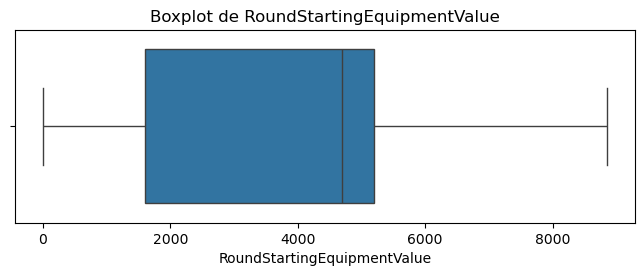

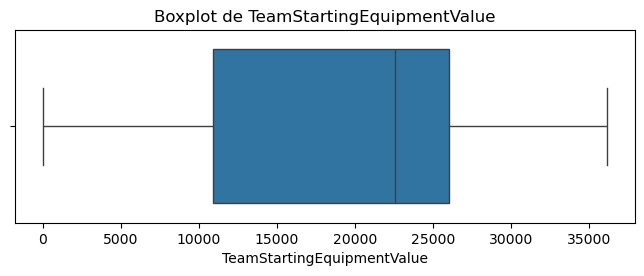

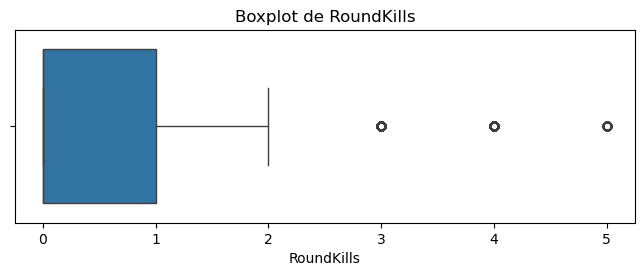

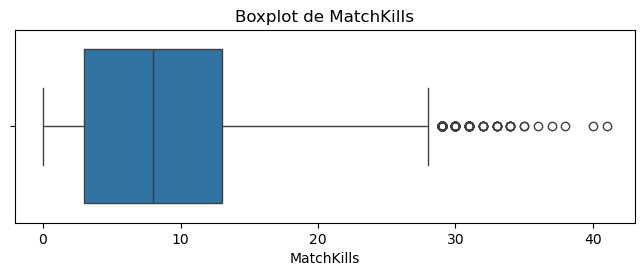

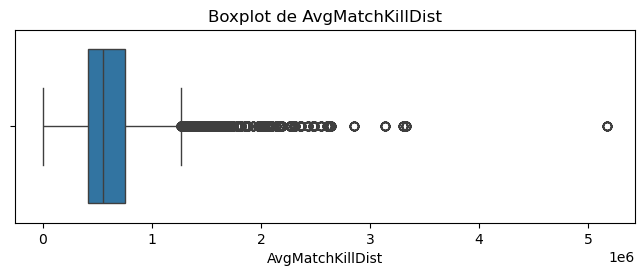

In [20]:
for col in variables_distribucion:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=df_raw[col])
    plt.title(f"Boxplot de {col}")
    plt.show()

### Interpretación de las distribuciones y boxplots

La inspección conjunta de histogramas y boxplots confirma que las variables analizadas presentan comportamientos estadísticos diferentes. Algunas poseen una fuerte asimetría positiva, otras muestran concentraciones importantes en cero, algunas presentan múltiples zonas de concentración y las variables de conteo siguen patrones discretos propios de su naturaleza.

Los puntos ubicados fuera de los bigotes de un boxplot corresponden a **outliers estadísticos según la regla basada en el IQR**, pero no deben interpretarse automáticamente como errores. Su eliminación requerirá posteriormente una evaluación adicional considerando la naturaleza de cada variable y el contexto del problema.

#### `TimeAlive`

El histograma de `TimeAlive`, variable objetivo del problema de regresión, muestra que la mayor parte de las observaciones se concentra en un intervalo relativamente reducido, mientras que existe una cola extensa hacia valores altos.

El boxplot confirma esta situación: la región central se encuentra concentrada aproximadamente entre los cuartiles previamente calculados (`Q1 = 47,08` y `Q3 = 92,65`), pero aparecen numerosas observaciones por encima del límite superior y algunos valores extremadamente alejados, cercanos a 2.600, 2.900 y 3.000.

Este comportamiento coincide con la elevada asimetría positiva obtenida anteriormente (`skewness = 26,97`).

Los valores extremos no serán eliminados automáticamente, ya que primero deberá determinarse si representan observaciones válidas o anomalías. Debido a que `TimeAlive` es el target de regresión, también podría evaluarse posteriormente una transformación que reduzca la asimetría, aunque cualquier cambio sobre el target deberá justificarse considerando su impacto en la interpretación de las predicciones.

#### `TravelledDistance`

`TravelledDistance` presenta una distribución extremadamente asimétrica hacia la derecha. En el histograma, la gran mayoría de los registros queda comprimida cerca del extremo inferior debido a la presencia de observaciones muy elevadas.

El boxplot confirma la existencia de numerosos valores estadísticamente extremos y algunos casos excepcionalmente alejados del comportamiento central, incluyendo un máximo cercano a 39,6 millones.

Este comportamiento es consistente con su `skewness = 47,63`.

Debido a la fuerte asimetría, podría ser útil evaluar posteriormente una transformación como `log1p`, que permite trabajar también con valores iguales a cero. Sin embargo, antes de aplicar una transformación o eliminar registros será necesario verificar que los valores extremos sean válidos dentro del dominio.

#### `AvgRoundVelocity`

`AvgRoundVelocity` presenta un comportamiento similar a `TravelledDistance`. El histograma muestra que prácticamente toda la distribución se concentra en valores relativamente bajos, mientras que algunos registros extremos expanden considerablemente el rango del eje horizontal.

El boxplot identifica una gran cantidad de valores superiores al rango central y algunos casos especialmente alejados, incluyendo observaciones cercanas a 19.000 y 24.000.

La asimetría previamente calculada (`skewness = 69,75`) confirma que la distribución está fuertemente influenciada por estos valores.

Esta variable requiere una revisión especial de sus extremos antes del modelado. En caso de conservarlos, podría evaluarse una transformación para reducir la asimetría. El escalamiento por sí solo modificaría la magnitud de los valores, pero no corregiría esta forma de distribución.

#### `AvgCentroidDistance`

`AvgCentroidDistance` presenta una distribución asimétrica hacia la derecha. El histograma muestra una elevada concentración en valores bajos seguida de una disminución progresiva de la frecuencia a medida que aumenta la distancia.

El boxplot confirma una cola superior extensa y numerosas observaciones por encima del rango definido por el IQR, además de algunos valores excepcionalmente elevados.

Su asimetría positiva (`skewness = 1,45`) es considerablemente menor que la de `TravelledDistance` y `AvgRoundVelocity`, pero sigue evidenciando una distribución no normal.

Podría evaluarse posteriormente una transformación para reducir la asimetría, especialmente si se utiliza un algoritmo sensible a la distribución y escala de las variables.

#### `AvgKillDistance`

`AvgKillDistance` presenta una característica particular: existe una concentración muy elevada exactamente en cero, seguida de una distribución positiva con una larga cola hacia valores altos.

El boxplot también muestra numerosos valores superiores al límite estadístico establecido por el IQR. No obstante, en este caso la interpretación tradicional de outlier debe realizarse con cautela debido a la gran cantidad de ceros y a la propia naturaleza de la variable.

El análisis descriptivo mostró que tanto `Q1` como la mediana son iguales a cero, mientras que `Q3` se encuentra aproximadamente en 360 mil.

Por esta razón, primero deberá determinarse el significado semántico de los ceros. Si representan situaciones válidas, como rondas en las que un jugador no realizó eliminaciones, deberán mantenerse como ceros estructurales y no tratarse como valores faltantes.

Una eventual transformación también deberá considerar explícitamente esta concentración en cero.

#### `AvgSiteDistance`

`AvgSiteDistance` presenta una distribución considerablemente distinta de las anteriores. El histograma permite observar más de una zona de concentración, indicando un comportamiento multimodal, además de una cola hacia valores elevados.

El boxplot muestra un rango intercuartílico amplio y una cantidad apreciable de observaciones por encima del límite superior.

Su asimetría (`skewness = 0,87`) es moderada y bastante menor que la de otras variables de distancia.

La presencia de múltiples concentraciones sugiere que la variable podría estar influenciada por distintos contextos presentes en el dataset. No existe evidencia suficiente para justificar una transformación automática únicamente a partir de su distribución.

En caso de utilizarla posteriormente en un modelo sensible a las diferencias de escala, podría evaluarse su estandarización.

#### `FirstKillTime`

`FirstKillTime` muestra una concentración importante en cero y una distribución positiva para el resto de los registros.

El histograma presenta una mayor frecuencia en tiempos bajos e intermedios y una cola hacia la derecha. El boxplot confirma la presencia de numerosas observaciones superiores al rango central, incluyendo algunos casos cercanos a 500 en las unidades temporales registradas por la fuente.

Su asimetría positiva (`skewness = 1,68`) es consistente con esta forma.

Antes de considerar transformaciones o tratamiento de outliers será necesario determinar el significado del valor cero. No debe suponerse automáticamente que corresponde a un error o a un valor faltante.

#### `RoundStartingEquipmentValue`

`RoundStartingEquipmentValue` presenta una distribución claramente multimodal. El histograma muestra diversos valores de equipamiento que aparecen con una frecuencia mucho mayor que otros, destacando concentraciones específicas alrededor de determinados niveles económicos.

El boxplot muestra una amplia dispersión, pero no identifica observaciones claramente separadas como outliers según la regla del IQR.

El 50 % central de las observaciones se encuentra entre 1.600 y 5.200 y su asimetría es ligeramente negativa (`-0,54`).

La forma de la distribución parece estar asociada a diferentes niveles de equipamiento utilizados al comienzo de una ronda. No existe evidencia suficiente para justificar una transformación destinada a normalizarla.

Sin embargo, debido a que su escala es diferente de otras variables predictoras, podría requerir estandarización si posteriormente se utiliza un algoritmo sensible a la magnitud de las características.

#### `TeamStartingEquipmentValue`

`TeamStartingEquipmentValue` también presenta una estructura multimodal. El histograma muestra una concentración importante en valores económicos bajos y otra región de alta densidad aproximadamente entre 20.000 y 30.000.

El boxplot confirma una dispersión amplia, pero no muestra outliers destacados mediante la regla del IQR.

El 50 % central se encuentra entre 10.900 y 26.050 y la distribución presenta asimetría negativa moderada (`-0,74`).

Al igual que `RoundStartingEquipmentValue`, no parece necesario transformar esta variable buscando una distribución normal. No obstante, su escala considerablemente mayor respecto de otras características podría justificar una estandarización dependiendo del algoritmo utilizado posteriormente.

#### `RoundKills`

`RoundKills` corresponde a una variable de conteo discreta. El histograma muestra una concentración muy elevada en cero y una disminución progresiva de la frecuencia a medida que aumenta la cantidad de eliminaciones.

El boxplot identifica los valores 3, 4 y 5 como observaciones estadísticamente extremas. Sin embargo, estos valores se encuentran dentro del rango posible de la variable y no deben interpretarse automáticamente como errores.

Este ejemplo demuestra una limitación de aplicar mecánicamente la regla del IQR sobre variables de conteo.

Por su naturaleza discreta y rango reducido, `RoundKills` debe analizarse principalmente mediante frecuencias y proporciones. No existe una justificación evidente para aplicar una transformación de normalización ni para eliminar sus valores altos.

#### `MatchKills`

`MatchKills` presenta una distribución de conteo con mayor concentración en cantidades bajas y medias de eliminaciones y una cola progresiva hacia valores superiores.

El boxplot identifica como outliers estadísticos algunos registros aproximadamente desde los 29 kills en adelante, llegando hasta un máximo de 41.

Sin embargo, debido a que la variable acumula eliminaciones durante toda la partida, los valores altos pueden representar desempeños poco frecuentes pero válidos. Por lo tanto, tampoco deben eliminarse únicamente por aparecer fuera de los bigotes del boxplot.

Además, `MatchKills` será utilizada sólo para caracterización descriptiva en relación con el problema de clasificación, ya que contiene información acumulada durante la partida y no estará disponible en el instante definido para predecir `MatchWinner`.

#### `AvgMatchKillDist`

`AvgMatchKillDist` presenta una distribución claramente asimétrica hacia la derecha. La mayor parte de las observaciones se concentra en valores bajos e intermedios, seguida de una cola prolongada hacia valores elevados.

El boxplot confirma numerosos outliers estadísticos por sobre el límite superior, además de algunas observaciones considerablemente alejadas de la distribución principal, incluyendo un máximo superior a 5 millones.

Este comportamiento coincide con su asimetría positiva (`skewness = 2,54`).

Desde el punto de vista estrictamente estadístico podría evaluarse posteriormente una transformación para reducir esta asimetría. Sin embargo, al representar información asociada al desempeño acumulado de la partida, no será utilizada como predictor de `MatchWinner` cuando corresponda a información posterior al instante definido para la predicción.

### Conclusión de las distribuciones

La inspección conjunta de histogramas y boxplots confirma que no existe una única distribución representativa para todas las variables numéricas del dataset.

`TimeAlive`, `TravelledDistance`, `AvgRoundVelocity`, `AvgCentroidDistance`, `AvgKillDistance`, `FirstKillTime` y `AvgMatchKillDist` presentan distintos grados de asimetría positiva y valores estadísticamente extremos. Entre ellas, `TravelledDistance` y `AvgRoundVelocity` destacan por la magnitud excepcional de algunos registros, por lo que requerirán una revisión específica antes de cualquier decisión de eliminación o transformación.

`AvgKillDistance` y `FirstKillTime` presentan además concentraciones relevantes en cero, cuyo significado debe ser validado antes de considerar esos valores como anomalías.

`RoundStartingEquipmentValue` y `TeamStartingEquipmentValue` presentan distribuciones multimodales asociadas a distintos niveles de equipamiento. Sus boxplots no muestran valores extremos evidentes bajo la regla del IQR, por lo que no existe fundamento estadístico para eliminar observaciones de estas variables en esta etapa.

Las variables de conteo, como `RoundKills` y `MatchKills`, muestran que un outlier estadístico no necesariamente corresponde a una observación incorrecta. Sus valores deberán interpretarse considerando los límites y características propias del juego.

En consecuencia, los outliers detectados mediante boxplots serán considerados inicialmente como señales para investigación y no como registros que deban eliminarse automáticamente. El análisis mediante IQR se utilizará como herramienta de detección, complementándolo con la naturaleza de cada variable y el conocimiento del dominio.

Finalmente, cualquier escalamiento se decidirá durante la preparación de los datos según las características seleccionadas y el algoritmo que posteriormente se utilice. La estandarización puede permitir que variables con escalas muy diferentes sean comparables para determinados modelos, pero no elimina la asimetría ni corrige por sí sola la presencia de valores extremos. Para las variables fuertemente asimétricas podrán evaluarse transformaciones específicas, como `log1p`, siempre que sean compatibles con su significado y con la presencia de valores iguales a cero.

## 2.8 Missing values

In [21]:
missing = pd.DataFrame({
    "cantidad": df_raw.isna().sum(),
    "porcentaje": df_raw.isna().mean() * 100
})

missing = missing[missing["cantidad"] > 0].sort_values("porcentaje", ascending=False)
display(missing)

,cantidad,porcentaje


In [22]:
# Revisar las filas con al menos un missing value.
filas_missing = df_raw[df_raw.isna().any(axis=1)]
print("Filas con al menos un missing:", len(filas_missing))
display(filas_missing.head(30))

Filas con al menos un missing: 0


,Unnamed: 0,Map,Team,InternalTeamId,MatchId,RoundId,SteamId,RoundWinner,MatchWinner,Survived,AbnormalMatch,TimeAlive,ScaledTimeAlive,AvgCentroidDistance,TravelledDistance,AvgRoundVelocity,AvgKillDistance,AvgSiteDistance,RLethalGrenadesThrown,RNonLethalGrenadesThrown,PrimaryAssaultRifle,PrimarySniperRifle,PrimaryHeavy,PrimarySMG,PrimaryPistol,FirstKillTime,RoundKills,RoundAssists,RoundHeadshots,RoundFlankKills,RoundStartingEquipmentValue,TeamStartingEquipmentValue,MatchKills,MatchFlankKills,MatchAssists,MatchHeadshots,AvgMatchKillDist


### Interpretación

La revisión de valores faltantes confirma que el dataset completo no presenta `missing values` en ninguna de sus variables.

Además, no se identificó ninguna fila con al menos un valor ausente, por lo que las 79.157 observaciones se encuentran completas desde el punto de vista de disponibilidad de datos.

En consecuencia, durante la fase de preparación no será necesario aplicar técnicas de imputación, eliminación de registros por valores faltantes ni estrategias de recuperación de información.

Este resultado permite concentrar el tratamiento de calidad en otros aspectos detectados previamente, como las inconsistencias de `Team`, la presencia de variables constantes, la prevención de *data leakage* y el análisis de valores extremos.

## 2.9 Detección de outliers — IQR

In [23]:
def detectar_outliers_iqr(serie):
    s = pd.to_numeric(serie, errors="coerce").dropna()

    if len(s) == 0:
        return {
            "q1": np.nan, "q3": np.nan, "iqr": np.nan,
            "limite_inf": np.nan, "limite_sup": np.nan,
            "n_outliers": 0, "pct_outliers": 0
        }

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr

    mask = (serie < limite_inf) | (serie > limite_sup)

    return {
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "limite_inf": limite_inf,
        "limite_sup": limite_sup,
        "n_outliers": int(mask.sum()),
        "pct_outliers": float(mask.mean() * 100)
    }

outlier_candidates = [
    c for c in [
        "TimeAlive", "TravelledDistance", "AvgRoundVelocity",
        "AvgCentroidDistance", "AvgKillDistance", "AvgSiteDistance",
        "FirstKillTime",
        "RoundStartingEquipmentValue", "TeamStartingEquipmentValue",
        "RLethalGrenadesThrown", "RNonLethalGrenadesThrown",
        "RoundKills", "RoundAssists", "RoundHeadshots",
        "RoundFlankKills", "MatchKills", "MatchFlankKills",
        "MatchAssists", "MatchHeadshots", "AvgMatchKillDist"
    ]
    if c in df_raw.columns
]

outliers_iqr = pd.DataFrame({
    col: detectar_outliers_iqr(df_raw[col])
    for col in outlier_candidates
}).T

display(outliers_iqr.sort_values("pct_outliers", ascending=False))

,q1,q3,iqr,limite_inf,limite_sup,n_outliers,pct_outliers
RoundHeadshots,0.0000,0.0000,0.0000,0.0000,0.0000,"19,582.0000",24.7382
RoundAssists,0.0000,0.0000,0.0000,0.0000,0.0000,"10,692.0000",13.5073
AvgKillDistance,0.0000,"360,339.4116","360,339.4116","-540,509.1174","900,848.5291","7,616.0000",9.6214
RoundFlankKills,0.0000,0.0000,0.0000,0.0000,0.0000,"6,962.0000",8.7952
AvgMatchKillDist,"409,779.0093","752,456.8127","342,677.8034","-104,237.6959","1,266,473.5178","3,733.0000",4.7159
RoundKills,0.0000,1.0000,1.0000,-1.5000,2.5000,"3,505.0000",4.4279
AvgCentroidDistance,"257,882.5179","1,753,171.7237","1,495,289.2059","-1,985,051.2910","3,996,105.5325","1,707.0000",2.1565
TravelledDistance,"58,982.5483","121,396.6206","62,414.0724","-34,638.5603","215,017.7292","1,262.0000",1.5943
MatchFlankKills,0.0000,2.0000,2.0000,-3.0000,5.0000,"1,184.0000",1.4958
AvgSiteDistance,"1,508,094.6700","3,728,018.2542","2,219,923.5842","-1,821,790.7064","7,057,903.6305",959.0000,1.2115


In [24]:
# Mostrar los valores extremos de cada variable sin eliminarlos.
for col in outlier_candidates:
    info = outliers_iqr.loc[col]
    li = info["limite_inf"]
    ls = info["limite_sup"]

    extremos = df_raw.loc[
        (df_raw[col] < li) | (df_raw[col] > ls),
        col
    ]

    if len(extremos) > 0:
        print(f"\n{col}: {len(extremos)} valores marcados por IQR")
        display(extremos.value_counts().sort_index().tail(15))


TimeAlive: 594 valores marcados por IQR


TimeAlive
523.3897      1
528.8206      1
530.9304      1
545.0349      4
615.3953      5
697.7607      1
731.0946      1
761.1765      7
798.2814      9
824.4196      1
830.5380      9
1,143.0997    9
2,621.4845    1
2,914.3728    1
2,990.5604    7
Name: count, dtype: int64


TravelledDistance: 1262 valores marcados por IQR


TravelledDistance
13,513,438.5560    1
14,055,447.6142    1
14,068,039.4964    1
14,156,058.3586    1
14,187,645.0035    1
14,250,085.4903    1
14,325,421.6295    1
14,866,848.6324    1
16,730,628.5872    1
17,551,262.8185    1
19,605,695.2907    1
19,968,432.5937    1
20,207,622.5631    1
22,704,056.5863    1
39,646,454.2725    1
Name: count, dtype: int64


AvgRoundVelocity: 142 valores marcados por IQR


...

MatchAssists
8     496
9     190
10     61
11     27
12      3
14      4
Name: count, dtype: int64


MatchHeadshots: 724 valores marcados por IQR


MatchHeadshots
14    269
15    192
16    121
17     64
18     49
19     19
20      5
21      4
22      1
Name: count, dtype: int64


AvgMatchKillDist: 3733 valores marcados por IQR


AvgMatchKillDist
2,360,013.7927    20
2,366,830.6921    16
2,427,764.7865    32
2,475,230.5157    25
2,481,948.9871    21
2,486,799.8016    16
2,551,619.3494    22
2,606,115.4832    23
2,622,850.7856    24
2,638,337.5693    23
2,855,280.1552    18
3,132,213.2644    20
3,304,952.6821    15
3,326,844.4233    24
5,170,167.5835    16
Name: count, dtype: int64

### Interpretación de la detección de outliers mediante IQR

La regla del rango intercuartílico (IQR) permitió identificar observaciones estadísticamente alejadas del 50 % central de cada variable. Sin embargo, la cantidad de registros detectados varía considerablemente según la naturaleza y distribución de cada característica.

Es importante distinguir entre un **outlier estadístico** y un **error de datos**. Una observación puede encontrarse fuera de los límites definidos por `Q1 - 1,5 × IQR` y `Q3 + 1,5 × IQR` y, aun así, representar un valor válido dentro del dominio. Por esta razón, los resultados del IQR se utilizarán como mecanismo de detección y revisión, y no como una regla automática de eliminación.

#### Variables continuas

Entre las variables continuas, `AvgKillDistance` presenta la mayor proporción de observaciones marcadas por IQR, con 7.616 registros, equivalentes al 9,62 % del dataset. Su límite superior se encuentra aproximadamente en 900.849, mientras que existen valores que superan los 11 millones.

Este resultado debe interpretarse considerando que la variable presenta una elevada concentración en cero y una distribución fuertemente asimétrica hacia la derecha. Por lo tanto, la gran cantidad de observaciones marcadas no implica necesariamente una alta proporción de errores.

`AvgMatchKillDist` presenta 3.733 valores marcados, correspondientes al 4,72 %, mientras que `AvgCentroidDistance` presenta 1.707 registros (2,16 %), `TravelledDistance` 1.262 (1,59 %) y `AvgSiteDistance` 959 (1,21 %).

En `TravelledDistance` se observan valores extremadamente elevados, alcanzando aproximadamente 39,6 millones. Del mismo modo, `AvgCentroidDistance` llega a aproximadamente 22 millones. Estos casos deberán inspeccionarse con mayor detalle antes de decidir si representan anomalías o situaciones válidas poco frecuentes.

`TimeAlive`, target del problema de regresión, presenta 594 observaciones fuera de los límites IQR, equivalentes únicamente al 0,75 % de los registros. El límite superior calculado es aproximadamente 161, mientras que algunos valores extremos alcanzan 2.990,56.

Aunque porcentualmente son pocos registros, su magnitud explica la elevada asimetría observada previamente. Debido a que `TimeAlive` será la variable objetivo, estos casos no se eliminarán automáticamente. Se deberá determinar si corresponden a observaciones válidas antes de considerar alguna estrategia de tratamiento.

`FirstKillTime` presenta 488 valores marcados por IQR (0,62 %) y `AvgRoundVelocity` 142 (0,18 %). En ambos casos existen observaciones significativamente superiores a la distribución central, por lo que será necesario revisar su plausibilidad antes de aplicar cualquier tratamiento.

#### Variables económicas

`RoundStartingEquipmentValue` y `TeamStartingEquipmentValue` no presentan observaciones clasificadas como outliers mediante la regla del IQR.

En `RoundStartingEquipmentValue`, el límite superior calculado es 10.600, por encima del máximo observado de 8.850. En `TeamStartingEquipmentValue`, el límite superior alcanza 48.775, mientras que el máximo observado es 36.150.

Por lo tanto, no existe evidencia basada en IQR que justifique eliminar o recortar observaciones de estas variables económicas. La dispersión y multimodalidad observadas anteriormente forman parte de su distribución y no corresponden a valores estadísticamente aislados según este criterio.

#### Variables de conteo

Las variables de conteo muestran claramente una limitación del método IQR cuando existe una elevada concentración en cero.

`RoundHeadshots` presenta 19.582 registros marcados como outliers, equivalentes al 24,74 % del dataset. Esto ocurre porque `Q1 = 0` y `Q3 = 0`, por lo que el IQR también es cero y cualquier valor positivo queda automáticamente fuera del límite superior.

La misma situación ocurre en `RoundAssists`, donde 10.692 observaciones (13,51 %) son clasificadas como outliers, y en `RoundFlankKills`, con 6.962 registros (8,80 %).

Estos porcentajes no indican que una cuarta parte del dataset contenga errores. Por ejemplo, en `RoundHeadshots`, valores de 1, 2, 3, 4 o 5 son posibles dentro de una ronda, aunque sean menos frecuentes que cero.

`RoundKills` presenta 3.505 observaciones marcadas (4,43 %), correspondientes a valores de 3, 4 y 5 eliminaciones. Estos valores se encuentran dentro del rango lógico de la variable, por lo que deben considerarse eventos poco frecuentes pero potencialmente válidos.

De forma similar, `RLethalGrenadesThrown` marca 98 observaciones con valores de 3 o 4, mientras que `RNonLethalGrenadesThrown` identifica únicamente 15 registros con valor 6. Estos casos deberán analizarse considerando los límites reales del juego y no exclusivamente mediante criterios estadísticos.

#### Estadísticas acumuladas de partida

Las variables acumuladas de partida presentan porcentajes relativamente bajos de outliers bajo IQR.

`MatchKills` identifica 162 observaciones (0,20 %) por encima de 28 kills, alcanzando un máximo de 41. `MatchAssists`, `MatchHeadshots` y `MatchFlankKills` presentan respectivamente 0,99 %, 0,91 % y 1,50 % de observaciones marcadas.

Estos valores pueden corresponder a desempeños excepcionales pero válidos, especialmente porque representan estadísticas acumuladas durante una partida completa.

Además, estas variables no serán utilizadas como predictores en el problema de clasificación de `MatchWinner` cuando correspondan a información generada después del instante definido para realizar la predicción, por lo que su presencia como valores extremos tiene principalmente interés descriptivo.

### Decisión metodológica sobre outliers

Los resultados muestran que la aplicación del IQR debe realizarse de forma diferenciada según la naturaleza de cada variable.

Se considerarán tres situaciones:

1. **Valor imposible o inconsistente con el dominio:** se investigará como posible error de datos y podrá corregirse o excluirse si existe evidencia suficiente.

2. **Valor extremo pero plausible:** se conservará inicialmente, ya que puede representar información válida y relevante del comportamiento observado.

3. **Valor extremo válido que afecta fuertemente el modelado:** podrá evaluarse posteriormente mediante transformaciones, winsorización, escalamiento robusto o algoritmos menos sensibles a valores extremos.

En las variables continuas fuertemente asimétricas, como `TravelledDistance`, `AvgRoundVelocity`, `AvgCentroidDistance` o `AvgKillDistance`, podrá evaluarse posteriormente una transformación adecuada, siempre que respete el significado de la variable.

En las variables de conteo no se utilizará el IQR como criterio automático de eliminación, ya que distribuciones concentradas en cero pueden hacer que valores perfectamente válidos sean clasificados como outliers.

En consecuencia, **ningún registro será eliminado únicamente por haber sido identificado como outlier mediante la regla del IQR**. La decisión final combinará distribución, frecuencia, plausibilidad dentro del dominio y relevancia para cada problema predictivo.

## 2.10 Z-score sólo en variables aproximadamente gaussianas



RoundStartingEquipmentValue outliers |z| > 3: 0

### RoundStartingEquipmentValue
Media: 3778.1087
Mediana: 4700.0000
Skewness: -0.5366
Kurtosis: -0.9593


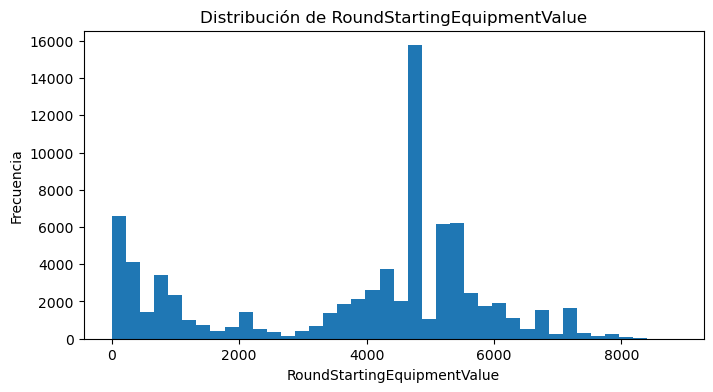

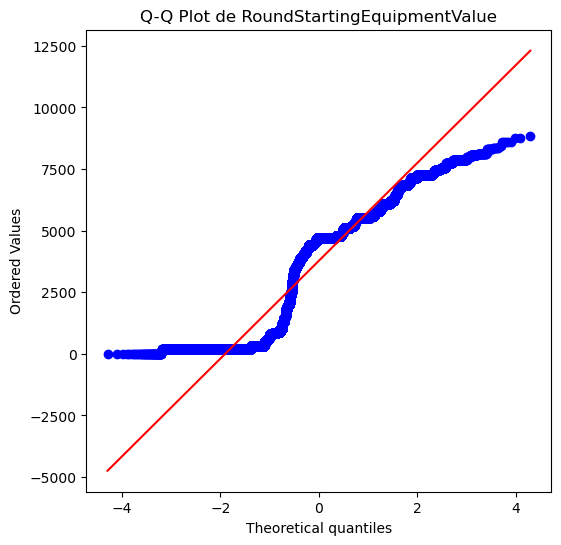

TeamStartingEquipmentValue outliers |z| > 3: 0

### TeamStartingEquipmentValue
Media: 18890.1335
Mediana: 22550.0000
Skewness: -0.7408
Kurtosis: -0.8931


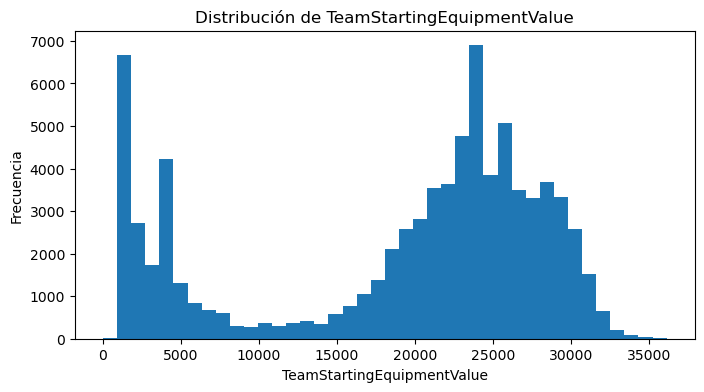

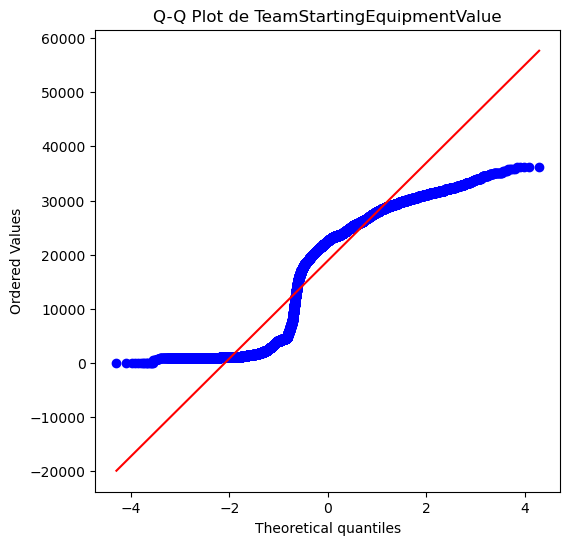

AvgSiteDistance outliers |z| > 3: 656

### AvgSiteDistance
Media: 2828656.6397
Mediana: 2699213.6893
Skewness: 0.8710
Kurtosis: 0.9400


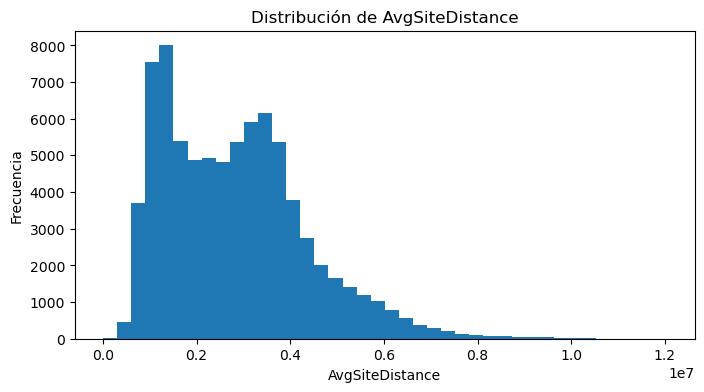

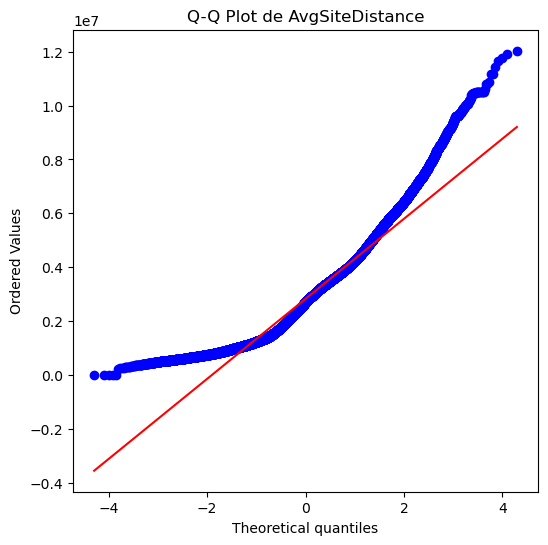

In [25]:
# Diagnóstico de distribución y valores alejados de la media en las variables seleccionadas.
variables_zscore = ["RoundStartingEquipmentValue", "TeamStartingEquipmentValue", "AvgSiteDistance"]

for col in variables_zscore:
    z = np.abs(stats.zscore(df_raw[col].dropna()))
    print(col, "outliers |z| > 3:", (z > 3).sum())

    datos = df_raw[col].dropna()

    print(f"\n### {col}")
    print(f"Media: {datos.mean():.4f}")
    print(f"Mediana: {datos.median():.4f}")
    print(f"Skewness: {datos.skew():.4f}")
    print(f"Kurtosis: {datos.kurtosis():.4f}")

    # Histograma
    plt.figure(figsize=(8, 4))
    plt.hist(datos, bins=40)
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

    # Q-Q Plot
    plt.figure(figsize=(6, 6))
    stats.probplot(datos, dist="norm", plot=plt)
    plt.title(f"Q-Q Plot de {col}")
    plt.show()

### Interpretación de la evaluación mediante Z-score

El análisis mediante histogramas, medidas de forma y Q-Q plots muestra que ninguna de las tres variables evaluadas presenta un comportamiento suficientemente cercano a una distribución normal como para utilizar Z-score como criterio principal de eliminación de outliers.

El objetivo de esta evaluación no es eliminar automáticamente las observaciones con `|z| > 3`, sino comprobar si la forma de las distribuciones permite interpretar ese umbral de manera adecuada.

#### `RoundStartingEquipmentValue`

`RoundStartingEquipmentValue` presenta una media aproximada de 3.778, una mediana de 4.700 y una asimetría negativa moderada (`skewness = -0,54`).

Aunque el valor de asimetría no es extremo, el histograma muestra claramente múltiples concentraciones de frecuencia en determinados niveles de equipamiento. Por lo tanto, la distribución no presenta una forma de campana simétrica y puede considerarse multimodal.

El Q-Q plot refuerza esta conclusión, ya que los puntos se separan marcadamente de la recta teórica de normalidad y forman una estructura escalonada.

El cálculo mediante Z-score no detectó observaciones con `|z| > 3`. Este resultado es coherente con el análisis mediante IQR, donde tampoco se identificaron outliers para esta variable.

Sin embargo, la ausencia de valores con `|z| > 3` no implica que la distribución sea normal. En este caso, la principal característica de la variable es su estructura multimodal, probablemente relacionada con distintos niveles de equipamiento al comienzo de las rondas.

#### `TeamStartingEquipmentValue`

`TeamStartingEquipmentValue` presenta una media aproximada de 18.890, una mediana de 22.550 y una asimetría negativa de `-0,74`.

Al igual que en la variable anterior, el histograma muestra más de una zona de concentración. Se observa un grupo importante de valores económicos bajos y otro grupo de alta frecuencia aproximadamente entre 20.000 y 30.000.

El Q-Q plot presenta una desviación pronunciada respecto de la recta de referencia, especialmente en ambos extremos, demostrando que la distribución tampoco puede considerarse aproximadamente normal.

El método Z-score no identificó observaciones con `|z| > 3`, resultado que nuevamente coincide con el análisis mediante IQR, donde tampoco se detectaron outliers.

Por lo tanto, aunque no existen valores extremadamente alejados de la media en términos de desviaciones estándar, la distribución multimodal hace que Z-score no sea el criterio más adecuado para caracterizar esta variable.

#### `AvgSiteDistance`

`AvgSiteDistance` presenta una media aproximada de 2,83 millones, una mediana cercana a 2,70 millones y una asimetría positiva moderada (`skewness = 0,87`).

El histograma muestra varias zonas de concentración y una cola hacia valores elevados. A diferencia de las variables económicas, su distribución presenta una mayor extensión hacia la derecha.

El Q-Q plot muestra una desviación sistemática respecto de la línea teórica, especialmente en las colas. Los puntos forman una curvatura claramente visible, indicando que los datos no siguen adecuadamente una distribución normal.

Mediante el criterio `|z| > 3` se identificaron 656 observaciones alejadas de la media en más de tres desviaciones estándar.

Sin embargo, debido a que la distribución no es normal, estas 656 observaciones no deben interpretarse automáticamente como errores ni como registros que deban eliminarse. El resultado únicamente indica que se encuentran alejadas de la media en términos de desviaciones estándar.

Además, el análisis mediante IQR identificó 959 observaciones fuera de sus límites, mostrando que distintos criterios estadísticos pueden producir cantidades diferentes de valores extremos cuando la distribución no es normal.

### Comparación entre IQR y Z-score

Los resultados muestran que el método utilizado para detectar valores extremos puede producir conclusiones diferentes dependiendo de la forma de la distribución.

En `RoundStartingEquipmentValue` y `TeamStartingEquipmentValue`, tanto IQR como Z-score identificaron cero outliers. Sin embargo, los histogramas y Q-Q plots demuestran que estas variables no son normales, sino que presentan estructuras multimodales.

En `AvgSiteDistance`, el método IQR identificó 959 observaciones, mientras que Z-score identificó 656 con `|z| > 3`. Esta diferencia no implica que uno de los métodos sea incorrecto, sino que utilizan criterios distintos para definir una observación extrema.

Dado que las distribuciones analizadas se alejan de la normalidad, el método Z-score no se utilizará como criterio principal para eliminar observaciones.

### Decisión metodológica

La detección de outliers se apoyará principalmente en el método IQR para variables continuas, complementado con histogramas, boxplots y análisis del contexto de cada característica.

El Z-score se conserva en este análisis como herramienta comparativa, pero no será utilizado automáticamente para eliminar registros debido a que las variables evaluadas no cumplen adecuadamente con el supuesto de una distribución aproximadamente normal.

Además, una observación identificada como extrema por cualquiera de estos métodos será considerada inicialmente como un registro para revisión y no como un error confirmado.

Finalmente, debe distinguirse la detección de outliers del escalamiento. La estandarización mediante `StandardScaler` puede utilizarse posteriormente en determinados algoritmos aunque una variable no sea normal; estandarizar modifica su centro y escala, pero no transforma una distribución no normal en una distribución normal ni elimina sus valores extremos.

## 2.11 Correlación entre variables numéricas

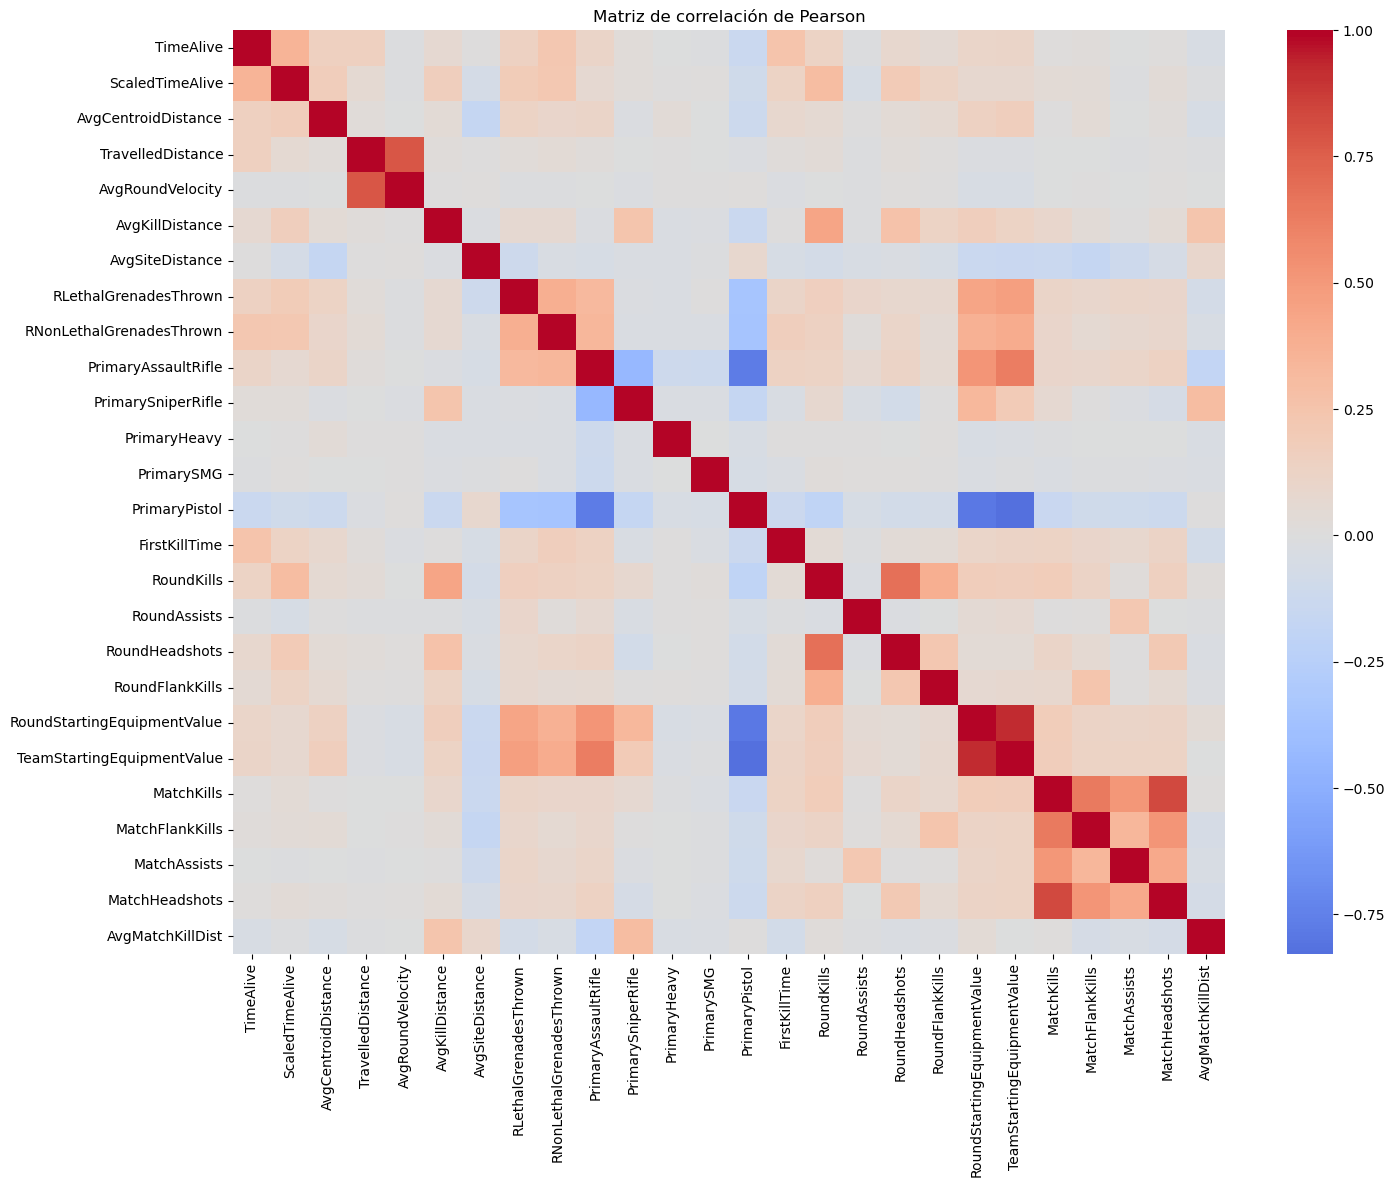


Correlaciones lineales con TimeAlive:


,corr_TimeAlive
ScaledTimeAlive,0.3503
FirstKillTime,0.2568
RNonLethalGrenadesThrown,0.2307
TravelledDistance,0.1537
AvgCentroidDistance,0.1517
RLethalGrenadesThrown,0.1491
PrimaryPistol,-0.1395
RoundKills,0.1277
PrimaryAssaultRifle,0.1134
TeamStartingEquipmentValue,0.1077


In [26]:
corr_cols = [
    c for c in numericas_analisis
    if df_raw[c].nunique(dropna=True) > 1
]

corr = df_raw[corr_cols].corr(method="pearson")

plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Matriz de correlación de Pearson")
plt.show()

if "TimeAlive" in corr.columns:
    print("\nCorrelaciones lineales con TimeAlive:")
    display(
        corr["TimeAlive"]
        .drop("TimeAlive")
        .sort_values(key=lambda s: s.abs(), ascending=False)
        .to_frame("corr_TimeAlive")
    )

### Interpretación de la correlación entre variables numéricas

La matriz de correlación de Pearson muestra que no existen variables con una relación lineal fuerte con `TimeAlive`.

La correlación más alta corresponde a `ScaledTimeAlive` (`r = 0,3503`). Sin embargo, esta variable fue auditada previamente y se comprobó que aproximadamente el 99,43 % de sus valores son compatibles con una transformación directamente relacionada con `TimeAlive`. Por esta razón, no será utilizada como predictor del problema de regresión debido al riesgo de *data leakage*.

Entre las variables restantes, `FirstKillTime` presenta la mayor correlación positiva con `TimeAlive` (`r = 0,2568`), seguida por `RNonLethalGrenadesThrown` (`r = 0,2307`). También se observan asociaciones positivas débiles con `TravelledDistance` (`r = 0,1537`), `AvgCentroidDistance` (`r = 0,1517`) y `RLethalGrenadesThrown` (`r = 0,1491`).

No obstante, estas variables representan información generada durante el desarrollo de la ronda. Como el problema de regresión busca estimar `TimeAlive` utilizando información disponible antes o al inicio de la ronda, estas características no deberán incorporarse como predictores aunque presenten cierta asociación estadística con el target.

`RoundKills` también presenta una correlación positiva débil (`r = 0,1277`), pero corresponde a un resultado generado durante la ronda y, por lo tanto, también sería una fuente de información futura respecto del instante de predicción.

Entre las variables potencialmente disponibles al comienzo de la ronda, las asociaciones con `TimeAlive` son débiles. `PrimaryPistol` presenta una relación negativa (`r = -0,1395`), mientras que `PrimaryAssaultRifle` muestra una relación positiva de `r = 0,1134`.

Las variables económicas también presentan asociaciones positivas débiles: `TeamStartingEquipmentValue` alcanza `r = 0,1077` y `RoundStartingEquipmentValue` `r = 0,1043`. Estos valores sugieren que podría existir una relación entre el nivel de equipamiento inicial y el tiempo de supervivencia, aunque la intensidad de la relación lineal individual es reducida.

Otras variables presentan correlaciones muy cercanas a cero. Por ejemplo, `AvgSiteDistance` obtiene `r = 0,0026`, `PrimaryHeavy` `r = -0,0015`, `MatchAssists` `r = -0,0058` y `PrimarySMG` `r = -0,0073`. Esto indica que no existe una asociación lineal relevante con `TimeAlive` al analizar cada variable de forma individual.

Sin embargo, una correlación cercana a cero no implica que una característica carezca necesariamente de utilidad predictiva. El coeficiente de Pearson sólo mide asociación lineal entre dos variables y no captura relaciones no lineales, interacciones entre múltiples características ni efectos condicionados por variables como el mapa, el lado o la economía disponible.

Además, `TimeAlive` presenta una distribución fuertemente asimétrica y contiene valores extremos, por lo que los coeficientes de Pearson deben interpretarse con cautela, ya que esta métrica puede verse influenciada por observaciones alejadas de la distribución central.

### Implicancias para el problema de regresión

El análisis de correlación no justifica seleccionar o eliminar variables únicamente en función de su coeficiente de Pearson.

La selección final de predictores se realizará considerando principalmente:

- la disponibilidad temporal de la variable en el momento de realizar la predicción;
- el riesgo de *data leakage*;
- su significado dentro del problema;
- y posteriormente su contribución al desempeño de un modelo multivariable.

En consecuencia, variables como `ScaledTimeAlive`, `FirstKillTime`, `TravelledDistance`, `RoundKills` y otras estadísticas generadas durante o después de la ronda no serán utilizadas como predictores de `TimeAlive`, incluso cuando presenten una correlación mayor que las variables disponibles al inicio.

Por el contrario, características como `Map`, `Team`, `RoundId`, `RoundStartingEquipmentValue` y `TeamStartingEquipmentValue` podrán mantenerse como candidatas debido a que representan información disponible antes o al inicio de la ronda y no introducen información futura sobre el target.

## 2.12 Distribución de targets preliminares


### MatchWinner


MatchWinner
False    42018
True     37139
Name: count, dtype: int64

MatchWinner
False   53.0800
True    46.9200
Name: proportion, dtype: float64


### RoundWinner


RoundWinner
False    39589
True     39568
Name: count, dtype: int64

...


### Survived


Survived
False    47214
True     31943
Name: count, dtype: int64

Survived
False   59.6500
True    40.3500
Name: proportion, dtype: float64


### TimeAlive — target de regresión


count   79,157.0000
mean        72.7957
std         48.3210
min          0.0000
25%         47.0801
50%         69.2396
75%         92.6478
max      2,990.5604
Name: TimeAlive, dtype: float64

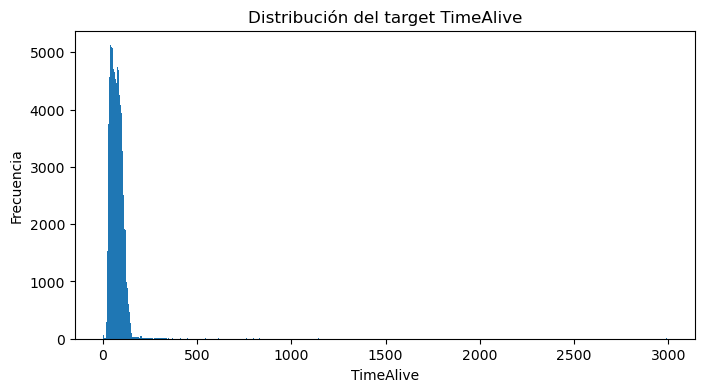

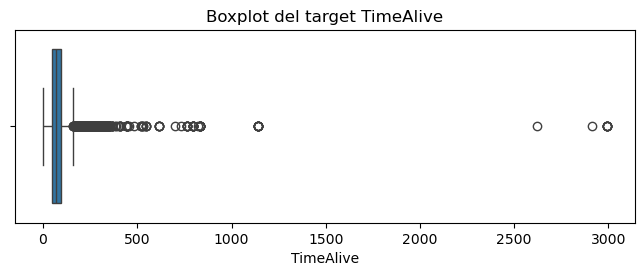

In [27]:
for target in [c for c in ["MatchWinner", "RoundWinner", "Survived"] if c in df_raw.columns]:
    print(f"\n### {target}")
    display(df_raw[target].value_counts(dropna=False))
    display((df_raw[target].value_counts(normalize=True, dropna=False) * 100).round(2))

if "TimeAlive" in df_raw.columns:
    print("\n### TimeAlive — target de regresión")
    display(df_raw["TimeAlive"].describe())

    s = df_raw["TimeAlive"].dropna()

    if len(s) > 0:
        plt.figure(figsize=(8, 4))
        plt.hist(s, bins="auto")
        plt.title("Distribución del target TimeAlive")
        plt.xlabel("TimeAlive")
        plt.ylabel("Frecuencia")
        plt.show()

        plt.figure(figsize=(8, 2.5))
        sns.boxplot(x=s)
        plt.title("Boxplot del target TimeAlive")
        plt.show()

### Interpretación de los targets preliminares

El análisis de los targets permite revisar su distribución antes de construir los datasets definitivos para clasificación y regresión.

#### `MatchWinner`

A nivel de observación jugador-ronda, `MatchWinner` presenta 42.018 registros `False` (53,08 %) y 37.139 registros `True` (46,92 %).

La diferencia entre ambas clases es relativamente pequeña, por lo que no se observa un desbalance severo en esta representación preliminar.

Sin embargo, esta distribución no debe interpretarse todavía como la proporción real de partidas ganadas y perdidas, ya que `MatchWinner` se encuentra repetido en múltiples filas correspondientes a los jugadores y rondas de una misma partida.

Para el problema de clasificación, la distribución definitiva deberá calcularse después de construir una única observación por equipo-partida y aplicar las reglas de preparación definidas para evitar duplicación e inconsistencias.

#### `RoundWinner`

`RoundWinner` presenta una distribución prácticamente equilibrada: 39.589 observaciones `False` (50,01 %) y 39.568 observaciones `True` (49,99 %).

Este equilibrio es esperable considerando que dentro de una ronda existe un equipo ganador y otro perdedor. No obstante, al igual que `MatchWinner`, los valores se encuentran repetidos para los jugadores pertenecientes al mismo equipo-ronda.

Por esta razón, estos porcentajes representan la distribución a nivel de fila y no el número de rondas independientes.

#### `Survived`

`Survived` presenta 47.214 observaciones `False` (59,65 %) y 31.943 observaciones `True` (40,35 %).

La variable muestra una mayor frecuencia de jugadores que no sobreviven a la ronda, aunque la diferencia entre ambas clases no constituye un desbalance extremo.

`Survived` no será utilizado como target principal del proyecto, pero resulta útil para comprender la estructura del dataset y la relación entre supervivencia y otras variables de desempeño.

#### `TimeAlive`

`TimeAlive`, definido como target del problema de regresión, cuenta con 79.157 observaciones y no presenta valores faltantes.

Su media es aproximadamente 72,80, mientras que la mediana es 69,24. El 50 % central de los registros se encuentra entre 47,08 y 92,65.

El histograma muestra que la mayor parte de las observaciones se concentra en valores relativamente bajos e intermedios, pero existe una cola muy prolongada hacia valores altos.

El boxplot confirma la presencia de múltiples observaciones estadísticamente extremas, incluyendo algunos valores superiores a 2.500 y un máximo de 2.990,56.

Esta forma coincide con la elevada asimetría positiva detectada en los análisis anteriores y demuestra que `TimeAlive` no presenta una distribución aproximadamente normal.

Los valores extremos no serán eliminados automáticamente. Antes de cualquier tratamiento deberá determinarse si corresponden a situaciones válidas del juego o a anomalías de los datos.

### Conclusión sobre los targets

Los dos targets definidos para el proyecto presentan características adecuadas para continuar hacia la fase de preparación de datos.

`MatchWinner` corresponde a una variable binaria apropiada para un problema de clasificación. Su distribución preliminar a nivel de fila no evidencia un desbalance severo, aunque su balance definitivo deberá evaluarse después de construir el dataset a nivel equipo-partida.

`TimeAlive` corresponde a una variable continua adecuada para un problema de regresión. Su distribución es fuertemente asimétrica y contiene valores extremos, por lo que estas características deberán considerarse posteriormente al seleccionar métricas, transformaciones y modelos.

En consecuencia, la construcción definitiva de los targets deberá respetar la granularidad de cada problema: una observación por equipo-partida para clasificación y una observación por jugador-ronda para regresión.

## 2.13 Primer análisis de la hipótesis: rondas iniciales y victoria

Este análisis se realizará a nivel **equipo-ronda**, no a nivel jugador, para evitar contar varias veces el mismo resultado de ronda.

In [28]:
# ============================================================
# 2.13 Primer análisis de la hipótesis:
# primeras dos rondas observadas por lado y victoria de partida
# ============================================================

required = {
    "MatchId",
    "RoundId",
    "InternalTeamId",
    "Team",
    "RoundWinner",
    "MatchWinner"
}

if required.issubset(df_raw.columns):

    print("Dimensiones dataset original:", df_raw.shape)

    # --------------------------------------------------------
    # 1. Detectar grupos equipo-ronda con Team inconsistente
    # --------------------------------------------------------

    team_nunique = (
        df_raw
        .groupby(
            ["MatchId", "RoundId", "InternalTeamId"]
        )["Team"]
        .nunique()
    )

    grupos_team_inconsistente = (
        team_nunique[team_nunique > 1]
        .reset_index()
    )

    matches_team_inconsistente = sorted(
        grupos_team_inconsistente["MatchId"].unique().tolist()
    )

    print(
        "Grupos equipo-ronda con Team inconsistente:",
        len(grupos_team_inconsistente)
    )

    print(
        "Partidas afectadas por Team inconsistente:",
        matches_team_inconsistente
    )

    # Para este análisis de clasificación se adopta
    # un criterio conservador:
    # excluir completamente las partidas afectadas.
    df_213 = df_raw[
        ~df_raw["MatchId"].isin(matches_team_inconsistente)
    ].copy()

    # --------------------------------------------------------
    # 2. Construir una fila lógica por equipo-ronda
    # --------------------------------------------------------

    team_round = (
        df_213
        .groupby(
            ["MatchId", "RoundId", "InternalTeamId"],
            as_index=False
        )
        .agg(
            Team=("Team", "first"),
            RoundWinner=("RoundWinner", "first"),
            MatchWinner=("MatchWinner", "first")
        )
        .sort_values(
            ["MatchId", "InternalTeamId", "RoundId"]
        )
        .reset_index(drop=True)
    )

    duplicados_logicos = (
        team_round
        .duplicated(
            subset=[
                "MatchId",
                "RoundId",
                "InternalTeamId"
            ]
        )
        .sum()
    )

    print(
        "\nFilas equipo-ronda después de excluir "
        "partidas inconsistentes:",
        len(team_round)
    )

    print(
        "Duplicados lógicos equipo-ronda:",
        duplicados_logicos
    )

    # --------------------------------------------------------
    # 3. Validar integridad de MatchWinner a nivel partida
    # --------------------------------------------------------

    equipo_partida_target = (
        team_round
        .groupby(
            ["MatchId", "InternalTeamId"],
            as_index=False
        )
        .agg(
            MatchWinner=("MatchWinner", "first")
        )
    )

    control_match = (
        equipo_partida_target
        .groupby("MatchId")
        .agg(
            n_equipos=("InternalTeamId", "nunique"),
            n_ganadores=("MatchWinner", "sum")
        )
    )

    matches_target_inconsistente = (
        control_match[
            (control_match["n_equipos"] != 2)
            | (control_match["n_ganadores"] != 1)
        ]
        .index
        .tolist()
    )

    print(
        "\nPartidas con estructura/target MatchWinner inconsistente:",
        len(matches_target_inconsistente)
    )

    print(
        "MatchId afectados:",
        matches_target_inconsistente
    )

    # Excluir también esas partidas para este análisis
    team_round_limpio = team_round[
        ~team_round["MatchId"].isin(
            matches_target_inconsistente
        )
    ].copy()

    # --------------------------------------------------------
    # 4. Obtener primeras dos rondas realmente jugadas
    #    por cada equipo en cada lado
    # --------------------------------------------------------

    primeras_dos_por_lado = (
        team_round_limpio
        .sort_values(
            [
                "MatchId",
                "InternalTeamId",
                "Team",
                "RoundId"
            ]
        )
        .groupby(
            ["MatchId", "InternalTeamId", "Team"],
            group_keys=False
        )
        .head(2)
    )

    resumen_inicio = (
        primeras_dos_por_lado
        .groupby(
            ["MatchId", "InternalTeamId", "Team"]
        )
        .agg(
            rondas_observadas=("RoundId", "nunique"),
            primeras_dos_ganadas=("RoundWinner", "sum")
        )
        .reset_index()
    )

    # --------------------------------------------------------
    # 5. Llevar Terrorist y CounterTerrorist a columnas
    # --------------------------------------------------------

    wins_pivot = (
        resumen_inicio
        .pivot_table(
            index=["MatchId", "InternalTeamId"],
            columns="Team",
            values="primeras_dos_ganadas",
            aggfunc="first"
        )
        .rename(
            columns={
                "Terrorist": "T_First2Wins",
                "CounterTerrorist": "CT_First2Wins"
            }
        )
        .reset_index()
    )

    counts_pivot = (
        resumen_inicio
        .pivot_table(
            index=["MatchId", "InternalTeamId"],
            columns="Team",
            values="rondas_observadas",
            aggfunc="first"
        )
        .rename(
            columns={
                "Terrorist": "T_RoundsObserved",
                "CounterTerrorist": "CT_RoundsObserved"
            }
        )
        .reset_index()
    )

    ganador_match = (
        team_round_limpio
        .groupby(
            ["MatchId", "InternalTeamId"],
            as_index=False
        )
        .agg(
            MatchWinner=("MatchWinner", "first")
        )
    )

    equipo_match = (
        ganador_match
        .merge(
            wins_pivot,
            on=["MatchId", "InternalTeamId"],
            how="left"
        )
        .merge(
            counts_pivot,
            on=["MatchId", "InternalTeamId"],
            how="left"
        )
    )

    # --------------------------------------------------------
    # 6. Conservar solamente equipos con exactamente
    #    dos rondas observadas en ambos lados
    # --------------------------------------------------------

    columnas_necesarias = {
        "T_First2Wins",
        "CT_First2Wins",
        "T_RoundsObserved",
        "CT_RoundsObserved"
    }

    if columnas_necesarias.issubset(equipo_match.columns):

        elegible = (
            (equipo_match["T_RoundsObserved"] == 2)
            & (equipo_match["CT_RoundsObserved"] == 2)
        )

        print(
            "\nEquipos-partida candidatos:",
            len(equipo_match)
        )

        print(
            "Equipos con 2 rondas observadas en ambos lados:",
            int(elegible.sum())
        )

        print(
            "Equipos excluidos por observación incompleta:",
            int((~elegible).sum())
        )

        equipo_match_final = (
            equipo_match[elegible]
            .copy()
        )

        # ----------------------------------------------------
        # 7. Crear indicadores preliminares
        # ----------------------------------------------------

        equipo_match_final["OpeningRoundsWon"] = (
            equipo_match_final["T_First2Wins"]
            + equipo_match_final["CT_First2Wins"]
        )

        equipo_match_final["WonFirst2BothSides"] = (
            (equipo_match_final["T_First2Wins"] == 2)
            & (equipo_match_final["CT_First2Wins"] == 2)
        )

        print("\nDataset preliminar equipo-partida:")
        display(equipo_match_final.head(20))

        print(
            "\nProbabilidad observada de ganar según "
            "cantidad de rondas iniciales ganadas:"
        )

        display(
            equipo_match_final
            .groupby("OpeningRoundsWon")["MatchWinner"]
            .agg(["count", "mean"])
            .rename(
                columns={
                    "mean": "probabilidad_ganar"
                }
            )
        )

        print(
            "\nGanó las primeras 2 rondas observadas "
            "en ambos lados:"
        )

        display(
            equipo_match_final
            .groupby("WonFirst2BothSides")["MatchWinner"]
            .agg(["count", "mean"])
            .rename(
                columns={
                    "mean": "probabilidad_ganar"
                }
            )
        )

    else:
        print(
            "No se encontraron ambas categorías "
            "Terrorist y CounterTerrorist."
        )

else:
    print(
        "Faltan columnas necesarias:",
        required - set(df_raw.columns)
    )

Dimensiones dataset original: (79157, 37)
Grupos equipo-ronda con Team inconsistente: 18
Partidas afectadas por Team inconsistente: [6, 29, 395]

Filas equipo-ronda después de excluir partidas inconsistentes: 15672
Duplicados lógicos equipo-ronda: 0

Partidas con estructura/target MatchWinner inconsistente: 17
MatchId afectados: [115, 139, 180, 207, 212, 213, 229, 237, 278, 297, 314, 319, 338, 342, 482, 507, 510]

Equipos-partida candidatos: 626
Equipos con 2 rondas observadas en ambos lados: 616
Equipos excluidos por observación incompleta: 10

Dataset preliminar equipo-partida:


,MatchId,InternalTeamId,MatchWinner,CT_First2Wins,T_First2Wins,CT_RoundsObserved,T_RoundsObserved,OpeningRoundsWon,WonFirst2BothSides
0,4,1,True,1.0000,1.0000,2.0000,2.0000,2.0000,False
1,4,2,False,1.0000,1.0000,2.0000,2.0000,2.0000,False
2,9,1,False,0.0000,1.0000,2.0000,2.0000,1.0000,False
3,9,2,True,1.0000,2.0000,2.0000,2.0000,3.0000,False
4,10,1,False,1.0000,1.0000,2.0000,2.0000,2.0000,False
5,10,2,True,1.0000,1.0000,2.0000,2.0000,2.0000,False
8,12,1,False,1.0000,0.0000,2.0000,2.0000,1.0000,False
9,12,2,True,2.0000,1.0000,2.0000,2.0000,3.0000,False
10,13,1,False,1.0000,1.0000,2.0000,2.0000,2.0000,False
11,13,2,True,1.0000,1.0000,2.0000,2.0000,2.0000,False



Probabilidad observada de ganar según cantidad de rondas iniciales ganadas:


,count,probabilidad_ganar
OpeningRoundsWon,,
0.0000,6,0.1667
1.0000,97,0.5361
2.0000,410,0.5000
3.0000,97,0.4639
4.0000,6,0.8333



Ganó las primeras 2 rondas observadas en ambos lados:


,count,probabilidad_ganar
WonFirst2BothSides,,
False,610,0.4967
True,6,0.8333


### Interpretación del análisis preliminar de rondas observadas y victoria

El análisis fue construido a nivel equipo-partida después de aplicar controles de calidad sobre la estructura de los datos.

En primer lugar, se identificaron 18 grupos equipo-ronda con inconsistencias en `Team`, concentrados en las partidas 6, 29 y 395. Debido a que no existe evidencia suficiente para corregir estas etiquetas de forma automática, las tres partidas fueron excluidas de este análisis.

Posteriormente se verificó la integridad de `MatchWinner`. Se identificaron 17 partidas adicionales cuya estructura no contenía exactamente dos equipos y un único ganador, por lo que también fueron excluidas de forma conservadora.

Después de estos controles quedaron 626 observaciones equipo-partida candidatas. De ellas, 616 disponían de exactamente dos rondas observadas como `Terrorist` y dos como `CounterTerrorist`; las 10 restantes fueron excluidas por información insuficiente para construir el indicador de manera comparable.

La cantidad total de victorias obtenidas en estas cuatro rondas observadas (`OpeningRoundsWon`) toma valores entre 0 y 4.

La probabilidad observada de ganar la partida fue:

- 0 rondas ganadas: 16,67 % (6 observaciones).
- 1 ronda ganada: 53,61 % (97 observaciones).
- 2 rondas ganadas: 50,00 % (410 observaciones).
- 3 rondas ganadas: 46,39 % (97 observaciones).
- 4 rondas ganadas: 83,33 % (6 observaciones).

Los resultados no muestran una relación monotónica entre la cantidad de estas rondas ganadas y la probabilidad posterior de victoria. Los grupos centrales, que concentran la mayor cantidad de observaciones, presentan probabilidades cercanas al 50 %.

Los grupos extremos muestran diferencias mayores: los equipos que ganaron las cuatro rondas presentan una probabilidad observada de victoria de 83,33 %, mientras que quienes no ganaron ninguna presentan 16,67 %. Sin embargo, ambos resultados corresponden únicamente a seis observaciones, por lo que no constituyen evidencia suficiente para establecer una relación generalizable.

En consecuencia, este análisis debe interpretarse como una exploración inicial de la hipótesis y no como evidencia causal ni como demostración definitiva de capacidad predictiva. Las variables derivadas de estas rondas podrán evaluarse posteriormente dentro de un modelo de clasificación junto con otras características disponibles, como el mapa y la economía inicial.

### Conclusión Fase 2 — Comprensión de los datos

La fase de comprensión de los datos permitió caracterizar el dataset completo, compuesto por **79.157 observaciones y 37 variables**, y establecer las principales condiciones que deberán considerarse durante la preparación de los datos.

El análisis de granularidad confirmó que cada fila representa principalmente a un **jugador dentro de una ronda, equipo y partida determinados**. La combinación `MatchId + RoundId + InternalTeamId` identifica un equipo dentro de una ronda. De los 15.832 grupos equipo-ronda detectados, 15.829 contienen cinco jugadores y sólo tres contienen cuatro, sin observarse filas completamente duplicadas.

Desde el punto de vista de calidad, el dataset no presenta valores faltantes en ninguna de sus variables, por lo que no será necesario aplicar técnicas de imputación ni eliminar observaciones por `missing values`. Se identificó además `Unnamed: 0` como un índice exportado sin utilidad predictiva y `AbnormalMatch` como una variable constante (`False` en las 79.157 observaciones), por lo que ambas deberán excluirse durante la preparación.

La validación de consistencia reveló **18 grupos equipo-ronda con valores contradictorios de `Team`**, correspondientes a 90 registros y concentrados en las partidas 6, 29 y 395. Aunque estos grupos presentan distribuciones 4–1 entre `Terrorist` y `CounterTerrorist`, se comprobó que una corrección automática mediante mayoría podría producir situaciones estructuralmente imposibles, como asignar el mismo lado a ambos equipos dentro de una ronda. En consecuencia, estas inconsistencias no serán corregidas artificialmente y se utilizará un criterio conservador de exclusión según la granularidad de cada problema.

También se detectaron **17 partidas adicionales con una estructura inconsistente de `MatchWinner`**, al no presentar exactamente dos equipos y un único ganador. Estas partidas deberán excluirse del conjunto destinado al problema de clasificación para evitar propagar inconsistencias hacia el target.

Respecto del problema de regresión, `TimeAlive` fue definido como variable objetivo continua. Su distribución presenta una fuerte asimetría positiva, con media de 72,80, mediana de 69,24 y valores extremos que alcanzan 2.990,56. Mediante IQR se identificaron 594 observaciones estadísticamente extremas, equivalentes al 0,75 % del dataset. Sin embargo, estos registros no serán eliminados automáticamente, ya que un outlier estadístico no implica necesariamente un error de datos.

El análisis de `ScaledTimeAlive` mostró que el **99,43 % de sus valores (78.707 de 79.157 registros)** son compatibles con una transformación directamente relacionada con `TimeAlive`. Debido a esta dependencia, la variable será excluida de los predictores del problema de regresión para prevenir *data leakage*.

El análisis descriptivo y gráfico mostró además que las variables numéricas presentan comportamientos heterogéneos. Variables como `TravelledDistance`, `AvgRoundVelocity`, `AvgCentroidDistance`, `AvgKillDistance` y `AvgMatchKillDist` poseen diferentes grados de asimetría y valores extremos. Las variables de conteo presentan concentraciones importantes en cero y no deben tratarse mediante criterios automáticos de outliers. Las variables económicas `RoundStartingEquipmentValue` y `TeamStartingEquipmentValue` presentan distribuciones multimodales, pero no registran outliers mediante IQR.

La comparación entre IQR y Z-score confirmó que no existe un método único apropiado para todas las variables. Las distribuciones evaluadas mediante Q-Q plots se alejan de la normalidad, por lo que Z-score no será utilizado como criterio principal para eliminar observaciones. El tratamiento de valores extremos deberá combinar criterios estadísticos, interpretación semántica y conocimiento del dominio.

La matriz de correlación de Pearson mostró que no existen relaciones lineales fuertes con `TimeAlive`. La mayor correlación corresponde a `ScaledTimeAlive` (`r = 0,3503`), variable excluida por *data leakage*. Entre las variables disponibles durante la ronda aparecen asociaciones algo mayores, como `FirstKillTime` (`r = 0,2568`), pero estas características tampoco son adecuadas como predictores si el objetivo es estimar `TimeAlive` utilizando exclusivamente información disponible antes o al inicio de la ronda.

Entre las características potencialmente disponibles al comienzo de la ronda, `RoundStartingEquipmentValue` (`r = 0,1043`) y `TeamStartingEquipmentValue` (`r = 0,1077`) presentan relaciones lineales débiles con `TimeAlive`. Esto no implica ausencia de capacidad predictiva, ya que Pearson sólo mide asociaciones lineales individuales y no captura relaciones no lineales ni interacciones entre variables.

Para el problema de clasificación se realizó además un análisis preliminar de las primeras dos rondas observadas por cada equipo en cada lado. Después de excluir partidas con inconsistencias de `Team`, partidas con estructura inválida de `MatchWinner` y equipos sin dos rondas observadas en ambos lados, quedaron **616 observaciones equipo-partida comparables**.

La probabilidad observada de ganar no mostró una relación monotónica con `OpeningRoundsWon`. Los grupos con 1, 2 y 3 rondas ganadas presentan probabilidades cercanas al 50 %, mientras que los extremos muestran diferencias mayores: 16,67 % de victoria para quienes no ganaron ninguna de las cuatro rondas y 83,33 % para quienes ganaron las cuatro. Sin embargo, ambos grupos extremos contienen sólo seis observaciones, por lo que estos resultados deben interpretarse como una señal exploratoria y no como evidencia suficiente para establecer una relación generalizable.

En conjunto, la fase de comprensión de los datos permite avanzar hacia **CRISP-DM Fase 3 — Preparación de los datos** con decisiones fundamentadas. La siguiente etapa deberá concentrarse en:

- eliminar variables sin utilidad predictiva, como `Unnamed: 0` y `AbnormalMatch`;
- tratar de forma conservadora las inconsistencias detectadas en `Team` y `MatchWinner`;
- construir datasets con la granularidad adecuada para regresión y clasificación;
- excluir variables que produzcan *data leakage*;
- conservar únicamente características disponibles en el instante definido para cada predicción;
- aplicar codificación y escalamiento según la naturaleza de las variables y el algoritmo que posteriormente se utilice;
- y evitar la eliminación automática de outliers sin evidencia suficiente de que correspondan a errores.

De esta manera, la Fase 2 deja establecido un conjunto de criterios técnicos y semánticos para construir datasets de modelado consistentes, comparables y libres de información futura.

# FASE 3 - PREPARACIÓN DE LOS DATOS

## Hallazgos de Fase 2 que guían esta preparación

La preparación se construye a partir de lo ya observado y de las verificaciones ejecutadas sobre el dataset actualizado:

- `Unnamed: 0` corresponde a un índice exportado.
- `AbnormalMatch` no presentó variación.
- La granularidad original es **jugador-ronda-equipo-partida**.
- No se detectaron filas completamente duplicadas.
- Se detectaron inconsistencias en `Team` dentro de algunos grupos equipo-ronda.
- En la ejecución actual no se detectaron valores faltantes.
- `ScaledTimeAlive` depende directamente de `TimeAlive`, por lo que no puede utilizarse para predecir `TimeAlive`.
- Los outliers estadísticos no se eliminarán automáticamente.
- Clasificación y regresión requieren datasets diferentes.

## 3.1 Selección, limpieza e integridad

El nuevo dataset ya contiene correctamente tipadas las principales variables continuas. Por lo tanto, la preparación se enfocará en:

- eliminar artefactos de exportación;
- preservar identificadores sólo para agrupación y separación de datos;
- tratar missing values según su naturaleza;
- decidir el tratamiento de outliers;
- codificar variables categóricas;
- escalar variables cuando el algoritmo lo requiera;
- construir dos datasets analíticos separados para clasificación y regresión;
- excluir variables que generen *data leakage*.

## 3.1.1 Crear copia de trabajo y eliminar índice exportado

Durante la Fase 2 se identificó `Unnamed: 0` como una columna generada durante la exportación del dataset. Esta variable presenta un valor distinto para cada registro y no representa información del dominio, por lo que se comprobará su presencia y se eliminará antes de continuar con la preparación.

In [29]:
# Se crea UNA sola copia de trabajo para toda la Fase 3.
df = df_raw.copy()

cols_indice = [
    c for c in df.columns
    if c.lower().startswith("unnamed")
]

print("Columnas de índice detectadas:", cols_indice)

if cols_indice:
    df = df.drop(columns=cols_indice)

print("Dimensiones después de eliminar índice exportado:", df.shape)
print("¿Queda alguna columna Unnamed?:",
      any(c.lower().startswith("unnamed") for c in df.columns))

Columnas de índice detectadas: ['Unnamed: 0']
Dimensiones después de eliminar índice exportado: (79157, 36)
¿Queda alguna columna Unnamed?: False


**Conclusión:** se confirmó que `Unnamed: 0` correspondía a un índice exportado sin valor predictivo ni significado dentro del dominio del problema. La columna fue eliminada correctamente, reduciendo el dataset de 37 a 36 variables, sin modificar la cantidad de registros, que se mantiene en 79.157 observaciones. La validación final confirma que no permanecen columnas de tipo `Unnamed` en el conjunto de trabajo.

## 3.1.2 Identificación de variables constantes

Durante la Fase 2 se observó que algunas variables podían no presentar variación entre los registros. Una variable constante no permite diferenciar observaciones ni aporta información útil para un modelo predictivo.

En esta etapa se comprobará nuevamente el número de valores únicos de cada variable sobre el dataset de trabajo. Sólo se eliminarán aquellas columnas que presenten un único valor en todas las observaciones. Los identificadores estructurales como `MatchId`, `RoundId`, `InternalTeamId` y `SteamId` se conservarán, ya que todavía son necesarios para agrupación, validación y trazabilidad.

In [30]:
perfil_constantes = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(dropna=False)
})

constantes = perfil_constantes[
    perfil_constantes["n_unique"] <= 1
].index.tolist()

print("Variables constantes detectadas:", constantes)

# En Fase 2 AbnormalMatch fue constante.
# La eliminación se hace sólo si vuelve a confirmarse en esta ejecución.
if constantes:
    df = df.drop(columns=constantes)

print("Dimensiones después de eliminar constantes:", df.shape)

Variables constantes detectadas: ['AbnormalMatch']
Dimensiones después de eliminar constantes: (79157, 35)


**Conclusión:** se identificó `AbnormalMatch` como la única variable constante del dataset, ya que presenta el mismo valor en todas las observaciones. Al no aportar variabilidad ni capacidad para diferenciar registros, se elimina del conjunto de trabajo. Después de esta operación, el dataset queda compuesto por 79.157 registros y 35 variables.

### 3.1.3 Validación de integridad de la variable `Team`

Durante la Fase 2 se detectaron algunos grupos definidos por `MatchId`, `RoundId` e `InternalTeamId` donde aparecía más de un valor de `Team` dentro de una misma combinación equipo-ronda. Dado que `Team` representa el lado jugado en una ronda (`Terrorist` o `CounterTerrorist`), cada equipo debería presentar una única categoría dentro de esa ronda.

En esta etapa se identificarán nuevamente estos grupos inconsistentes y se cuantificarán las filas y partidas afectadas. La variable no será corregida automáticamente hasta revisar la naturaleza de las inconsistencias.

In [31]:
team_por_grupo = (
    df.groupby(
        ["MatchId", "RoundId", "InternalTeamId"]
    )["Team"]
    .nunique(dropna=True)
)

grupos_team_inconsistentes = (
    team_por_grupo[team_por_grupo > 1]
    .reset_index(name="n_team")
)

print("Grupos equipo-ronda inconsistentes:",
      len(grupos_team_inconsistentes))

if len(grupos_team_inconsistentes) > 0:
    detalle_team = df.merge(
        grupos_team_inconsistentes[
            ["MatchId", "RoundId", "InternalTeamId"]
        ],
        on=["MatchId", "RoundId", "InternalTeamId"],
        how="inner"
    )

    patrones_team = (
        detalle_team
        .groupby(
            ["MatchId", "RoundId", "InternalTeamId", "Team"]
        )
        .size()
        .reset_index(name="n_jugadores")
    )

    print("Filas involucradas:", len(detalle_team))
    print("Partidas afectadas:",
          sorted(detalle_team["MatchId"].unique().tolist()))

    display(patrones_team)
else:
    detalle_team = df.iloc[0:0].copy()
    patrones_team = pd.DataFrame()

bad_team_matches = sorted(
    grupos_team_inconsistentes["MatchId"].unique().tolist()
) if len(grupos_team_inconsistentes) else []

print("Cantidad de partidas con inconsistencia Team:",
      len(bad_team_matches))

Grupos equipo-ronda inconsistentes: 18
Filas involucradas: 90
Partidas afectadas: [6, 29, 395]


,MatchId,RoundId,InternalTeamId,Team,n_jugadores
0,6,8,1,CounterTerrorist,1
1,6,8,1,Terrorist,4
2,6,9,1,CounterTerrorist,1
3,6,9,1,Terrorist,4
4,6,10,1,CounterTerrorist,1
5,6,10,1,Terrorist,4
6,6,11,1,CounterTerrorist,1
7,6,11,1,Terrorist,4
8,6,12,1,CounterTerrorist,1
9,6,12,1,Terrorist,4


Cantidad de partidas con inconsistencia Team: 3


**Conclusión:** se identificaron 18 grupos equipo-ronda con inconsistencias en la variable `Team`, correspondientes a 90 registros y concentrados en las partidas `MatchId = 6`, `MatchId = 29` y `MatchId = 395`. En estos casos, dentro de una misma combinación de `MatchId`, `RoundId` e `InternalTeamId` aparecen jugadores etiquetados en ambos lados (`Terrorist` y `CounterTerrorist`), principalmente con una distribución 4-1.

Debido a que `Team` representa el lado jugado durante una ronda, cada equipo debería presentar una única categoría dentro de esa combinación. No se realizará una corrección automática utilizando la categoría mayoritaria, ya que esto podría generar asignaciones estructuralmente incorrectas. Estas observaciones se tratarán de forma conservadora en la construcción posterior de los datasets analíticos.

### 3.1.4 Auditoría de valores faltantes

Durante la Fase 2 no se detectaron valores faltantes en el dataset actual. En esta sección se repite la auditoría para confirmar esa condición antes de continuar con la preparación. Los resultados muestran cero valores faltantes, por lo que no corresponde aplicar eliminación ni imputación por este motivo.


In [32]:
missing_resumen = pd.DataFrame({
    "cantidad": df.isna().sum(),
    "porcentaje": df.isna().mean() * 100
})

missing_resumen = (
    missing_resumen[missing_resumen["cantidad"] > 0]
    .sort_values("porcentaje", ascending=False)
)

filas_missing = df[df.isna().any(axis=1)]

print("Columnas con missing:", len(missing_resumen))
print("Total de valores missing:", int(df.isna().sum().sum()))
print("Filas con al menos un missing:", len(filas_missing))

display(missing_resumen)

if len(filas_missing):
    display(filas_missing)

Columnas con missing: 0


Total de valores missing: 0
Filas con al menos un missing: 0


,cantidad,porcentaje


### 3.1.5 Tratamiento de valores faltantes

La auditoría anterior confirmó que, en la ejecución actual del dataset actualizado, no existen valores faltantes. Por lo tanto, no corresponde eliminar observaciones ni aplicar técnicas de imputación.

El código conserva una lógica defensiva: si en una futura ejecución apareciera una única fila con valores faltantes y su proporción fuera inferior al 0,1 % del total, podría eliminarse; si el patrón fuera diferente, la preparación se detendría para evitar una imputación o eliminación automática sin justificación.

In [33]:
n_filas_missing = len(filas_missing)
pct_filas_missing = (
    n_filas_missing / len(df) * 100
    if len(df) else 0
)

print("Filas afectadas:", n_filas_missing)
print("Porcentaje de filas afectadas:",
      round(pct_filas_missing, 6), "%")

if n_filas_missing == 0:
    print("No hay filas con missing. No se realiza eliminación.")

elif n_filas_missing == 1 and pct_filas_missing < 0.1:
    indices_eliminados_missing = filas_missing.index.tolist()
    df = df.drop(index=indices_eliminados_missing).copy()

    print("Se eliminó la única fila con missing.")
    print("Índice eliminado:", indices_eliminados_missing)
    print("Dimensiones actuales:", df.shape)
    print("Missing restantes:", int(df.isna().sum().sum()))

else:
    raise ValueError(
        "El patrón de missing values no coincide con lo observado en Fase 2. "
        "Detener la preparación y revisar antes de imputar o eliminar."
    )

Filas afectadas: 0
Porcentaje de filas afectadas: 0.0 %
No hay filas con missing. No se realiza eliminación.


**Conclusión:** en la ejecución actual no se detectaron valores faltantes: no hay columnas con `missing`, el total de valores faltantes es 0 y no existe ninguna fila afectada.

Por esta razón, no se realizó eliminación de registros ni imputación. El conjunto de trabajo se mantiene con 79.157 registros y 35 variables, permitiendo continuar con un dataset completo sin introducir valores estimados artificialmente.

## 3.2 Construcción de bases analíticas según el problema

La preparación de los datos debe considerar que los dos problemas supervisados definidos presentan distinta granularidad y distintos requisitos de integridad.

Para la regresión, cuyo objetivo es predecir `TimeAlive`, se conservará la granularidad jugador-ronda. En cambio, para la clasificación de `MatchWinner`, los datos deberán reorganizarse posteriormente a nivel equipo-partida.

Además, las inconsistencias detectadas en `Team` no pueden tratarse de la misma forma en ambos problemas. En regresión se excluirán únicamente los grupos equipo-ronda afectados por una etiqueta ambigua, mientras que en clasificación se excluirán las partidas completas que presenten este problema, ya que `Team` será necesario para reconstruir correctamente el desempeño por lado.

### 3.2.1 Creación de bases conservadoras para regresión y clasificación

In [34]:
# Recalcular grupos Team inconsistentes después del tratamiento de missing.
team_por_grupo_post = (
    df.groupby(
        ["MatchId", "RoundId", "InternalTeamId"]
    )["Team"]
    .nunique(dropna=True)
)

bad_groups_post = (
    team_por_grupo_post[team_por_grupo_post > 1]
    .reset_index()[["MatchId", "RoundId", "InternalTeamId"]]
)

bad_team_matches_post = sorted(
    bad_groups_post["MatchId"].unique().tolist()
) if len(bad_groups_post) else []

# ---- REGRESIÓN ----
# Se eliminan sólo los grupos jugador-ronda donde Team es ambiguo.
if len(bad_groups_post):
    df_reg_base = (
        df.merge(
            bad_groups_post.assign(_team_ambiguo=1),
            on=["MatchId", "RoundId", "InternalTeamId"],
            how="left"
        )
    )
    filas_reg_ambiguas = int(
        df_reg_base["_team_ambiguo"].fillna(0).sum()
    )
    df_reg_base = (
        df_reg_base[df_reg_base["_team_ambiguo"].isna()]
        .drop(columns="_team_ambiguo")
        .copy()
    )
else:
    filas_reg_ambiguas = 0
    df_reg_base = df.copy()

# ---- CLASIFICACIÓN ----
# Se excluye la partida completa si Team es ambiguo en alguna ronda.
df_cls_base = df[
    ~df["MatchId"].isin(bad_team_matches_post)
].copy()

print("REGRESIÓN")
print("Filas excluidas por Team ambiguo:", filas_reg_ambiguas)
print("Dimensiones base:", df_reg_base.shape)

print("\nCLASIFICACIÓN")
print("Partidas excluidas por Team ambiguo:",
      bad_team_matches_post)
print("Cantidad de partidas excluidas:",
      len(bad_team_matches_post))
print("Dimensiones base:", df_cls_base.shape)

REGRESIÓN
Filas excluidas por Team ambiguo: 90
Dimensiones base: (79067, 35)

CLASIFICACIÓN
Partidas excluidas por Team ambiguo: [6, 29, 395]
Cantidad de partidas excluidas: 3
Dimensiones base: (78359, 35)


**Conclusión:** a partir de las inconsistencias identificadas en `Team`, se generaron bases de trabajo independientes para regresión y clasificación, aplicando un tratamiento acorde con la granularidad de cada problema.

Para regresión se excluyeron únicamente las 90 observaciones pertenecientes a los 18 grupos equipo-ronda donde `Team` era ambiguo, conservando 79.067 registros. Esta estrategia permite mantener la mayor cantidad posible de información a nivel jugador-ronda sin intentar corregir etiquetas cuya categoría verdadera no puede determinarse con certeza.

Para clasificación se adoptó un criterio más conservador y se excluyeron completamente las partidas `MatchId = 6`, `MatchId = 29` y `MatchId = 395`, que fueron las partidas donde se detectaron inconsistencias de `Team`. La base resultante contiene 78.359 registros antes de realizar la posterior agregación a nivel equipo-partida.

De esta forma, no se imputaron ni corrigieron arbitrariamente las etiquetas inconsistentes, evitando incorporar información potencialmente incorrecta a los datasets analíticos.

### 3.2.2 Validación de integridad de las bases resultantes

Después de separar las bases para regresión y clasificación, se verificará que los grupos conservados ya no presenten más de una categoría `Team` dentro de una misma combinación de `MatchId`, `RoundId` e `InternalTeamId`.

También se comprobará que no existan valores faltantes en ninguna de las dos bases. Esta validación permite confirmar que las decisiones de limpieza anteriores fueron aplicadas correctamente antes de continuar con la selección y transformación de variables.

In [35]:
# Regresión: ningún grupo conservado debe tener más de un Team.
check_reg_team = (
    df_reg_base.groupby(
        ["MatchId", "RoundId", "InternalTeamId"]
    )["Team"]
    .nunique()
)

# Clasificación: tampoco deben existir grupos ambiguos.
check_cls_team = (
    df_cls_base.groupby(
        ["MatchId", "RoundId", "InternalTeamId"]
    )["Team"]
    .nunique()
)

print("Grupos Team inconsistentes en base regresión:",
      int((check_reg_team > 1).sum()))
print("Grupos Team inconsistentes en base clasificación:",
      int((check_cls_team > 1).sum()))

print("Missing base regresión:",
      int(df_reg_base.isna().sum().sum()))
print("Missing base clasificación:",
      int(df_cls_base.isna().sum().sum()))

Grupos Team inconsistentes en base regresión: 0
Grupos Team inconsistentes en base clasificación: 0
Missing base regresión: 0
Missing base clasificación: 0


**Conclusión:** las bases resultantes de regresión y clasificación quedaron correctamente depuradas. No se detectan grupos equipo-ronda con inconsistencias en `Team` y tampoco existen valores faltantes en ninguno de los dos conjuntos.

Esto confirma que la exclusión conservadora aplicada en el paso anterior resolvió las inconsistencias estructurales sin necesidad de corregir etiquetas de forma artificial. A partir de este punto, ambas bases pueden continuar hacia la selección y transformación de variables específicas de cada problema.

## 3.3 Tratamiento de outliers

Durante la Fase 2 se identificaron valores extremos mediante IQR y Z-score. Sin embargo, no todos los valores marcados estadísticamente como outliers representan errores del dataset.

En variables de conteo, como kills, assists o granadas, los valores poco frecuentes pueden corresponder a eventos válidos dentro del juego. Del mismo modo, algunas variables continuas presentan colas largas o valores extremos que requieren interpretación antes de decidir su eliminación.

Por este motivo, no se aplicará una eliminación global de outliers. La revisión se concentrará únicamente en las variables que llegarán a los modelos base y en el target de regresión.

### 3.3.1 Revisión de outliers en variables relevantes para el modelado

In [36]:
def resumen_iqr(serie):
    s = pd.to_numeric(serie, errors="coerce").dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    li = q1 - 1.5 * iqr
    ls = q3 + 1.5 * iqr

    return pd.Series({
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "limite_inf": li,
        "limite_sup": ls,
        "n_outliers": int(((s < li) | (s > ls)).sum()),
        "pct_outliers": ((s < li) | (s > ls)).mean() * 100
    })

vars_outlier_relevantes = [
    c for c in [
        "RoundStartingEquipmentValue",
        "TeamStartingEquipmentValue",
        "TimeAlive"
    ]
    if c in df_reg_base.columns
]

outliers_modelo = pd.DataFrame({
    c: resumen_iqr(df_reg_base[c])
    for c in vars_outlier_relevantes
}).T

display(outliers_modelo)

,q1,q3,iqr,limite_inf,limite_sup,n_outliers,pct_outliers
RoundStartingEquipmentValue,"1,600.0000","5,200.0000","3,600.0000","-3,800.0000","10,600.0000",0.0000,0.0000
TeamStartingEquipmentValue,"11,100.0000","26,050.0000","14,950.0000","-11,325.0000","48,475.0000",0.0000,0.0000
TimeAlive,47.1654,92.6714,45.5059,-21.0935,160.9303,590.0000,0.7462


**Conclusión:** las variables `RoundStartingEquipmentValue` y `TeamStartingEquipmentValue`, consideradas como predictores del modelo base de regresión, no presentan observaciones fuera de los límites definidos por el criterio IQR. Por lo tanto, no se requiere aplicar eliminación, recorte o transformación específica por outliers sobre estas variables.

En cambio, el target `TimeAlive` presenta 590 observaciones fuera del límite superior de 160,9303, equivalentes aproximadamente al 0,7462 % de la base de regresión. Estos registros se consideran valores extremos desde el punto de vista estadístico, pero no se eliminarán automáticamente, ya que el criterio IQR por sí solo no permite determinar que correspondan a errores.

Por este motivo, `TimeAlive` se conservará inicialmente en su escala original y sus valores extremos serán revisados mediante información adicional antes de decidir cualquier tratamiento.

### 3.3.2 Revisión adicional de `TimeAlive` y `ScaledTimeAlive`

Durante la Fase 2 se observó que `ScaledTimeAlive` mantiene una relación directa con `TimeAlive`, aunque la correlación lineal global entre ambas variables no sea elevada. Esto indica que `ScaledTimeAlive` puede contener información derivada del propio target y, por tanto, representar una posible fuga de información en el problema de regresión.

Además, los valores extremos detectados en `TimeAlive` requieren una revisión adicional antes de considerar cualquier eliminación. En esta etapa se analizará nuevamente la relación entre ambas variables y se identificarán los registros donde `ScaledTimeAlive` presenta valores superiores a 1.

Esta comprobación tendrá carácter diagnóstico: no se eliminarán observaciones automáticamente a partir de sus resultados.

In [37]:
if {"TimeAlive", "ScaledTimeAlive", "MatchId", "RoundId"}.issubset(df_reg_base.columns):
    max_time_round = (
        df_reg_base.groupby(
            ["MatchId", "RoundId"]
        )["TimeAlive"]
        .transform("max")
    )

    scaled_estimado = (
        df_reg_base["TimeAlive"] / max_time_round
    )

    validos = (
        df_reg_base["ScaledTimeAlive"].notna()
        & scaled_estimado.notna()
    )

    coincide_scaled = np.isclose(
        df_reg_base.loc[validos, "ScaledTimeAlive"],
        scaled_estimado.loc[validos],
        rtol=1e-5,
        atol=1e-8
    )

    print("Compatibilidad con TimeAlive / max(TimeAlive ronda):",
          round(coincide_scaled.mean() * 100, 4), "%")

    mayores_uno = df_reg_base[
        df_reg_base["ScaledTimeAlive"] > 1
    ]

    print("Registros con ScaledTimeAlive > 1:",
          len(mayores_uno))

    if len(mayores_uno):
        print("MatchId involucrados:")
        display(
            mayores_uno["MatchId"]
            .value_counts()
            .to_frame("n_registros")
        )

        display(
            mayores_uno[
                [
                    "MatchId", "RoundId",
                    "InternalTeamId", "SteamId",
                    "TimeAlive", "ScaledTimeAlive"
                ]
            ].head(30)
        )
else:
    print("No están disponibles todas las columnas requeridas.")

Compatibilidad con TimeAlive / max(TimeAlive ronda): 99.4435 %
Registros con ScaledTimeAlive > 1: 42
MatchId involucrados:


,n_registros
MatchId,
412,23
175,19


,MatchId,RoundId,InternalTeamId,SteamId,TimeAlive,ScaledTimeAlive
29919,175,1,1,76561198031554200,127.0806,1.6099
29929,175,2,1,76561198031554200,150.3347,1.8232
29939,175,3,1,76561198031554200,120.9214,1.0100
29959,175,5,1,76561198031554200,264.8454,2.0000
29969,175,6,1,76561198031554200,177.3597,1.5091
29979,175,7,1,76561198031554200,199.9853,2.0000
29989,175,8,1,76561198031554200,168.0581,2.0000
29999,175,9,1,76561198031554200,141.2844,2.0000
30009,175,10,1,76561198031554200,102.9466,1.9976
30029,175,12,1,76561198031554200,216.9546,2.0000


**Conclusión:** la comparación muestra que `ScaledTimeAlive` coincide en aproximadamente un 99,4435 % de los registros con una transformación basada en `TimeAlive` y el máximo observado dentro de la ronda. Esto confirma que ambas variables están directamente relacionadas y respalda la decisión de excluir `ScaledTimeAlive` como predictor del modelo de regresión, ya que contiene información derivada del propio target.

Además, se identificaron 42 registros con `ScaledTimeAlive > 1`. Estos casos se concentran en las partidas `MatchId = 412` con 23 registros y `MatchId = 175` con 19 registros, por lo que no corresponden a un patrón generalizado del dataset.

Estos registros no se eliminarán únicamente por esta condición. Aunque `ScaledTimeAlive` presenta valores atípicos, la variable no será utilizada como predictor y no existe evidencia suficiente para concluir que los valores correspondientes de `TimeAlive` sean inválidos. Por lo tanto, se mantiene la información original y se controla el posible *data leakage* mediante exclusión de variables.

## 3.4 Prevención de data leakage

La preparación de los datasets debe considerar no sólo el tipo de variable, sino también el momento en que dicha información estaría disponible al realizar una predicción.

En el problema de regresión, cuyo objetivo es estimar `TimeAlive`, se excluirán variables que se generan durante o después de la ronda, así como aquellas derivadas directamente del target. Se conservarán únicamente atributos disponibles antes o al comienzo de la ronda.

Para clasificación, la selección de variables se realizará posteriormente considerando la granularidad equipo-partida y el momento definido para predecir `MatchWinner`.

### 3.4.1 Definición de variables permitidas y excluidas para regresión

In [38]:
# ---------- REGRESIÓN ----------
reg_id_cols = [
    "MatchId", "InternalTeamId", "SteamId"
]

reg_feature_cols = [
    "Map",
    "Team",
    "RoundId",
    "RoundStartingEquipmentValue",
    "TeamStartingEquipmentValue"
]

reg_target = "TimeAlive"

reg_feature_cols = [
    c for c in reg_feature_cols
    if c in df_reg_base.columns
]

reg_id_cols = [
    c for c in reg_id_cols
    if c in df_reg_base.columns
]

# Lista documental de leakage/exclusiones.
reg_leakage_cols = [
    c for c in [
        "ScaledTimeAlive",
        "RoundWinner",
        "MatchWinner",
        "Survived",
        "TravelledDistance",
        "AvgRoundVelocity",
        "AvgKillDistance",
        "AvgCentroidDistance",
        "AvgSiteDistance",
        "RLethalGrenadesThrown",
        "RNonLethalGrenadesThrown",
        "FirstKillTime",
        "RoundKills",
        "RoundAssists",
        "RoundHeadshots",
        "RoundFlankKills",
        "MatchKills",
        "MatchFlankKills",
        "MatchAssists",
        "MatchHeadshots",
        "AvgMatchKillDist",
        "PrimaryAssaultRifle",
        "PrimarySniperRifle",
        "PrimaryHeavy",
        "PrimarySMG",
        "PrimaryPistol"
    ]
    if c in df_reg_base.columns
]

print("REGRESIÓN — IDs estructurales:")
print(reg_id_cols)

print("\nREGRESIÓN — features permitidas:")
print(reg_feature_cols)

print("\nREGRESIÓN — target:")
print(reg_target)

print("\nREGRESIÓN — variables excluidas del modelo base:")
print(reg_leakage_cols)

REGRESIÓN — IDs estructurales:
['MatchId', 'InternalTeamId', 'SteamId']

REGRESIÓN — features permitidas:
['Map', 'Team', 'RoundId', 'RoundStartingEquipmentValue', 'TeamStartingEquipmentValue']

REGRESIÓN — target:
TimeAlive

REGRESIÓN — variables excluidas del modelo base:
['ScaledTimeAlive', 'RoundWinner', 'MatchWinner', 'Survived', 'TravelledDistance', 'AvgRoundVelocity', 'AvgKillDistance', 'AvgCentroidDistance', 'AvgSiteDistance', 'RLethalGrenadesThrown', 'RNonLethalGrenadesThrown', 'FirstKillTime', 'RoundKills', 'RoundAssists', 'RoundHeadshots', 'RoundFlankKills', 'MatchKills', 'MatchFlankKills', 'MatchAssists', 'MatchHeadshots', 'AvgMatchKillDist', 'PrimaryAssaultRifle', 'PrimarySniperRifle', 'PrimaryHeavy', 'PrimarySMG', 'PrimaryPistol']


**Conclusión:** para el problema de regresión se definió `TimeAlive` como variable objetivo y se conservaron como predictores base únicamente `Map`, `Team`, `RoundId`, `RoundStartingEquipmentValue` y `TeamStartingEquipmentValue`. Estas variables corresponden a información disponible antes o al comienzo de la ronda, por lo que pueden utilizarse sin incorporar resultados futuros.

Las variables `MatchId`, `InternalTeamId` y `SteamId` se mantienen únicamente como identificadores estructurales para agrupación, trazabilidad y futura separación de los datos, pero no serán utilizadas como magnitudes predictoras.

Se excluyeron del modelo base las variables generadas durante o después de la ronda, las estadísticas acumuladas de partida y `ScaledTimeAlive`, cuya dependencia directa con `TimeAlive` fue comprobada previamente. También se excluyeron temporalmente las variables asociadas al arma primaria, ya que con la información disponible no se puede determinar con suficiente certeza en qué momento exacto son registradas respecto de la predicción.

De esta forma, el conjunto de predictores de regresión queda restringido a información disponible en un escenario de predicción realista, reduciendo el riesgo de *data leakage*.

## 3.5 Construcción del dataset de clasificación

El problema de clasificación tiene como objetivo predecir `MatchWinner`, pero el dataset original se encuentra a nivel jugador-ronda. Por esta razón, antes de construir el conjunto analítico es necesario transformar la información a una granularidad coherente con el objetivo.

La construcción se realizará en dos etapas. Primero se generará una tabla a nivel equipo-ronda, donde cada combinación de `MatchId`, `RoundId` e `InternalTeamId` represente una única observación. Posteriormente, esta información se resumirá a nivel equipo-partida utilizando únicamente las rondas definidas para el escenario de predicción.

Antes de realizar la agregación se comprobará que `Team`, `RoundWinner`, `MatchWinner`, `Map` y `TeamStartingEquipmentValue` sean consistentes dentro de cada equipo-ronda.

### 3.5.1 Construcción y validación de la tabla equipo-ronda

In [39]:
# Validaciones de consistencia de las variables que se usarán.
keys_team_round = [
    "MatchId", "RoundId", "InternalTeamId"
]

validaciones = pd.DataFrame({
    "Team": (
        df_cls_base.groupby(keys_team_round)["Team"]
        .nunique(dropna=True)
    ),
    "RoundWinner": (
        df_cls_base.groupby(keys_team_round)["RoundWinner"]
        .nunique(dropna=True)
    ),
    "MatchWinner": (
        df_cls_base.groupby(keys_team_round)["MatchWinner"]
        .nunique(dropna=True)
    ),
    "Map": (
        df_cls_base.groupby(keys_team_round)["Map"]
        .nunique(dropna=True)
    ),
    "TeamStartingEquipmentValue": (
        df_cls_base.groupby(keys_team_round)[
            "TeamStartingEquipmentValue"
        ].nunique(dropna=True)
    )
})

print("Grupos con inconsistencias en variables necesarias:")
display((validaciones > 1).sum().to_frame("n_grupos"))

# Se usa mediana para TeamStartingEquipmentValue sólo como agregador
# tolerante a un eventual valor ausente. Si los valores son consistentes,
# mediana == valor repetido del equipo.
team_round = (
    df_cls_base
    .groupby(keys_team_round, as_index=False)
    .agg(
        Map=("Map", "first"),
        Team=("Team", "first"),
        RoundWinner=("RoundWinner", "first"),
        MatchWinner=("MatchWinner", "first"),
        TeamStartingEquipmentValue=(
            "TeamStartingEquipmentValue", "median"
        ),
        n_players=("SteamId", "nunique")
    )
)

print("Filas equipo-ronda:", len(team_round))
print("Distribución de jugadores por equipo-ronda:")
display(
    team_round["n_players"]
    .value_counts()
    .sort_index()
    .to_frame("n_grupos")
)

display(team_round.head(10))

Grupos con inconsistencias en variables necesarias:


,n_grupos
Team,0
RoundWinner,0
MatchWinner,0
Map,0
TeamStartingEquipmentValue,0


Filas equipo-ronda: 15672
Distribución de jugadores por equipo-ronda:


,n_grupos
n_players,
4,1
5,15671


,MatchId,RoundId,InternalTeamId,Map,Team,RoundWinner,MatchWinner,TeamStartingEquipmentValue,n_players
0,4,1,1,de_inferno,Terrorist,False,True,"4,400.0000",5
1,4,1,2,de_inferno,CounterTerrorist,True,False,"3,750.0000",5
2,4,2,1,de_inferno,Terrorist,True,True,"1,300.0000",5
3,4,2,2,de_inferno,CounterTerrorist,False,False,"19,950.0000",5
4,4,3,1,de_inferno,Terrorist,True,True,"2,000.0000",5
5,4,3,2,de_inferno,CounterTerrorist,False,False,"22,850.0000",5
6,4,4,1,de_inferno,Terrorist,True,True,"23,350.0000",5
7,4,4,2,de_inferno,CounterTerrorist,False,False,"25,100.0000",5
8,4,5,1,de_inferno,Terrorist,True,True,"1,700.0000",5
9,4,5,2,de_inferno,CounterTerrorist,False,False,"26,600.0000",5


**Conclusión:** la construcción de la tabla a nivel equipo-ronda produjo 15.672 observaciones, sin inconsistencias en las variables necesarias para la clasificación. Dentro de cada combinación de `MatchId`, `RoundId` e `InternalTeamId`, `Team`, `RoundWinner`, `MatchWinner`, `Map` y `TeamStartingEquipmentValue` presentan un único valor, por lo que pueden agregarse de forma segura a esta granularidad.

La mayoría de los grupos equipo-ronda, 15.671 de 15.672, contienen cinco jugadores distintos. Se observa además un grupo con cuatro jugadores. Este caso se mantiene, ya que las variables utilizadas para construir el dataset de clasificación son atributos a nivel de equipo-ronda y su consistencia fue comprobada previamente. La cantidad de jugadores se conserva únicamente como indicador de control y no se utilizará como predictor.

La variable `TeamStartingEquipmentValue` también resultó consistente dentro de cada equipo-ronda, por lo que el valor agregado representa correctamente la información económica del equipo para esa ronda.

### 3.5.2 Selección de las primeras dos rondas jugadas en cada lado

Para construir un escenario de predicción comparable entre los equipos, se seleccionarán las primeras dos rondas observadas mientras cada equipo juega como `Terrorist` y las primeras dos mientras juega como `CounterTerrorist`.

La selección se realiza respetando el orden de `RoundId`. Posteriormente se verificará que cada combinación equipo-partida disponga efectivamente de dos rondas en ambos lados. Aquellos casos que no cumplan esta condición no se utilizarán para construir el dataset final de clasificación, ya que no disponen de la misma cantidad de información que el resto.

In [40]:
# Orden temporal dentro de cada lado.
team_round_sorted = team_round.sort_values(
    ["MatchId", "InternalTeamId", "Team", "RoundId"]
)

first2_side = (
    team_round_sorted
    .groupby(
        ["MatchId", "InternalTeamId", "Team"],
        group_keys=False
    )
    .head(2)
    .copy()
)

# Verificar cuántas rondas se obtuvieron por lado.
conteo_first2 = (
    first2_side
    .groupby(
        ["MatchId", "InternalTeamId", "Team"]
    )
    .size()
    .unstack(fill_value=0)
)

print("Distribución del número de rondas disponibles por lado:")
display(
    conteo_first2
    .value_counts()
    .reset_index(name="n_equipos_partida")
)

# Elegibles: exactamente dos rondas T y dos CT.
required_sides = {"Terrorist", "CounterTerrorist"}

if required_sides.issubset(conteo_first2.columns):
    mask_elegible = (
        (conteo_first2["Terrorist"] == 2)
        & (conteo_first2["CounterTerrorist"] == 2)
    )

    eligible_keys = (
        conteo_first2[mask_elegible]
        .reset_index()[
            ["MatchId", "InternalTeamId"]
        ]
    )

    print("Equipos-partida elegibles:",
          len(eligible_keys))
    print("Equipos-partida excluidos por no tener "
          "2 rondas observables en ambos lados:",
          int((~mask_elegible).sum()))
else:
    eligible_keys = pd.DataFrame(
        columns=["MatchId", "InternalTeamId"]
    )
    print("No aparecen ambos lados en la tabla.")

Distribución del número de rondas disponibles por lado:


,CounterTerrorist,Terrorist,n_equipos_partida
0,2,2,648
1,0,2,3
2,1,2,3
3,2,0,3
4,2,1,3


Equipos-partida elegibles: 648
Equipos-partida excluidos por no tener 2 rondas observables en ambos lados: 12


**Conclusión:** antes de construir el dataset final de clasificación se evaluó la disponibilidad de las primeras dos rondas jugadas por cada equipo como `Terrorist` y como `CounterTerrorist`.

De los 660 equipos-partida disponibles después de la limpieza previa, 648 presentan al menos dos rondas observables en ambos lados y cumplen el criterio definido para construir las variables de clasificación. Los 12 equipos-partida restantes no disponen de dos rondas en al menos uno de los lados, por lo que se excluyen para evitar comparar observaciones construidas con distinta cantidad de información.

De esta forma, se conserva aproximadamente el 98,18 % de los equipos-partida candidatos y se mantiene una definición homogénea de las variables utilizadas posteriormente en el modelo de clasificación.

### 3.5.3 Construcción del dataset analítico de clasificación

Una vez identificados los equipos-partida que disponen de información suficiente en ambos lados, se procederá a construir una única observación por combinación de `MatchId` e `InternalTeamId`.

Para cada equipo se resumirá el desempeño de sus primeras dos rondas como `Terrorist` y sus primeras dos rondas como `CounterTerrorist`, incorporando el número de rondas ganadas y el nivel medio de equipamiento inicial del equipo en esas observaciones.

La variable `MatchWinner` se mantendrá como target de clasificación y `Map` como característica categórica. Finalmente, se comprobará que la clave equipo-partida sea única, que no existan valores faltantes y que el target conserve una distribución adecuada.


In [41]:
# Resumir las primeras dos rondas de cada lado.
first2_summary = (
    first2_side
    .groupby(
        ["MatchId", "InternalTeamId", "Team"],
        as_index=False
    )
    .agg(
        First2Wins=("RoundWinner", "sum"),
        First2EquipMean=(
            "TeamStartingEquipmentValue", "mean"
        ),
        FirstRoundId=("RoundId", "min"),
        LastRoundId=("RoundId", "max"),
        NRounds=("RoundId", "size")
    )
)

# Mantener sólo equipos-partida elegibles.
first2_summary = first2_summary.merge(
    eligible_keys,
    on=["MatchId", "InternalTeamId"],
    how="inner"
)

# Pivotear lados a columnas.
wins_pivot = (
    first2_summary
    .pivot(
        index=["MatchId", "InternalTeamId"],
        columns="Team",
        values="First2Wins"
    )
    .rename(columns={
        "Terrorist": "T_First2Wins",
        "CounterTerrorist": "CT_First2Wins"
    })
)

equip_pivot = (
    first2_summary
    .pivot(
        index=["MatchId", "InternalTeamId"],
        columns="Team",
        values="First2EquipMean"
    )
    .rename(columns={
        "Terrorist": "T_First2EquipMean",
        "CounterTerrorist": "CT_First2EquipMean"
    })
)

base_match = (
    team_round
    .groupby(
        ["MatchId", "InternalTeamId"],
        as_index=False
    )
    .agg(
        Map=("Map", "first"),
        MatchWinner=("MatchWinner", "first")
    )
    .merge(
        eligible_keys,
        on=["MatchId", "InternalTeamId"],
        how="inner"
    )
    .set_index(["MatchId", "InternalTeamId"])
)

df_classification = (
    base_match
    .join(wins_pivot)
    .join(equip_pivot)
    .reset_index()
)

# Feature útil para análisis descriptivo.
df_classification["OpeningRoundsWon"] = (
    df_classification["T_First2Wins"]
    + df_classification["CT_First2Wins"]
)

# Target binario explícito.
df_classification["MatchWinner"] = (
    df_classification["MatchWinner"].astype(int)
)

print("Dimensiones dataset clasificación:",
      df_classification.shape)
print("Duplicados en clave equipo-partida:",
      df_classification.duplicated(
          subset=["MatchId", "InternalTeamId"]
      ).sum())
print("Missing totales:",
      int(df_classification.isna().sum().sum()))

display(df_classification.head(10))

print("\nBalance del target a nivel equipo-partida:")
display(
    df_classification["MatchWinner"]
    .value_counts()
    .to_frame("n")
)

Dimensiones dataset clasificación: (648, 9)
Duplicados en clave equipo-partida: 0
Missing totales: 0


,MatchId,InternalTeamId,Map,MatchWinner,CT_First2Wins,T_First2Wins,CT_First2EquipMean,T_First2EquipMean,OpeningRoundsWon
0,4,1,de_inferno,1,1,1,"5,800.0000","2,850.0000",2
1,4,2,de_inferno,0,1,1,"11,850.0000","8,000.0000",2
2,9,1,de_inferno,0,0,1,"2,600.0000","2,800.0000",1
3,9,2,de_inferno,1,1,2,"10,475.0000","10,325.0000",3
4,10,1,de_mirage,0,1,1,"10,825.0000","17,350.0000",2
5,10,2,de_mirage,1,1,1,"1,150.0000","2,675.0000",2
6,12,1,de_inferno,0,1,0,"12,075.0000","18,250.0000",1
7,12,2,de_inferno,1,2,1,"6,600.0000","8,000.0000",3
8,13,1,de_dust2,0,1,1,"11,475.0000","11,750.0000",2
9,13,2,de_dust2,1,1,1,"3,150.0000","2,600.0000",2



Balance del target a nivel equipo-partida:


,n
MatchWinner,
0,340
1,308


**Conclusión preliminar:** el dataset analítico de clasificación quedó conformado por 648 observaciones a nivel equipo-partida y 9 variables. No se detectaron duplicados en la clave `MatchId`-`InternalTeamId` ni valores faltantes, por lo que la estructura resultante es consistente a nivel de registro.

El target `MatchWinner` presenta 340 observaciones de clase 0 y 308 de clase 1, lo que muestra una ligera asimetría entre clases, explicada por partidas donde ambos equipos aparecen etiquetados como perdedores. Antes de considerar finalizada esta etapa se verificará que cada `MatchId` conserve exactamente dos equipos y un único ganador.

In [42]:
validacion_partidas = (
    df_classification
    .groupby("MatchId")
    .agg(
        n_equipos=("InternalTeamId", "nunique"),
        n_ganadores=("MatchWinner", "sum")
    )
)

print("Cantidad de partidas:", len(validacion_partidas))

print("\nPartidas con cantidad de equipos distinta de 2:")
display(
    validacion_partidas[
        validacion_partidas["n_equipos"] != 2
    ]
)

print("\nPartidas sin exactamente un ganador:")
display(
    validacion_partidas[
        validacion_partidas["n_ganadores"] != 1
    ]
)

print(
    "\nCantidad de partidas problemáticas:",
    (
        (validacion_partidas["n_equipos"] != 2)
        | (validacion_partidas["n_ganadores"] != 1)
    ).sum()
)

Cantidad de partidas: 324

Partidas con cantidad de equipos distinta de 2:


,n_equipos,n_ganadores
MatchId,,



Partidas sin exactamente un ganador:


,n_equipos,n_ganadores
MatchId,,
115,2,0
139,2,0
180,2,0
207,2,0
212,2,0
213,2,0
229,2,0
237,2,0
278,2,0



Cantidad de partidas problemáticas: 16


**Observación:** las 648 observaciones corresponden a 324 partidas y todas conservan exactamente dos equipos. Sin embargo, se identificaron 16 partidas donde ambos equipos presentan `MatchWinner = 0`, es decir, no existe un ganador registrado para esas partidas dentro del dataset analítico construido.

Este hallazgo explica la distribución observada del target: 308 equipos aparecen como ganadores porque 308 de las 324 partidas tienen un ganador registrado, mientras que las 16 restantes no presentan ninguna observación con `MatchWinner = 1`.

Antes de considerar estos casos como errores definitivos, se revisará el resultado de las rondas de algunas partidas problemáticas para determinar si corresponden a posibles empates o a una inconsistencia en la variable objetivo.

In [43]:
matches_sin_ganador = [115, 139, 180]

revision_matches = (
    team_round[
        team_round["MatchId"].isin(matches_sin_ganador)
    ]
    .groupby(
        ["MatchId", "InternalTeamId"],
        as_index=False
    )
    .agg(
        Map=("Map", "first"),
        rondas_jugadas=("RoundId", "nunique"),
        rondas_ganadas=("RoundWinner", "sum"),
        MatchWinner=("MatchWinner", "first")
    )
    .sort_values(
        ["MatchId", "InternalTeamId"]
    )
)

display(revision_matches)

,MatchId,InternalTeamId,Map,rondas_jugadas,rondas_ganadas,MatchWinner
0,115,1,de_mirage,30,13,False
1,115,2,de_mirage,30,17,False
2,139,1,de_mirage,29,14,False
3,139,2,de_mirage,29,15,False
4,180,1,de_dust2,29,14,False
5,180,2,de_dust2,29,15,False


**Conclusión:** la revisión de las partidas `MatchId = 115`, `139` y `180` identifica casos cuya etiqueta `MatchWinner` no puede validarse con la información disponible. En las tres partidas ambos equipos están etiquetados como perdedores (`False`), a pesar de que presentan distinta cantidad de rondas ganadas: 13-17, 14-15 y 14-15, respectivamente.

Los marcadores de las rondas registradas son distintos para ambos equipos, mientras que `MatchWinner` etiqueta a ambos como perdedores. Sin confirmar que el historial esté completo ni contar con el resultado oficial, no puede determinarse con certeza la etiqueta correcta. Por ello, estas partidas se excluyen de la tarea binaria sin reconstruir su target a partir de las rondas observadas.

Como medida conservadora, en la ejecución actual se excluyen esas tres partidas revisadas del dataset de clasificación. No obstante, la auditoría previa detectó 16 partidas problemáticas, por lo que si el criterio final exige exactamente un ganador por partida, será necesario extender esta exclusión o revisar manualmente las 13 partidas restantes.

In [44]:
matches_target_inconsistente = [115, 139, 180]

df_classification = (
    df_classification[
        ~df_classification["MatchId"].isin(
            matches_target_inconsistente
        )
    ]
    .copy()
)

print(
    "Partidas eliminadas por inconsistencia en MatchWinner:",
    matches_target_inconsistente
)

print(
    "Dimensiones finales dataset clasificación:",
    df_classification.shape
)

print(
    "Cantidad de partidas:",
    df_classification["MatchId"].nunique()
)

print("\nBalance final del target:")
display(
    df_classification["MatchWinner"]
    .value_counts()
    .to_frame("n")
)

Partidas eliminadas por inconsistencia en MatchWinner: [115, 139, 180]
Dimensiones finales dataset clasificación: (642, 9)
Cantidad de partidas: 321

Balance final del target:


,n
MatchWinner,
0,334
1,308


**Conclusión de limpieza del target:** después de excluir las partidas `MatchId = 115`, `139` y `180`, identificadas previamente con etiquetas inconsistentes en `MatchWinner`, el dataset de clasificación queda compuesto por 642 observaciones correspondientes a 321 partidas.

El target queda con 308 observaciones para `MatchWinner = 1` y 334 para `MatchWinner = 0`. Por lo tanto, el balance ya no es perfectamente simétrico y la diferencia restante es consistente con la existencia de partidas adicionales sin ganador registrado detectadas en la auditoría previa.

Con esta depuración parcial, el dataset de clasificación queda sin duplicados ni valores faltantes, pero todavía conviene revisar el criterio de exclusión de partidas problemáticas antes de usar `MatchWinner` como target final de modelado.

## 3.6 Construcción del dataset de regresión

El problema de regresión mantiene la granularidad original jugador-ronda, ya que `TimeAlive` describe el tiempo de supervivencia de un jugador dentro de una ronda.

A partir de las decisiones tomadas previamente, se construirá un dataset que incluya únicamente los identificadores estructurales necesarios para trazabilidad, los predictores disponibles antes o al inicio de la ronda y el target `TimeAlive`.

Las variables generadas durante o después de la ronda, así como aquellas con riesgo de *data leakage*, no serán incorporadas al conjunto de predictores.

### 3.6.1 Construcción del dataset final de regresión

In [45]:
regression_cols = (
    reg_id_cols
    + reg_feature_cols
    + [reg_target]
)

# Eliminar repeticiones en la lista conservando orden.
regression_cols = list(dict.fromkeys(regression_cols))

df_regression = (
    df_reg_base[regression_cols]
    .dropna()
    .copy()
)

print("Dimensiones dataset regresión:",
      df_regression.shape)

print(
    "Duplicados en clave jugador-ronda:",
    df_regression.duplicated(
        subset=[
            c for c in [
                "MatchId", "RoundId",
                "InternalTeamId", "SteamId"
            ]
            if c in df_regression.columns
        ]
    ).sum()
)

print("Missing totales:",
      int(df_regression.isna().sum().sum()))

print("\nResumen del target TimeAlive:")
display(df_regression["TimeAlive"].describe())

display(df_regression.head(10))

Dimensiones dataset regresión: (79067, 9)
Duplicados en clave jugador-ronda: 0
Missing totales: 0

Resumen del target TimeAlive:


count   79,067.0000
mean        72.8267
std         48.1524
min          0.0000
25%         47.1654
50%         69.2909
75%         92.6714
max      2,990.5604
Name: TimeAlive, dtype: float64

,MatchId,InternalTeamId,SteamId,Map,Team,RoundId,RoundStartingEquipmentValue,TeamStartingEquipmentValue,TimeAlive
0,4,1,76561198036987787,de_inferno,Terrorist,1,750,4400,51.1202
1,4,1,76561197971812216,de_inferno,Terrorist,1,800,4400,43.4866
2,4,1,76561197972240652,de_inferno,Terrorist,1,1000,4400,37.3547
3,4,1,76561197975824962,de_inferno,Terrorist,1,850,4400,47.6789
4,4,1,76561197960331095,de_inferno,Terrorist,1,1000,4400,53.1225
5,4,2,76561198106907258,de_inferno,CounterTerrorist,1,850,3750,53.1225
6,4,2,76561198019196091,de_inferno,CounterTerrorist,1,400,3750,53.1225
7,4,2,76561197965932989,de_inferno,CounterTerrorist,1,800,3750,53.1225
8,4,2,76561198001822267,de_inferno,CounterTerrorist,1,850,3750,53.1225
9,4,2,76561198006466707,de_inferno,CounterTerrorist,1,850,3750,53.1225


**Conclusión:** el dataset final de regresión quedó compuesto por 79.067 observaciones y 9 variables, manteniendo la granularidad jugador-ronda. No se detectaron registros duplicados según la combinación de `MatchId`, `RoundId`, `InternalTeamId` y `SteamId`, ni valores faltantes.

El conjunto conserva `MatchId`, `InternalTeamId` y `SteamId` únicamente como variables estructurales para trazabilidad y futura separación de los datos. Los predictores seleccionados son `Map`, `Team`, `RoundId`, `RoundStartingEquipmentValue` y `TeamStartingEquipmentValue`, mientras que `TimeAlive` se mantiene como variable objetivo.

El target conserva su distribución asimétrica y sus valores extremos, alcanzando un máximo de 2.990,5604. Estos registros no fueron eliminados automáticamente, ya que durante la revisión de outliers no se obtuvo evidencia suficiente para considerarlos errores. Por lo tanto, el dataset queda preparado sin introducir imputaciones ni correcciones arbitrarias sobre la variable objetivo.

## 3.7 Codificación y escalamiento

Los datasets analíticos contienen variables categóricas y numéricas que requieren distintos tratamientos antes de ser utilizados por los modelos.

Las variables nominales, como `Map` y `Team`, serán representadas mediante **One-Hot Encoding**, evitando asignarles un orden numérico artificial. Las variables cuantitativas podrán ser estandarizadas mediante `StandardScaler` cuando el algoritmo utilizado lo requiera.

Sin embargo, en esta etapa los transformadores sólo serán definidos y no ajustados sobre el dataset completo. El ajuste de parámetros de escalamiento y codificación deberá realizarse posteriormente utilizando únicamente los datos de entrenamiento, con el fin de evitar transferencia de información desde el conjunto de prueba hacia el modelo.

### 3.7.1 Definición del esquema de codificación y escalamiento

In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---------- REGRESIÓN ----------
reg_cat_features = [
    c for c in ["Map", "Team"]
    if c in reg_feature_cols
]

reg_num_features = [
    c for c in reg_feature_cols
    if c not in reg_cat_features
]

preprocessor_regression = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            reg_num_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop=None
            ),
            reg_cat_features
        )
    ],
    remainder="drop"
)

# ---------- CLASIFICACIÓN ----------
class_feature_cols = [
    "Map",
    "T_First2Wins",
    "CT_First2Wins",
    "T_First2EquipMean",
    "CT_First2EquipMean"
]

class_feature_cols = [
    c for c in class_feature_cols
    if c in df_classification.columns
]

class_cat_features = [
    c for c in ["Map"]
    if c in class_feature_cols
]

class_num_features = [
    c for c in class_feature_cols
    if c not in class_cat_features
]

preprocessor_classification = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            class_num_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop=None
            ),
            class_cat_features
        )
    ],
    remainder="drop"
)

print("REGRESIÓN")
print("Categóricas:", reg_cat_features)
print("Numéricas:", reg_num_features)

print("\nCLASIFICACIÓN")
print("Categóricas:", class_cat_features)
print("Numéricas:", class_num_features)

print(
    "\nLos preprocesadores fueron definidos, "
    "pero NO ajustados sobre el dataset completo."
)

REGRESIÓN
Categóricas: ['Map', 'Team']
Numéricas: ['RoundId', 'RoundStartingEquipmentValue', 'TeamStartingEquipmentValue']

CLASIFICACIÓN
Categóricas: ['Map']
Numéricas: ['T_First2Wins', 'CT_First2Wins', 'T_First2EquipMean', 'CT_First2EquipMean']

Los preprocesadores fueron definidos, pero NO ajustados sobre el dataset completo.


**Conclusión:** se definieron correctamente los esquemas de preprocesamiento para los datasets de regresión y clasificación.

En regresión, `Map` y `Team` serán tratadas como variables categóricas mediante One-Hot Encoding, mientras que `RoundId`, `RoundStartingEquipmentValue` y `TeamStartingEquipmentValue` fueron identificadas como variables numéricas.

En clasificación, `Map` corresponde a la variable categórica, mientras que las métricas construidas a partir de las primeras dos rondas de cada lado (`T_First2Wins`, `CT_First2Wins`, `T_First2EquipMean` y `CT_First2EquipMean`) se tratarán como variables numéricas.

Los transformadores fueron únicamente definidos y no ajustados sobre el dataset completo. El ajuste del encoding y del escalamiento deberá realizarse posteriormente utilizando únicamente los datos de entrenamiento, evitando así introducir información del conjunto de prueba durante el preprocesamiento.

El uso de `StandardScaler` queda preparado para aquellos algoritmos que sean sensibles a la escala de las variables; en modelos que no lo requieran, como algunos modelos basados en árboles, su aplicación podrá omitirse en la etapa de modelado.

## 3.8 Validación final de los datasets analíticos

Una vez completadas las tareas de limpieza, selección, agregación y definición del preprocesamiento, se realizará una validación final de los dos conjuntos analíticos.

Esta comprobación permitirá verificar sus dimensiones finales, ausencia de valores faltantes y presencia accidental de variables excluidas por riesgo de *data leakage*. También se confirmarán las variables predictoras y los targets definidos para cada problema.

El objetivo de esta etapa es asegurar que los datasets resultantes sean coherentes con las decisiones adoptadas durante la preparación antes de avanzar hacia la fase de modelado.

### 3.8.1 Controles finales de preparación

In [47]:
# ---------- REGRESIÓN ----------
reg_leakage_present = [
    c for c in reg_leakage_cols
    if c in reg_feature_cols
]

# ---------- CLASIFICACIÓN ----------
class_forbidden = [
    "MatchKills",
    "MatchFlankKills",
    "MatchAssists",
    "MatchHeadshots",
    "AvgMatchKillDist"
]

class_forbidden_present = [
    c for c in class_forbidden
    if c in df_classification.columns
]

resumen_final = pd.DataFrame({
    "dataset": [
        "Regresión jugador-ronda",
        "Clasificación equipo-partida"
    ],
    "filas": [
        len(df_regression),
        len(df_classification)
    ],
    "columnas": [
        df_regression.shape[1],
        df_classification.shape[1]
    ],
    "missing_totales": [
        int(df_regression.isna().sum().sum()),
        int(df_classification.isna().sum().sum())
    ]
})

display(resumen_final)

print("Leakage presente en features regresión:",
      reg_leakage_present)

print("Variables finales prohibidas presentes "
      "en clasificación:",
      class_forbidden_present)

print("\nFeatures regresión:")
print(reg_feature_cols)

print("\nFeatures clasificación:")
print(class_feature_cols)

print("\nTarget regresión:", reg_target)
print("Target clasificación: MatchWinner")

,dataset,filas,columnas,missing_totales
0,Regresión jugador-ronda,79067,9,0
1,Clasificación equipo-partida,642,9,0


Leakage presente en features regresión: []
Variables finales prohibidas presentes en clasificación: []

Features regresión:
['Map', 'Team', 'RoundId', 'RoundStartingEquipmentValue', 'TeamStartingEquipmentValue']

Features clasificación:
['Map', 'T_First2Wins', 'CT_First2Wins', 'T_First2EquipMean', 'CT_First2EquipMean']

Target regresión: TimeAlive
Target clasificación: MatchWinner


> **Etapa de preparación:** las cifras de esta sección describen un estado intermedio. La validación de **4.1** completa la selección de partidas y deja **616 observaciones** para clasificación.

**Conclusión:** los controles finales confirman que los dos datasets analíticos quedaron correctamente preparados en términos de dimensiones, ausencia de valores faltantes y exclusión de variables con riesgo de *data leakage* entre los predictores seleccionados.

El dataset de regresión conserva 79.067 observaciones a nivel jugador-ronda y 9 variables, mientras que el dataset de clasificación contiene 642 observaciones a nivel equipo-partida y 9 variables. Ninguno de los dos conjuntos presenta valores faltantes.

También se verificó que las variables identificadas previamente como fuentes de *data leakage* no forman parte de los predictores seleccionados. Para regresión se utilizarán `Map`, `Team`, `RoundId`, `RoundStartingEquipmentValue` y `TeamStartingEquipmentValue`, con `TimeAlive` como variable objetivo. Para clasificación se utilizarán `Map`, `T_First2Wins`, `CT_First2Wins`, `T_First2EquipMean` y `CT_First2EquipMean`, con `MatchWinner` como target.

Sin embargo, la auditoría de `MatchWinner` detectó partidas sin ganador registrado. La ejecución actual eliminó tres casos revisados, pero el balance final 334/308 indica que todavía debe revisarse si corresponde excluir las partidas restantes antes de pasar a modelado. Esta advertencia es importante para no entrenar un modelo con etiquetas objetivo potencialmente inconsistentes.

## Conclusión de la Fase 3 - Preparación de los datos

La preparación de los datos se realizó a partir de los hallazgos obtenidos durante la Fase 2 y de las verificaciones ejecutadas sobre el dataset actualizado de 79.157 observaciones, evitando aplicar transformaciones automáticas sin una justificación previa.

Inicialmente se eliminó `Unnamed: 0`, correspondiente a un índice exportado, y `AbnormalMatch`, identificada como una variable constante. `MatchId`, `InternalTeamId` y `SteamId` se conservaron únicamente para agrupación y trazabilidad, sin incorporarlos como predictores. `RoundId` se mantuvo como predictor de regresión por representar la posición de la ronda dentro de la partida.

En la ejecución actual no se detectaron valores faltantes, por lo que no fue necesario eliminar observaciones ni aplicar técnicas de imputación.

También se identificaron 18 grupos equipo-ronda con inconsistencias en `Team`, concentrados en las partidas 6, 29 y 395. Debido a que no era posible determinar de forma confiable la categoría correcta, se aplicó una estrategia conservadora: para regresión se eliminaron únicamente las 90 observaciones afectadas, mientras que para clasificación se excluyeron completamente las tres partidas involucradas.

Los outliers estadísticos no fueron eliminados automáticamente. En particular, `TimeAlive` conserva valores extremos debido a que no se obtuvo evidencia suficiente para considerarlos errores. `ScaledTimeAlive` fue excluida del problema de regresión al comprobarse su dependencia directa con `TimeAlive`, evitando así *data leakage*.

Para clasificación se transformó la granularidad original jugador-ronda a equipo-partida. Se utilizaron las primeras dos rondas observadas como `Terrorist` y `CounterTerrorist`, considerando sus resultados y el equipamiento inicial del equipo. El dataset de clasificación construido inicialmente tuvo 648 observaciones correspondientes a 324 partidas. Luego se detectaron 16 partidas sin un ganador registrado en `MatchWinner`; en la ejecución actual se revisaron y excluyeron tres de ellas (`MatchId = 115`, `139` y `180`), dejando un dataset de clasificación de 642 observaciones correspondientes a 321 partidas, con 308 ganadores y 334 perdedores.

El dataset final de regresión quedó compuesto por 79.067 observaciones a nivel jugador-ronda. Para este problema se seleccionaron únicamente variables disponibles antes o al inicio de la ronda, manteniendo `TimeAlive` como target.

Finalmente, se definieron esquemas de One-Hot Encoding para variables categóricas y escalamiento mediante `StandardScaler` para variables numéricas cuando el algoritmo lo requiera. Estos transformadores no fueron ajustados sobre el dataset completo, dejando su entrenamiento para después de realizar la separación entre conjuntos de entrenamiento y prueba.

Como resultado, se obtuvieron dos datasets independientes, sin valores faltantes y sin variables de fuga de información entre los predictores seleccionados. No obstante, antes de modelar clasificación conviene resolver explícitamente el criterio para las partidas restantes sin ganador registrado, ya que el target `MatchWinner` todavía puede contener inconsistencias.

### 3.9 Resumen de decisiones finales de preparación

A partir de los resultados obtenidos durante las fases de comprensión y preparación de los datos, se establecieron las siguientes decisiones finales:

| Tema | Evidencia obtenida | Decisión final |
|---|---|---|
| `TimeAlive` | Variable continua `float64`; presenta distribución asimétrica y valores extremos | Mantener como target de regresión. No eliminar outliers automáticamente |
| `ScaledTimeAlive` | Se comprobó una dependencia directa con `TimeAlive`; compatibilidad aproximada de 99,4435 % con `TimeAlive / max(TimeAlive ronda)` | Excluir de los predictores de regresión por riesgo de *data leakage* |
| `Unnamed: 0` | Índice exportado, sin significado dentro del dominio | Eliminar |
| `AbnormalMatch` | Variable constante en todo el dataset | Eliminar por no aportar capacidad predictiva |
| `SteamId` | Identificador de jugador | Conservar para trazabilidad y agrupación; no utilizar como magnitud predictora |
| `MatchId` | Identificador de partida | Conservar para agrupación y futura separación train/test; no utilizar como predictor |
| `InternalTeamId` | Identificador local del equipo dentro de una partida | Conservar para agrupación; no utilizar directamente como predictor |
| `RoundId` | Representa la posición de la ronda dentro de la partida | Mantener como predictor en regresión y como variable estructural para ordenar rondas |
| `Map` | Variable categórica nominal | Aplicar One-Hot Encoding |
| `Team` | Variable categórica nominal (`Terrorist` / `CounterTerrorist`) | Aplicar One-Hot Encoding en regresión |
| Inconsistencias en `Team` | 18 grupos equipo-ronda afectados, correspondientes a 90 registros y concentrados en `MatchId` 6, 29 y 395 | Regresión: excluir las 90 filas ambiguas. Clasificación: excluir las 3 partidas completas |
| Missing values | No se detectaron valores faltantes en la ejecución actual | No imputar ni eliminar registros por missing values |
| Outliers | Se detectaron valores extremos, especialmente 590 casos en `TimeAlive` por criterio IQR, pero sin evidencia suficiente para considerarlos errores | No aplicar eliminación global por IQR o Z-score |
| Escalamiento | Existen variables numéricas con magnitudes diferentes | Definir `StandardScaler` para algoritmos sensibles a escala y ajustarlo únicamente sobre entrenamiento |
| Variables categóricas | `Map` y `Team` son nominales | Aplicar One-Hot Encoding sin introducir orden artificial |
| Target clasificación | Variable binaria | `MatchWinner` |
| Inconsistencias en `MatchWinner` | Se detectaron 16 partidas sin ganador registrado; se revisaron y eliminaron `MatchId` 115, 139 y 180 | Mantener advertencia metodológica: revisar o excluir las 13 partidas restantes antes de modelar clasificación |
| Target regresión | Variable continua | `TimeAlive` |
| Granularidad clasificación | El target corresponde al resultado del equipo en una partida | Construir dataset a nivel equipo-partida |
| Granularidad regresión | `TimeAlive` corresponde al jugador dentro de una ronda | Mantener granularidad jugador-ronda |
| Dataset final clasificación | 642 observaciones, 321 partidas, sin missing, target 334/308 | Utilizar solo después de resolver el criterio final para partidas sin ganador registrado |
| Dataset final regresión | 79.067 observaciones, sin duplicados de jugador-ronda y sin missing | Utilizar como base para modelado de regresión |

### 3.10 Cierre de la preparación de datos

Con el desarrollo de las tres primeras fases de la metodología CRISP-DM se logró comprender el problema, analizar la estructura y calidad de los datos y preparar conjuntos analíticos independientes para las tareas de clasificación y regresión.

Durante el proceso se analizaron tipos de datos, estadísticos descriptivos, distribuciones, valores faltantes, valores atípicos, consistencia entre variables y posibles fuentes de *data leakage*. Las decisiones de limpieza y transformación fueron tomadas a partir de los resultados observados en el dataset actualizado y no mediante reglas automáticas aplicadas de forma general.

Como resultado de la preparación se obtuvo un dataset de regresión con 79.067 observaciones a nivel jugador-ronda, utilizando `TimeAlive` como target. También se construyó un dataset de clasificación con 642 observaciones correspondientes a 321 partidas, utilizando `MatchWinner` como target y manteniendo las variables derivadas de las primeras dos rondas jugadas por cada lado.

Ambos conjuntos quedaron sin valores faltantes y con sus variables predictoras definidas según la información disponible en el momento de realizar cada predicción. Además, se excluyeron variables con riesgo directo de *data leakage*, como `ScaledTimeAlive` para el problema de regresión.

No obstante, la clasificación requiere una revisión metodológica adicional: la auditoría detectó 16 partidas sin ganador registrado en `MatchWinner`, pero la ejecución actual solo excluyó tres casos revisados. Por lo tanto, antes de entrenar modelos de clasificación debería definirse si las 13 partidas restantes se excluyen, se revisan manualmente o se corrige el origen del dato.

Finalmente, se dejaron definidos los mecanismos de One-Hot Encoding y escalamiento necesarios para una futura etapa de modelado, sin ajustarlos todavía sobre el dataset completo para evitar *data leakage*.

Con esto se consideran completadas las fases de **Business Understanding, Data Understanding y Data Preparation** para regresión, mientras que clasificación queda preparada estructuralmente pero con una advertencia pendiente sobre la consistencia final de `MatchWinner`.

# FASE 4 — MODELADO

En esta fase pasamos de los datos preparados a los modelos. Antes de entrenar cualquier algoritmo explicamos qué vamos a predecir, con qué datos y cómo vamos a decidir si un modelo es bueno. Seguimos este orden: primero comprobamos que los datos de entrada sean confiables (4.1), luego definimos los criterios de selección (4.2) y la forma de dividir los datos (4.3), y solo después entrenamos y comparamos modelos (4.4 a 4.10).

## 4.1 Validación final de los datos para modelado

Trabajamos con dos problemas distintos, cada uno con su propia variable objetivo (*target*):

| Tarea | Target | Unidad de observación | Pregunta que intenta responder |
|---|---|---|---|
| Regresión | `TimeAlive` (continua) | Un jugador en una ronda | ¿Cuánto tiempo sobrevive un jugador en la ronda, según la información conocida al comenzarla? |
| Clasificación | `MatchWinner` (0 = derrota, 1 = victoria) | Un equipo en una partida | ¿Gana el equipo la partida, considerando lo ocurrido en sus primeras rondas observadas de cada lado? |

Conviene aclarar desde el inicio que la **regresión logística** aparece más adelante como uno de los **clasificadores** y no como uno de los regresores. Aunque su nombre diga "regresión", entrega una probabilidad de pertenecer a una clase, que luego se convierte en una etiqueta 0/1.

En la Fase 3 dejamos una advertencia pendiente: **13 partidas** tenían a ambos equipos marcados como perdedores. Como una partida válida debe tener exactamente un ganador, decidimos excluirlas del problema de clasificación. Preferimos no "reparar" la etiqueta reconstruyendo el resultado desde marcadores parciales, porque eso sería inventar un dato que la fuente no registra. Además, estas partidas podrían ser empates o encuentros incompletos, así que tampoco afirmamos que sean errores. La consecuencia es que nuestro clasificador solo habla de partidas con un resultado interpretable. La exclusión **no afecta a la regresión**, porque `TimeAlive` no depende de quién ganó.

La celda siguiente hace estos controles con `assert`. Si alguna condición falla (duplicados, nulos, valores infinitos o partidas sin exactamente un ganador), el notebook se detiene en vez de seguir con datos defectuosos. También registra las versiones de las librerías y el hash del CSV para que el resultado se pueda reproducir.

In [48]:
import hashlib, json, platform, time, importlib.metadata
import sklearn, scipy, imblearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, StratifiedGroupKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_curve, make_scorer)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from threadpoolctl import threadpool_limits

SEED = 42
np.random.seed(SEED)
_thread_limit = threadpool_limits(limits=2)
OUT = ROOT / "resultados"
OUT.mkdir(exist_ok=True)
FIG = OUT / "figuras"
FIG.mkdir(exist_ok=True)
sha256 = hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest()
packages = ["pandas", "numpy", "scipy", "scikit-learn", "imbalanced-learn", "matplotlib", "seaborn", "nbformat", "nbclient", "nbconvert", "ipykernel"]
versions = {p: importlib.metadata.version(p) for p in packages}
manifest = {"python": platform.python_version(), "sha256_csv": sha256, "seed": SEED,
            "source": "https://raw.githubusercontent.com/omunoz-duoc/MLY0100/refs/heads/main/demo_round_traces.csv",
            "versions": versions, "raw_shape": list(df_raw.shape)}
(OUT / "manifiesto.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
(ROOT / "requirements_ep2.txt").write_text("\n".join(f"{p}=={v}" for p,v in versions.items()) + "\n", encoding="utf-8")
display(pd.Series(manifest, name="Reproducibilidad").to_frame())

REG_FEATURES = ["Map", "Team", "RoundId", "RoundStartingEquipmentValue", "TeamStartingEquipmentValue"]
CLS_FEATURES = ["Map", "T_First2Wins", "CT_First2Wins", "T_First2EquipMean", "CT_First2EquipMean"]
assert set(REG_FEATURES + ["TimeAlive", "MatchId"]).issubset(df_regression.columns)
assert set(CLS_FEATURES + ["MatchWinner", "MatchId", "InternalTeamId"]).issubset(df_classification.columns)
assert not df_regression.duplicated(["MatchId", "RoundId", "InternalTeamId", "SteamId"]).any()
assert not df_classification.duplicated(["MatchId", "InternalTeamId"]).any()
# La constancia de la etiqueta se comprueba antes de agregar con first.
target_constancy = df_cls_base.groupby(["MatchId", "InternalTeamId"])["MatchWinner"].nunique()
assert target_constancy.eq(1).all(), "Hay etiquetas variables para un mismo equipo-partida."
audit_cls = df_classification.groupby("MatchId").agg(
    n_teams=("InternalTeamId", "nunique"), n_winners=("MatchWinner", "sum"))
invalid_ids = audit_cls.index[(audit_cls.n_teams != 2) | (audit_cls.n_winners != 1)]
excluded_ep2 = audit_cls.loc[invalid_ids].copy()
excluded_ep2["motivo"] = "Sin dos equipos y un ganador registrado"
excluded_ep2.to_csv(OUT / "exclusiones_clasificacion_EP2.csv", index=True)
cls_data = df_classification[~df_classification.MatchId.isin(invalid_ids)].copy().reset_index(drop=True)
reg_data = df_regression.copy().reset_index(drop=True)
assert cls_data.groupby("MatchId").size().eq(2).all()
assert cls_data.groupby("MatchId").MatchWinner.sum().eq(1).all()
for data, features, target in [(reg_data, REG_FEATURES, "TimeAlive"), (cls_data, CLS_FEATURES, "MatchWinner")]:
    assert not data[features + [target]].isna().any().any()
    nums = data[features + [target]].select_dtypes(include="number")
    assert np.isfinite(nums.to_numpy()).all()
assert reg_data.TimeAlive.ge(0).all() and reg_data.TimeAlive.nunique() > 2
assert set(cls_data.MatchWinner.unique()) == {0, 1}
display(excluded_ep2)
display(pd.DataFrame({"tarea": ["regresión", "clasificación"], "filas": [len(reg_data), len(cls_data)],
    "partidas": [reg_data.MatchId.nunique(), cls_data.MatchId.nunique()]}))
display(cls_data.MatchWinner.value_counts().rename_axis("MatchWinner").to_frame("n"))

# Momento de disponibilidad: fin de la última de las cuatro rondas observadas por equipo.
cutoff = first2_summary.groupby(["MatchId", "InternalTeamId"]).LastRoundId.max().rename("ronda_corte")
cutoff = cutoff.reset_index().merge(cls_data[["MatchId", "InternalTeamId"]], on=["MatchId", "InternalTeamId"])
cutoff.to_csv(OUT / "instante_prediccion_clasificacion.csv", index=False)
display(cutoff.ronda_corte.describe().to_frame())

,Reproducibilidad
python,3.13.5
sha256_csv,678bda701515bd4d0c07f623924f0e878000065f3a050c...
seed,42
source,https://raw.githubusercontent.com/omunoz-duoc/...
versions,"{'pandas': '2.3.2', 'numpy': '2.3.3', 'scipy':..."
raw_shape,"[79157, 37]"


,n_teams,n_winners,motivo
MatchId,,,
207,2,0,Sin dos equipos y un ganador registrado
212,2,0,Sin dos equipos y un ganador registrado
213,2,0,Sin dos equipos y un ganador registrado
229,2,0,Sin dos equipos y un ganador registrado
237,2,0,Sin dos equipos y un ganador registrado
278,2,0,Sin dos equipos y un ganador registrado
297,2,0,Sin dos equipos y un ganador registrado
314,2,0,Sin dos equipos y un ganador registrado
319,2,0,Sin dos equipos y un ganador registrado


,tarea,filas,partidas
0,regresión,79067,333
1,clasificación,616,308


,n
MatchWinner,
1,308
0,308


,ronda_corte
count,616.0000
mean,16.5519
std,0.7526
min,9.0000
25%,16.0000
50%,17.0000
75%,17.0000
max,20.0000


In [49]:
display(Markdown(f"""**¿Qué nos dice esta salida?**

- Excluimos **{len(invalid_ids)} partidas** ({2*len(invalid_ids)} filas de clasificación) que no tenían exactamente un ganador. Se suman a las que ya habíamos descartado en la preparación.
- El dataset de clasificación queda con **{len(cls_data)} equipos-partida de {cls_data.MatchId.nunique()} partidas**: {cls_data.MatchWinner.sum()} ganadores y {(cls_data.MatchWinner == 0).sum()} perdedores. El balance es exacto porque cada partida aporta un ganador y un perdedor. Esto será importante en la sección 4.8, donde tratamos el balance de clases.
- El dataset de regresión conserva **{len(reg_data):,} registros jugador-ronda** de {reg_data.MatchId.nunique()} partidas.

Queremos dejar claro **en qué momento estaría disponible la predicción del clasificador**. Sus variables resumen las dos primeras rondas observadas de cada lado (T y CT), así que solo se conocen cuando termina la última de esas rondas. La tabla de `ronda_corte` muestra que eso ocurre, en la mediana, al final de la ronda {cutoff.ronda_corte.median():.0f} (rango {cutoff.ronda_corte.min():.0f}–{cutoff.ronda_corte.max():.0f}), poco después del cambio de lado. Es decir, el modelo **no predice antes de que empiece la partida**, sino aproximadamente a la mitad. Hablamos de rondas *observadas* porque la fuente no garantiza un historial completo.

Por último, dejamos `TimeAlive` en las **unidades temporales de la fuente**. Los archivos entregados no traen un diccionario que confirme si son segundos u otra unidad, así que no hacemos esa conversión por suposición.
"""))

**¿Qué nos dice esta salida?**

- Excluimos **13 partidas** (26 filas de clasificación) que no tenían exactamente un ganador. Se suman a las que ya habíamos descartado en la preparación.
- El dataset de clasificación queda con **616 equipos-partida de 308 partidas**: 308 ganadores y 308 perdedores. El balance es exacto porque cada partida aporta un ganador y un perdedor. Esto será importante en la sección 4.8, donde tratamos el balance de clases.
- El dataset de regresión conserva **79,067 registros jugador-ronda** de 333 partidas.

Queremos dejar claro **en qué momento estaría disponible la predicción del clasificador**. Sus variables resumen las dos primeras rondas observadas de cada lado (T y CT), así que solo se conocen cuando termina la última de esas rondas. La tabla de `ronda_corte` muestra que eso ocurre, en la mediana, al final de la ronda 17 (rango 9–20), poco después del cambio de lado. Es decir, el modelo **no predice antes de que empiece la partida**, sino aproximadamente a la mitad. Hablamos de rondas *observadas* porque la fuente no garantiza un historial completo.

Por último, dejamos `TimeAlive` en las **unidades temporales de la fuente**. Los archivos entregados no traen un diccionario que confirme si son segundos u otra unidad, así que no hacemos esa conversión por suposición.


## 4.2 Objetivos y criterios de selección

Antes de mirar resultados definimos **cómo vamos a elegir el mejor modelo**. Lo hacemos en este orden a propósito: si eligiéramos la métrica después de ver los números, podríamos terminar escogiendo la que favorece al modelo que más nos gusta.

### Regresión

- **MAE (error absoluto medio)** = `mean(|y − ŷ|)`. Es nuestra **métrica principal** porque se lee directamente en las unidades de `TimeAlive`: un MAE de 25 significa que, en promedio, el modelo se equivoca en 25 unidades de tiempo por jugador.
- **RMSE** = `sqrt(mean((y − ŷ)²))`. Al elevar los errores al cuadrado castiga mucho más los errores grandes. La usamos como complemento: si el RMSE es mucho mayor que el MAE, sabemos que hay unos pocos errores muy grandes.
- **R²** compara el modelo con una predicción ingenua que siempre responde la media. R² = 0 significa "igual que la media", y puede ser negativo si el modelo es peor que ella. No es un porcentaje de aciertos.

En la preparación decidimos **no eliminar los valores extremos de `TimeAlive`**. Quitarlos ahora solo para que las métricas se vean mejor sería maquillar el resultado.

### Clasificación

- La métrica principal es **F1 macro**: calculamos el F1 de la clase "victoria" y el de la clase "derrota" y los promediamos. Así ambas clases pesan lo mismo, lo que nos parece justo porque no hay un costo documentado que haga más grave un tipo de error que el otro.
- Como complemento reportamos **balanced accuracy, accuracy, precision, recall, especificidad y ROC-AUC**. Cada una mira el error desde un ángulo distinto; en la sección 5.4 resumimos qué aporta cada una.
- Usamos el **umbral por defecto**: se predice victoria cuando la probabilidad supera 0,5 (en SVM, cuando el *score* de decisión es mayor que 0). No ajustamos el umbral porque no tenemos un criterio de negocio que lo justifique.

### Cómo interpretamos las diferencias

Cuando dos modelos quedan muy cerca, no basta con ver cuál tiene el número más alto. También miramos cuánto varía la métrica entre folds y qué tan interpretable es cada modelo. La desviación estándar entre folds la usamos como señal de estabilidad, **no** como intervalo de confianza formal.

El **conjunto de prueba (test)** se guarda hasta el final y se usa una sola vez, cuando los modelos ya están elegidos. Reconocemos una limitación: el análisis exploratorio de las fases 1 a 3 se hizo con el dataset completo, así que no podemos afirmar que las partidas de prueba nunca fueron "vistas" en ningún sentido. Lo que sí garantizamos es que no se usaron para entrenar ni para elegir modelos.

## 4.3 Particiones por partida y validación cruzada

Para saber si un modelo **generaliza** hay que evaluarlo con datos que no usó para aprender. Lo hacemos en dos niveles:

1. **Desarrollo y prueba (≈ 80 / 20).** Separamos alrededor del 80 % de las partidas para desarrollo (entrenar y elegir modelos) y el 20 % para la prueba final.
2. **Validación cruzada de 5 folds dentro de desarrollo.** Dividimos el desarrollo en 5 partes. Cada modelo se entrena 5 veces, cada vez con 4 partes, y se evalúa en la parte que quedó fuera. Así obtenemos 5 mediciones por modelo en lugar de una sola y podemos ver cuánto varía el resultado.

**¿Por qué separamos por partida y no por fila?** Las filas de una misma partida no son independientes: se repiten los mismos jugadores, el mismo mapa y la misma dinámica de juego en todas sus rondas. Además, en clasificación cada partida aporta un ganador y un perdedor, que son complementarios. Si una ronda de una partida quedara en entrenamiento y otra ronda de la misma partida en validación, el modelo podría "reconocer" la partida y obtener un resultado artificialmente bueno. Para evitarlo usamos herramientas que trabajan con **grupos** (`MatchId`):

| Herramienta | Uso | Qué garantiza |
|---|---|---|
| `GroupShuffleSplit` | División desarrollo / prueba | Cada partida queda completa solo en desarrollo o solo en prueba |
| `GroupKFold` | 5 folds de regresión | Ninguna partida se reparte entre entrenamiento y validación |
| `StratifiedGroupKFold` | 5 folds de clasificación | Lo mismo que el anterior y, además, mantiene la proporción de victorias y derrotas en cada fold |

No ordenamos las partidas por `MatchId` como si fuera una fecha, porque no tenemos evidencia de que ese identificador sea cronológico.

**Alcance de la conclusión.** Lo que medimos es la capacidad de predecir **partidas nuevas de una población parecida**. Un mismo jugador puede aparecer en varias partidas, así que no estamos evaluando qué pasaría con jugadores totalmente nuevos. Todos los modelos de una misma tarea usan exactamente los mismos folds, para que la comparación entre ellos sea justa.

In [50]:
def split_task(data, target, features, classification=False):
    train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(data, groups=data.MatchId))
    dev = data.iloc[train_idx].reset_index(drop=True)
    test = data.iloc[test_idx].reset_index(drop=True)
    splitter = StratifiedGroupKFold(5, shuffle=True, random_state=SEED) if classification else GroupKFold(5)
    folds = list(splitter.split(dev[features], dev[target], groups=dev.MatchId))
    assert set(dev.MatchId).isdisjoint(test.MatchId)
    fold_rows = []
    for i,(tr,va) in enumerate(folds):
        assert set(dev.iloc[tr].MatchId).isdisjoint(dev.iloc[va].MatchId)
        if classification:
            assert dev.iloc[tr][target].nunique() == dev.iloc[va][target].nunique() == 2
        fold_rows.append({"fold": i+1, "filas_train": len(tr), "filas_val": len(va),
            "partidas_train": dev.iloc[tr].MatchId.nunique(), "partidas_val": dev.iloc[va].MatchId.nunique()})
    return dev, test, folds, pd.DataFrame(fold_rows)

reg_dev, reg_test, reg_folds, reg_fold_table = split_task(reg_data, "TimeAlive", REG_FEATURES)
cls_dev, cls_test, cls_folds, cls_fold_table = split_task(cls_data, "MatchWinner", CLS_FEATURES, True)
partition_rows = []
for task, dev, test in [("regresión", reg_dev, reg_test), ("clasificación", cls_dev, cls_test)]:
    for label,data in [("desarrollo",dev),("prueba",test)]:
        partition_rows.append({"tarea":task,"conjunto":label,"filas":len(data),"partidas":data.MatchId.nunique()})
partition_table = pd.DataFrame(partition_rows)
partition_table.to_csv(OUT / "particiones_resumen.csv",index=False)
display(partition_table)
display(reg_fold_table); display(cls_fold_table)
for task, dev, test, folds in [("regresion", reg_dev, reg_test, reg_folds),("clasificacion", cls_dev, cls_test, cls_folds)]:
    allocation = pd.concat([dev[["MatchId"]].drop_duplicates().assign(conjunto="desarrollo"),
                            test[["MatchId"]].drop_duplicates().assign(conjunto="prueba")])
    allocation.to_csv(OUT / f"partidas_{task}.csv", index=False)
    fold_allocation = pd.concat([pd.DataFrame({"MatchId":dev.iloc[v].MatchId.unique(),"fold_validacion":i+1}) for i,(_,v) in enumerate(folds)])
    assert fold_allocation.MatchId.is_unique
    fold_allocation.to_csv(OUT / f"folds_{task}.csv",index=False)
    partitioned=pd.concat([dev.assign(conjunto="desarrollo"),test.assign(conjunto="prueba")],ignore_index=True)
    display(pd.crosstab(partitioned.conjunto,partitioned.Map))
partitioned_cls=pd.concat([cls_dev.assign(conjunto="desarrollo"),cls_test.assign(conjunto="prueba")],ignore_index=True)
display(pd.crosstab(partitioned_cls.conjunto,partitioned_cls.MatchWinner))

,tarea,conjunto,filas,partidas
0,regresión,desarrollo,63067,266
1,regresión,prueba,16000,67
2,clasificación,desarrollo,492,246
3,clasificación,prueba,124,62


,fold,filas_train,filas_val,partidas_train,partidas_val
0,1,50470,12597,213,53
1,2,50497,12570,213,53
2,3,50457,12610,212,54
3,4,50417,12650,213,53
4,5,50427,12640,213,53


,fold,filas_train,filas_val,partidas_train,partidas_val
0,1,392,100,196,50
1,2,394,98,197,49
2,3,394,98,197,49
3,4,394,98,197,49
4,5,394,98,197,49


Map,de_dust2,de_inferno,de_mirage,de_nuke
conjunto,,,,
desarrollo,14740,22579,15419,10329
prueba,4380,6290,3570,1760


Map,de_dust2,de_inferno,de_mirage,de_nuke
conjunto,,,,
desarrollo,120,172,128,72
prueba,34,42,24,24


MatchWinner,0,1
conjunto,,
desarrollo,246,246
prueba,62,62


### Interpretación de las particiones

- **Tamaños.** En regresión, 266 partidas (63.067 filas) quedan en desarrollo y 67 partidas (16.000 filas) en prueba. En clasificación, 246 partidas (492 equipos) quedan en desarrollo y 62 partidas (124 equipos) en prueba. En ambos casos la proporción es cercana a 80/20 medida en partidas.
- **Folds.** Cada fold de validación tiene alrededor de 53 partidas en regresión y 49–50 en clasificación, con tamaños muy parecidos entre sí. Eso hace que las 5 mediciones sean comparables.
- **Mapas.** Los cuatro mapas aparecen tanto en desarrollo como en prueba, así que en la prueba el modelo no se enfrenta a un mapa que nunca vio. Las proporciones no son idénticas (en regresión, por ejemplo, `de_nuke` tiene relativamente menos filas en prueba), lo que es normal al sortear partidas completas en vez de filas.
- **Clases.** En clasificación, tanto desarrollo (246/246) como prueba (62/62) quedan exactamente balanceados, porque cada partida aporta un ganador y un perdedor.
- **Control automático.** Los `assert` de la celda comprueban que **ninguna partida aparece a la vez en entrenamiento y en validación o prueba**. La asignación de cada partida a su conjunto y a su fold se guarda en `resultados/` para poder revisarla.

## 4.4 Correlación y selección de características

Seleccionamos las variables en dos pasos.

**Paso 1: filtro por disponibilidad (criterio de negocio).** La primera pregunta no es "¿qué variable correlaciona más?", sino "¿qué información existe realmente en el momento de predecir?". Por eso excluimos:

- **Identificadores** (`MatchId`, `InternalTeamId`, `SteamId`). Sirven para agrupar y rastrear filas, pero no describen el juego. Si los usáramos, el modelo podría memorizar partidas o jugadores.
- **`ScaledTimeAlive`**. Es prácticamente una transformación de `TimeAlive`, es decir, contiene la respuesta. Usarla sería *data leakage*.
- **Estadísticas finales de combate** (kills, daño, etc.). Se generan durante o después de la ronda, así que no estarían disponibles al inicio.

Conservamos `RoundId` aunque parezca un identificador, porque aquí representa **la posición de la ronda dentro de la partida** (ronda 1, 2, 3…). Esa información se conoce al comenzar la ronda y puede influir en la economía y en el estilo de juego.

**Paso 2: análisis de correlación (método de filtro).** Sobre el conjunto de desarrollo, sin tocar la prueba, calculamos dos coeficientes:

- **Pearson** mide qué tan bien se ajusta una relación a una **línea recta**.
- **Spearman** trabaja con rangos (posiciones ordenadas) y detecta relaciones **monótonas** aunque no sean lineales. Además es menos sensible a valores extremos.

Ninguno de los dos demuestra causalidad, y una correlación baja no descarta que la variable sea útil en un modelo no lineal o combinada con otras. Un detalle técnico: como `MatchWinner` vale 0 o 1, la correlación de Pearson entre una variable numérica y `MatchWinner` equivale a la correlación **punto-biserial**.

No usamos `OpeningRoundsWon` como predictor porque es exactamente la suma de `T_First2Wins` y `CT_First2Wins`; agregarla duplicaría información. Como cada tarea tiene solo cinco predictores, en vez de una selección automática (por ejemplo, *forward selection* o RFE) preferimos una **comparación dirigida** entre el conjunto completo y un subconjunto razonado, que hacemos en la sección 4.10.

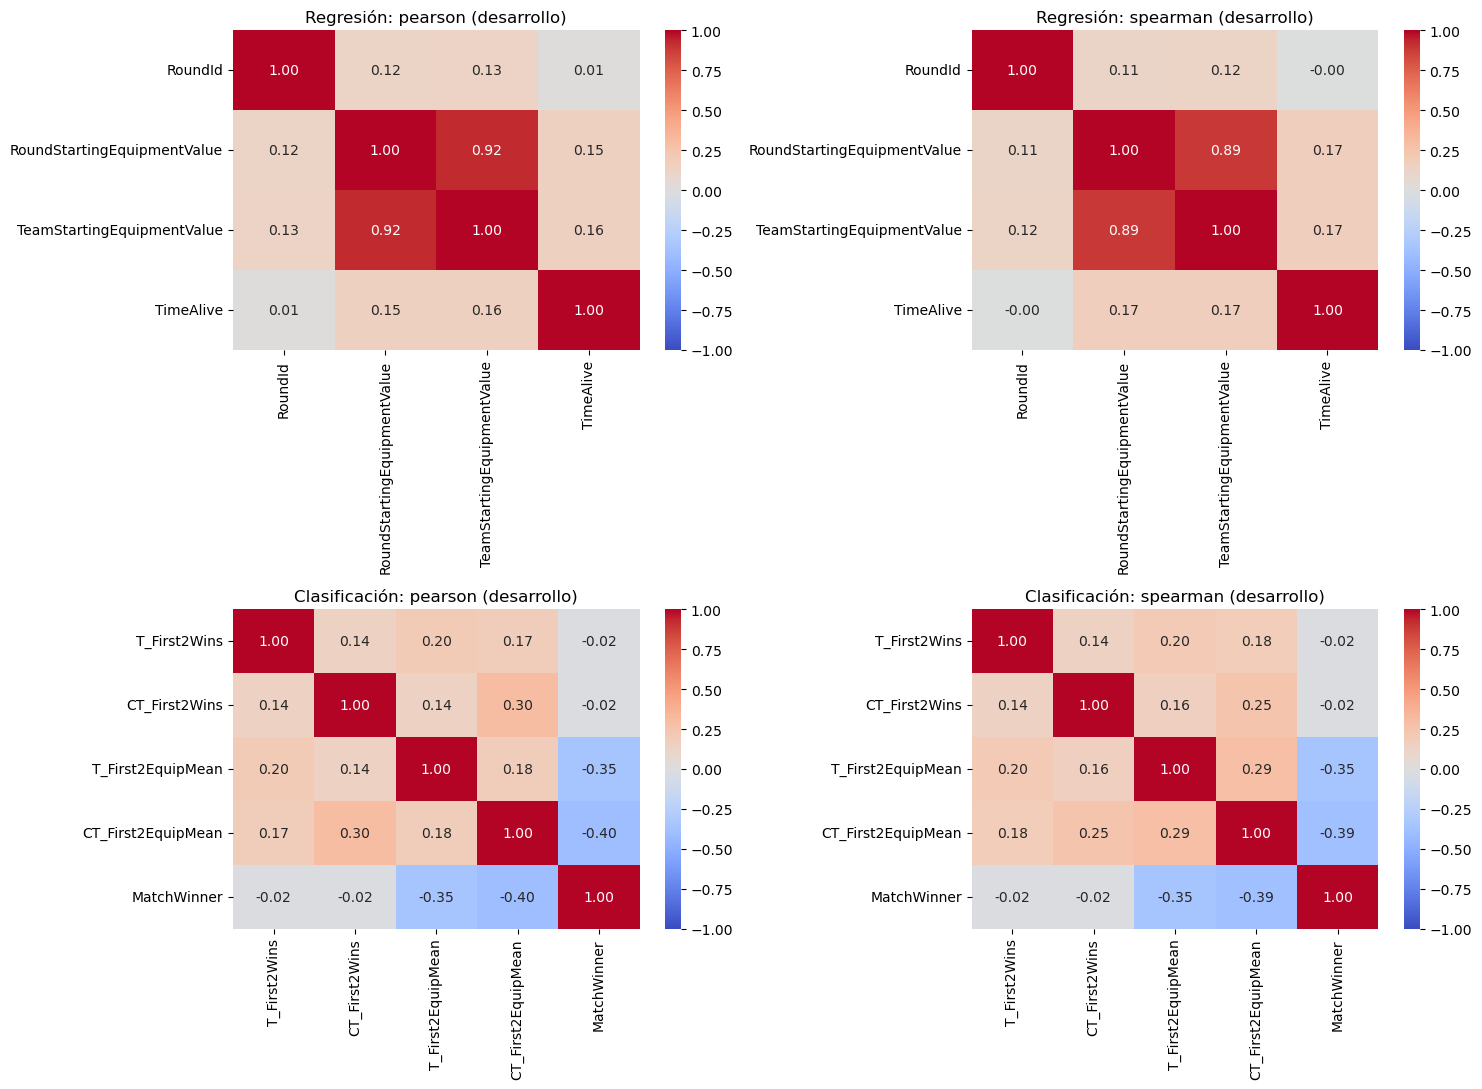

,count,mean
Map,,
de_dust2,120,0.5000
de_inferno,172,0.5000
de_mirage,128,0.5000
de_nuke,72,0.5000


**¿Por qué la tasa de victoria por mapa es exactamente 0,5?** No es casualidad. En cada partida hay un ganador y un perdedor jugando el mismo mapa, así que la mitad de las observaciones de cualquier mapa son victorias. Por lo tanto, el mapa **por sí solo** no puede distinguir ganadores de perdedores. Lo mantenemos como predictor porque podría cambiar cómo se relacionan las otras variables con el resultado (por ejemplo, que la economía pese distinto según el mapa), pero no lo interpretamos como un efecto causal.

**Lectura de las correlaciones.**

*Regresión.* El equipamiento individual (`RoundStartingEquipmentValue`) y el del equipo (`TeamStartingEquipmentValue`) tienen una correlación de Pearson de **0.923** entre sí. Es esperable: si el equipo invierte mucho, cada jugador también suele estar bien equipado. Una correlación tan alta indica **redundancia**, es decir, que ambas variables aportan casi la misma información. Por eso en la sección 4.10 probamos el modelo sin la variable del equipo. Por otro lado, la relación lineal de ambas con `TimeAlive` es débil (0.149 y 0.156): saber cuánto gastó un jugador ayuda poco, por sí solo, a anticipar cuánto sobrevive. Desde ya anticipamos que la regresión será un problema difícil.

*Clasificación.* Las victorias en las primeras rondas observadas casi no se correlacionan con ganar la partida: **-0.019** en el lado T y **-0.019** en el lado CT. En esta base, entonces, ganar las rondas iniciales **no se asocia linealmente** con ganar la partida. Esto va en contra de la intuición detrás de nuestra pregunta de investigación y coincide con el análisis preliminar de la Fase 2 (sección 2.13).

El equipamiento medio de esas rondas, en cambio, sí muestra una asociación moderada, pero **negativa**: **-0.353** (T) y **-0.403** (CT). Leído literalmente, los equipos que ganan la partida tendrían en promedio menos equipamiento en esas rondas. Somos cuidadosos con esta lectura: una correlación no indica causa, y **no** concluimos que gastar menos haga ganar. El patrón podría venir de la dinámica económica del juego o de cómo la fuente registra esta variable, pero no lo comprobamos. Antes de usarlo para recomendaciones habría que confirmar con la fuente cómo se mide.

La tabla siguiente resume la decisión que tomamos con cada variable.


,variable,tarea,justificación,tratamiento
0,Map,Ambas,Categoría nominal; posible contexto de interac...,One-Hot
1,Team,Regresión,Lado conocido al inicio de ronda,One-Hot
2,RoundId,Regresión,"Posición de la ronda, disponible al inicio",Numérica
3,Equipamiento inicial,Ambas,Condición económica disponible en el corte,Escalar si corresponde
4,T_First2Wins / CT_First2Wins,Clasificación,Rendimiento observado antes del corte,Conteos
5,MatchId / InternalTeamId / SteamId,Ambas,Solo trazabilidad/agrupación,Excluir de X
6,ScaledTimeAlive y estadísticas posteriores,Ambas,Fuga de información,Excluir de X
7,OpeningRoundsWon,Clasificación,Combinación determinista de dos predictores,Solo descriptivo


In [51]:
def savefig(name):
    plt.savefig(FIG / name, dpi=130, bbox_inches="tight")
    plt.show()
    plt.close("all")

fig, axes = plt.subplots(2,2,figsize=(15,11))
for row,(label,data,features,target) in enumerate([
    ("Regresión",reg_dev,REG_FEATURES,"TimeAlive"),
    ("Clasificación",cls_dev,CLS_FEATURES,"MatchWinner")]):
    numeric = [c for c in features if pd.api.types.is_numeric_dtype(data[c])] + [target]
    for col,method in enumerate(["pearson","spearman"]):
        matrix = data[numeric].corr(method=method)
        sns.heatmap(matrix,annot=True,fmt=".2f",vmin=-1,vmax=1,cmap="coolwarm",ax=axes[row,col])
        axes[row,col].set_title(f"{label}: {method} (desarrollo)")
        matrix.to_csv(OUT / f"correlacion_{label.lower()}_{method}.csv")
plt.tight_layout(); savefig("correlaciones_desarrollo.png")
map_summary = cls_dev.groupby("Map").MatchWinner.agg(["count","mean"])
display(map_summary)
display(Markdown("**¿Por qué la tasa de victoria por mapa es exactamente 0,5?** No es casualidad. En cada partida hay un ganador y un perdedor jugando el mismo mapa, así que la mitad de las observaciones de cualquier mapa son victorias. Por lo tanto, el mapa **por sí solo** no puede distinguir ganadores de perdedores. Lo mantenemos como predictor porque podría cambiar cómo se relacionan las otras variables con el resultado (por ejemplo, que la economía pese distinto según el mapa), pero no lo interpretamos como un efecto causal."))
reg_corr=reg_dev[["RoundStartingEquipmentValue","TeamStartingEquipmentValue","TimeAlive"]].corr()
cls_corr=cls_dev[["T_First2Wins","CT_First2Wins","T_First2EquipMean","CT_First2EquipMean","MatchWinner"]].corr()
display(Markdown(f"""**Lectura de las correlaciones.**

*Regresión.* El equipamiento individual (`RoundStartingEquipmentValue`) y el del equipo (`TeamStartingEquipmentValue`) tienen una correlación de Pearson de **{reg_corr.loc['RoundStartingEquipmentValue','TeamStartingEquipmentValue']:.3f}** entre sí. Es esperable: si el equipo invierte mucho, cada jugador también suele estar bien equipado. Una correlación tan alta indica **redundancia**, es decir, que ambas variables aportan casi la misma información. Por eso en la sección 4.10 probamos el modelo sin la variable del equipo. Por otro lado, la relación lineal de ambas con `TimeAlive` es débil ({reg_corr.loc['RoundStartingEquipmentValue','TimeAlive']:.3f} y {reg_corr.loc['TeamStartingEquipmentValue','TimeAlive']:.3f}): saber cuánto gastó un jugador ayuda poco, por sí solo, a anticipar cuánto sobrevive. Desde ya anticipamos que la regresión será un problema difícil.

*Clasificación.* Las victorias en las primeras rondas observadas casi no se correlacionan con ganar la partida: **{cls_corr.loc['T_First2Wins','MatchWinner']:.3f}** en el lado T y **{cls_corr.loc['CT_First2Wins','MatchWinner']:.3f}** en el lado CT. En esta base, entonces, ganar las rondas iniciales **no se asocia linealmente** con ganar la partida. Esto va en contra de la intuición detrás de nuestra pregunta de investigación y coincide con el análisis preliminar de la Fase 2 (sección 2.13).

El equipamiento medio de esas rondas, en cambio, sí muestra una asociación moderada, pero **negativa**: **{cls_corr.loc['T_First2EquipMean','MatchWinner']:.3f}** (T) y **{cls_corr.loc['CT_First2EquipMean','MatchWinner']:.3f}** (CT). Leído literalmente, los equipos que ganan la partida tendrían en promedio menos equipamiento en esas rondas. Somos cuidadosos con esta lectura: una correlación no indica causa, y **no** concluimos que gastar menos haga ganar. El patrón podría venir de la dinámica económica del juego o de cómo la fuente registra esta variable, pero no lo comprobamos. Antes de usarlo para recomendaciones habría que confirmar con la fuente cómo se mide.

La tabla siguiente resume la decisión que tomamos con cada variable.
"""))

feature_decisions = pd.DataFrame([
    ["Map", "Ambas", "Categoría nominal; posible contexto de interacciones", "One-Hot"],
    ["Team", "Regresión", "Lado conocido al inicio de ronda", "One-Hot"],
    ["RoundId", "Regresión", "Posición de la ronda, disponible al inicio", "Numérica"],
    ["Equipamiento inicial", "Ambas", "Condición económica disponible en el corte", "Escalar si corresponde"],
    ["T_First2Wins / CT_First2Wins", "Clasificación", "Rendimiento observado antes del corte", "Conteos"],
    ["MatchId / InternalTeamId / SteamId", "Ambas", "Solo trazabilidad/agrupación", "Excluir de X"],
    ["ScaledTimeAlive y estadísticas posteriores", "Ambas", "Fuga de información", "Excluir de X"],
    ["OpeningRoundsWon", "Clasificación", "Combinación determinista de dos predictores", "Solo descriptivo"]
], columns=["variable","tarea","justificación","tratamiento"])
display(feature_decisions)
feature_decisions.to_csv(OUT / "seleccion_caracteristicas.csv", index=False)

## 4.5 Transformación y pipelines

Varias técnicas de preprocesamiento "aprenden" algo de los datos. Por ejemplo, `StandardScaler` calcula la media y la desviación estándar de cada columna. Si hiciéramos ese cálculo con todo el dataset antes de dividirlo, información del conjunto de validación se filtraría al entrenamiento (otra forma de *data leakage*). Para evitarlo usamos un **`Pipeline`** de scikit-learn, que une preprocesamiento y modelo en un solo objeto. Cuando la validación cruzada entrena el pipeline en un fold, el preprocesamiento se ajusta **solo con las filas de entrenamiento de ese fold** y después se aplica a validación.

El preprocesamiento (`ColumnTransformer`) trata cada tipo de variable de forma distinta:

| Tipo de variable | Ejemplos | Transformación | Motivo |
|---|---|---|---|
| Categórica nominal | `Map`, `Team` | **One-Hot Encoding** | Convierte cada categoría en una columna 0/1 sin inventar un orden entre mapas |
| Numérica | equipamiento, conteos de victorias, `RoundId` | **`StandardScaler`** (media 0, desviación 1) | Deja todas las variables en la misma escala |

**¿Por qué escalar?** Algunos algoritmos dependen de la escala de las variables:

- **KNN** y **SVM** usan distancias. Sin escalar, una variable con valores grandes (el equipamiento, en miles) dominaría a otra con valores pequeños (victorias, entre 0 y 2).
- **Ridge** y **regresión logística** penalizan el tamaño de los coeficientes, y esa penalización solo es justa si las variables están en escalas comparables.
- Los **árboles de decisión** no lo necesitan, porque cortan cada variable por umbrales (por ejemplo, `equipamiento > 3000`) y el resultado no cambia al reescalar. Por eso en los árboles usamos `scale=False`.

Configuramos `OneHotEncoder(handle_unknown="ignore")` para que, si en validación aparece una categoría que no estaba en entrenamiento, el pipeline no falle y la codifique con ceros. No imputamos porque en la Fase 3 verificamos que las bases no tienen valores faltantes.

**Modelos que comparamos y por qué**

| Tarea | Modelo | Idea principal |
|---|---|---|
| Regresión | **Ridge** | Regresión lineal con regularización L2: achica los coeficientes para que el modelo no se ajuste de más. `alpha` controla cuánta regularización se aplica |
| Regresión | **Árbol de regresión (CART)** | Divide los datos en regiones con preguntas sí/no y predice el promedio de cada región. Capta relaciones no lineales e interacciones |
| Clasificación | **Regresión logística** | Frontera de decisión lineal. Entrega probabilidades y es fácil de interpretar |
| Clasificación | **KNN** | Clasifica según la clase de los *k* vecinos más cercanos. No aprende una fórmula, compara distancias |
| Clasificación | **SVM** | Busca la frontera con mayor margen entre clases. Con *kernel* RBF puede trazar fronteras curvas |
| Clasificación | **Árbol de clasificación (CART)** | Aprende reglas legibles del tipo "si… entonces…" y capta interacciones entre variables |

También usamos modelos **Dummy**, que siempre predicen la media, la mediana o la clase más frecuente, como **línea base**. No cuentan como modelos exigidos; sirven para responder la pregunta "¿aprender de los datos realmente mejora algo frente a adivinar siempre lo mismo?".

In [52]:
def make_preprocessor(features, scale=True):
    cat = [c for c in features if c in ["Map", "Team"]]
    num = [c for c in features if c not in cat]
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)
    ], remainder="drop", verbose_feature_names_out=False)

def make_pipeline(estimator, features, scale=True):
    return Pipeline([("prep", make_preprocessor(features, scale)), ("model", estimator)])

reg_scoring = {"MAE":"neg_mean_absolute_error", "RMSE":"neg_root_mean_squared_error", "R2":"r2"}
cls_scoring = {"F1_macro":"f1_macro", "Balanced_accuracy":"balanced_accuracy", "Accuracy":"accuracy",
               "Precision_1":make_scorer(precision_score,zero_division=0), "Recall_1":"recall", "ROC_AUC":"roc_auc"}

def cv_record(name, result, metrics, negate=()):
    row = {"modelo":name}
    for metric in metrics:
        factor = -1 if metric in negate else 1
        row[f"{metric}_CV"] = float(factor * np.mean(result[f"test_{metric}"]))
        row[f"{metric}_sd"] = float(np.std(result[f"test_{metric}"], ddof=1))
        row[f"{metric}_train"] = float(factor * np.mean(result[f"train_{metric}"]))
    row["segundos_fit"] = float(np.mean(result["fit_time"]))
    return row

reg_models = {
    "Ridge": (make_pipeline(Ridge(),REG_FEATURES), {"model__alpha":[0.01,0.1,1,10,100]}),
    "Árbol regresión": (make_pipeline(DecisionTreeRegressor(random_state=SEED), REG_FEATURES,False),
                          {"model__max_depth":[3,6,10,None], "model__min_samples_leaf":[20,100,300]})}
cls_models = {
    "Logística": (make_pipeline(LogisticRegression(max_iter=3000,random_state=SEED),CLS_FEATURES),
                   {"model__C":[0.01,0.1,1,10],"model__class_weight":[None,"balanced"]}),
    "KNN": (make_pipeline(KNeighborsClassifier(),CLS_FEATURES),
             {"model__n_neighbors":[5,11,21,41],"model__weights":["uniform","distance"],"model__p":[1,2]}),
    "SVM": (make_pipeline(SVC(random_state=SEED),CLS_FEATURES),
            [{"model__kernel":["linear"],"model__C":[0.1,1,10],"model__class_weight":[None,"balanced"]},
             {"model__kernel":["rbf"],"model__C":[0.1,1,10],"model__gamma":["scale",0.1,1],"model__class_weight":[None,"balanced"]}]),
    "Árbol clasificación": (make_pipeline(DecisionTreeClassifier(random_state=SEED),CLS_FEATURES,False),
                             {"model__criterion":["gini","entropy"],"model__max_depth":[2,4,6],
                              "model__min_samples_leaf":[5,15,30],"model__class_weight":[None,"balanced"]})}

## 4.6 Regresión: entrenamiento y comparación

En esta sección entrenamos los dos regresores y buscamos sus mejores hiperparámetros. Los **hiperparámetros** son configuraciones que el modelo no aprende solo y que debemos elegir nosotros, como la profundidad máxima de un árbol. Para elegirlos usamos **`GridSearchCV`**: prueba todas las combinaciones de una grilla y, para cada una, ejecuta la validación cruzada de 5 folds por partida.

| Modelo | Hiperparámetros probados | Qué controlan |
|---|---|---|
| Ridge | `alpha` ∈ {0,01; 0,1; 1; 10; 100} | Intensidad de la regularización |
| Árbol de regresión | `max_depth` ∈ {3, 6, 10, sin límite}; `min_samples_leaf` ∈ {20, 100, 300} | Profundidad máxima y mínimo de observaciones por hoja. Cuanto más profundo y con hojas más pequeñas, más complejo es el árbol |

scikit-learn siempre **maximiza** la métrica, así que para minimizar el MAE usamos `neg_mean_absolute_error` (el MAE con signo negativo). Al reportar lo volvemos a mostrar como MAE positivo.

Agregamos dos líneas base, **Dummy media** y **Dummy mediana**, que predicen siempre el mismo valor. Si un modelo no supera claramente a estas constantes, no está aprendiendo nada útil de las variables.

**Cómo leer la tabla de resultados**

- `MAE_CV`: MAE promedio en los 5 folds de validación. Es lo que usamos para comparar.
- `MAE_sd`: desviación estándar entre folds, que indica estabilidad.
- `MAE_train`: MAE en los datos de entrenamiento. Si es mucho menor que `MAE_CV`, hay señales de sobreajuste.
- Lo mismo vale para las columnas de RMSE y R².

Todas estas cifras vienen del conjunto de **desarrollo**. Como los mismos folds sirvieron para elegir hiperparámetros y para comparar, los números pueden ser algo optimistas. La estimación honesta del desempeño la entrega la prueba final de la sección 5.1.

In [53]:
Xr, yr = reg_dev[REG_FEATURES], reg_dev.TimeAlive
Xc, yc = cls_dev[CLS_FEATURES], cls_dev.MatchWinner
reg_searches, reg_rows = {}, []
for strategy in ["mean","median"]:
    est = make_pipeline(DummyRegressor(strategy=strategy),REG_FEATURES,False)
    res = cross_validate(est,Xr,yr,cv=reg_folds,scoring=reg_scoring,return_train_score=True,n_jobs=1,error_score="raise")
    reg_rows.append(cv_record(f"Dummy {strategy}",res,reg_scoring,["MAE","RMSE"]))
for name,(pipe,grid) in reg_models.items():
    print("Ajustando",name,flush=True)
    search = GridSearchCV(pipe,grid,scoring=reg_scoring,refit="MAE",cv=reg_folds,n_jobs=1,
                          return_train_score=True,error_score="raise")
    search.fit(Xr,yr)
    reg_searches[name] = search
    scores = cross_validate(search.best_estimator_,Xr,yr,cv=reg_folds,scoring=reg_scoring,
                             return_train_score=True,n_jobs=1,error_score="raise")
    reg_rows.append(cv_record(name,scores,reg_scoring,["MAE","RMSE"]))
    pd.DataFrame(search.cv_results_).to_csv(OUT / f"busqueda_reg_{name.split()[0]}.csv",index=False)
    print("Parámetros elegidos:",search.best_params_)
reg_comparison = pd.DataFrame(reg_rows).sort_values("MAE_CV").reset_index(drop=True)
display(reg_comparison)
reg_comparison.to_csv(OUT / "comparacion_regresion_CV.csv",index=False)
reg_initial_name = min(reg_searches,key=lambda name: -reg_searches[name].best_score_)
reg_initial = clone(reg_searches[reg_initial_name].best_estimator_)
reg_by_name=reg_comparison.set_index("modelo")
reg_best_mae=reg_by_name.loc[reg_initial_name,"MAE_CV"]
reg_median_mae=reg_by_name.loc["Dummy median","MAE_CV"]
ridge_params=reg_searches["Ridge"].best_params_
tree_params=reg_searches["Árbol regresión"].best_params_
display(Markdown(f"""**Lectura inicial.** El **{reg_initial_name}** obtiene el menor MAE medio de validación entre los dos algoritmos ({reg_best_mae:.3f}). Para dimensionar ese número lo comparamos con las líneas base de la misma tabla: predecir siempre la mediana da un MAE de {reg_median_mae:.3f}. La mejora existe, pero es pequeña (alrededor de {100*(1-reg_best_mae/reg_median_mae):.1f} %). Todavía no damos la selección por cerrada: falta revisar la complejidad (4.9) y la comparación de características (4.10)."""))
display(Markdown(f"""**¿Es realmente mejor el árbol que Ridge?** La diferencia de MAE medio entre ambos es **{abs(reg_by_name.loc['Ridge','MAE_CV']-reg_by_name.loc['Árbol regresión','MAE_CV']):.3f}**, mientras que la variación entre folds de cada modelo es {reg_by_name.loc['Ridge','MAE_sd']:.3f} (Ridge) y {reg_by_name.loc['Árbol regresión','MAE_sd']:.3f} (árbol). La diferencia entre modelos es menor que lo que cambia un mismo modelo de un fold a otro. Elegimos el árbol porque tiene el menor MAE medio, como establece nuestro criterio, pero **no afirmamos que sea estadísticamente superior**.

Los R² de validación son muy cercanos a cero (árbol {reg_by_name.loc['Árbol regresión','R2_CV']:.3f}, Ridge {reg_by_name.loc['Ridge','R2_CV']:.3f}). Con las variables disponibles al inicio de la ronda, los modelos explican una parte muy pequeña de la variación de `TimeAlive`. Era esperable por las correlaciones débiles de la sección 4.4: el tiempo que sobrevive un jugador depende sobre todo de lo que pasa *durante* la ronda, información que no usamos a propósito para evitar *data leakage*.

Sobre los hiperparámetros, la búsqueda eligió Ridge con `alpha`={ridge_params['model__alpha']} y un árbol con `max_depth`={tree_params['model__max_depth']} y `min_samples_leaf`={tree_params['model__min_samples_leaf']}. Es decir, la validación prefirió un árbol de profundidad moderada con hojas grandes, no el más complejo de la grilla."""))

Ajustando Ridge


Parámetros elegidos: {'model__alpha': 0.01}
Ajustando Árbol regresión


Parámetros elegidos: {'model__max_depth': 6, 'model__min_samples_leaf': 300}


,modelo,MAE_CV,MAE_sd,MAE_train,RMSE_CV,RMSE_sd,RMSE_train,R2_CV,R2_sd,R2_train,segundos_fit
0,Árbol regresión,24.2533,0.7570,23.9661,35.3110,5.6287,35.0705,0.0406,0.0143,0.0714,0.0604
1,Ridge,24.5261,0.7906,24.5018,35.4450,5.7331,35.7235,0.0339,0.0176,0.0365,0.0423
2,Dummy median,25.3796,0.8920,25.3589,36.2163,5.7686,36.5375,-0.0091,0.0094,-0.0080,0.0347
3,Dummy mean,25.4897,0.8104,25.4732,36.0930,5.5870,36.3922,-0.0034,0.0016,0.0000,0.0304


**Lectura inicial.** El **Árbol regresión** obtiene el menor MAE medio de validación entre los dos algoritmos (24.253). Para dimensionar ese número lo comparamos con las líneas base de la misma tabla: predecir siempre la mediana da un MAE de 25.380. La mejora existe, pero es pequeña (alrededor de 4.4 %). Todavía no damos la selección por cerrada: falta revisar la complejidad (4.9) y la comparación de características (4.10).

**¿Es realmente mejor el árbol que Ridge?** La diferencia de MAE medio entre ambos es **0.273**, mientras que la variación entre folds de cada modelo es 0.791 (Ridge) y 0.757 (árbol). La diferencia entre modelos es menor que lo que cambia un mismo modelo de un fold a otro. Elegimos el árbol porque tiene el menor MAE medio, como establece nuestro criterio, pero **no afirmamos que sea estadísticamente superior**.

Los R² de validación son muy cercanos a cero (árbol 0.041, Ridge 0.034). Con las variables disponibles al inicio de la ronda, los modelos explican una parte muy pequeña de la variación de `TimeAlive`. Era esperable por las correlaciones débiles de la sección 4.4: el tiempo que sobrevive un jugador depende sobre todo de lo que pasa *durante* la ronda, información que no usamos a propósito para evitar *data leakage*.

Sobre los hiperparámetros, la búsqueda eligió Ridge con `alpha`=0.01 y un árbol con `max_depth`=6 y `min_samples_leaf`=300. Es decir, la validación prefirió un árbol de profundidad moderada con hojas grandes, no el más complejo de la grilla.

## 4.7 Clasificación: cuatro familias y métricas

Repetimos el procedimiento para la clasificación, ahora con cuatro familias de algoritmos que aprenden de formas muy distintas. Esto nos permite ver si el problema se resuelve mejor con una frontera lineal (logística), con comparación por cercanía (KNN), con márgenes y fronteras curvas (SVM) o con reglas (árbol).

| Modelo | Hiperparámetros probados | Qué controlan |
|---|---|---|
| Logística | `C` ∈ {0,01; 0,1; 1; 10}; `class_weight` | `C` es el inverso de la regularización: un `C` bajo regulariza más y deja un modelo más simple |
| KNN | `n_neighbors` ∈ {5, 11, 21, 41}; `weights` (uniforme o por distancia); `p` (1 = Manhattan, 2 = euclidiana) | Cuántos vecinos votan, si los más cercanos pesan más y cómo se mide la distancia |
| SVM | `kernel` lineal o RBF; `C`; `gamma` (solo RBF); `class_weight` | Tipo de frontera, tolerancia a errores y qué tan "local" es la frontera curva |
| Árbol | `criterion` (gini / entropía); `max_depth` ∈ {2, 4, 6}; `min_samples_leaf` ∈ {5, 15, 30}; `class_weight` | Cómo se mide la pureza de un nodo y cuánto puede crecer el árbol |

Incluimos `class_weight="balanced"` en la grilla para comprobarlo de forma explícita, aunque sabemos que con una muestra exactamente balanceada (mitad victorias, mitad derrotas) los pesos de ambas clases son iguales y no debería cambiar nada. Lo verificamos en la sección 4.8.

**¿Por qué no usamos solo accuracy?** Porque en este diseño un modelo que siempre responda "derrota" acierta el 50 % de las veces sin haber aprendido nada. Para dejarlo en evidencia incluimos un `DummyClassifier(strategy="most_frequent")`. Su F1 macro será 0,333: obtiene F1 = 0,667 en la clase que siempre predice y 0 en la otra. El F1 macro castiga a un modelo que ignora una de las clases, y las demás métricas nos ayudan a ver si un modelo acierta más en una clase que en la otra.

In [54]:
cls_searches, cls_rows = {}, []
dummy_cls = make_pipeline(DummyClassifier(strategy="most_frequent"),CLS_FEATURES,False)
dummy_scores = cross_validate(dummy_cls,Xc,yc,cv=cls_folds,scoring=cls_scoring,
                              return_train_score=True,n_jobs=1,error_score="raise")
cls_rows.append(cv_record("Dummy mayoritaria",dummy_scores,cls_scoring))
for name,(pipe,grid) in cls_models.items():
    print("Ajustando",name,flush=True)
    search = GridSearchCV(pipe,grid,scoring=cls_scoring,refit="F1_macro",cv=cls_folds,n_jobs=1,
                          return_train_score=True,error_score="raise")
    search.fit(Xc,yc)
    cls_searches[name] = search
    scores = cross_validate(search.best_estimator_,Xc,yc,cv=cls_folds,scoring=cls_scoring,
                             return_train_score=True,n_jobs=1,error_score="raise")
    cls_rows.append(cv_record(name,scores,cls_scoring))
    pd.DataFrame(search.cv_results_).to_csv(OUT / f"busqueda_cls_{name.split()[0]}.csv",index=False)
    print("Parámetros elegidos:",search.best_params_)
cls_comparison = pd.DataFrame(cls_rows).sort_values("F1_macro_CV",ascending=False).reset_index(drop=True)
display(cls_comparison)
cls_comparison.to_csv(OUT / "comparacion_clasificacion_CV.csv",index=False)
cls_initial_name = max(cls_searches,key=lambda name: cls_searches[name].best_score_)
cls_initial = clone(cls_searches[cls_initial_name].best_estimator_)
ranking_cls=cls_comparison[cls_comparison.modelo.isin(cls_searches)].reset_index(drop=True)
cls_by_name=cls_comparison.set_index("modelo")
knn_params=cls_searches["KNN"].best_params_
display(Markdown(f"""**Lectura inicial.** **{cls_initial_name}** obtiene el mayor F1 macro de validación entre los cuatro algoritmos ({cls_by_name.loc[cls_initial_name,'F1_macro_CV']:.3f}). Todos los modelos superan con claridad a la línea base (F1 macro {cls_by_name.loc['Dummy mayoritaria','F1_macro_CV']:.3f}), lo que confirma que las variables sí contienen información para distinguir ganadores de perdedores.

Al revisar la tabla columna por columna destacamos tres cosas:

1. **Los cuatro modelos quedan muy cerca.** Su F1 macro va de {ranking_cls.F1_macro_CV.min():.3f} a {ranking_cls.F1_macro_CV.max():.3f}, y la desviación entre folds ({ranking_cls.F1_macro_sd.min():.3f} a {ranking_cls.F1_macro_sd.max():.3f}) es mayor que esas diferencias. Con esta cantidad de datos, el resultado depende bastante de qué partidas caen en cada fold.
2. **KNN tiene una brecha muy grande entre entrenamiento ({cls_by_name.loc['KNN','F1_macro_train']:.3f}) y validación ({cls_by_name.loc['KNN','F1_macro_CV']:.3f}).** La búsqueda eligió `weights="{knn_params['model__weights']}"`. Con pesos por distancia, cada observación de entrenamiento es su propio vecino más cercano (distancia cero), así que el modelo "recuerda" perfectamente el entrenamiento. Por eso en KNN el valor de entrenamiento no sirve para juzgarlo y hay que mirar solo la validación, que de todos modos es competitiva porque vota con muchos vecinos ({knn_params['model__n_neighbors']}).
3. **La regresión logística casi no tiene brecha** entre entrenamiento ({cls_by_name.loc['Logística','F1_macro_train']:.3f}) y validación ({cls_by_name.loc['Logística','F1_macro_CV']:.3f}): es un modelo simple y estable.

En los modelos donde se probó `class_weight`, la búsqueda eligió `None`, lo que coincide con tener clases exactamente balanceadas."""))
first_cls,second_cls=ranking_cls.iloc[0].modelo,ranking_cls.iloc[1].modelo
extra_cls=", además de ser más simple de interpretar y tener menor brecha entre entrenamiento y validación" if second_cls=="Logística" else ""
display(Markdown(f"""**¿Por qué nos quedamos con {first_cls} y no con {second_cls}?** La diferencia de F1 macro entre ambos es de solo **{ranking_cls.iloc[0].F1_macro_CV-ranking_cls.iloc[1].F1_macro_CV:.4f}**, muy pequeña frente a su variación entre folds: en la práctica rinden igual. Mantenemos {first_cls} porque así lo indica el criterio que definimos antes (mayor F1 macro medio en validación), pero dejamos registrado que {second_cls} es una alternativa igual de competitiva{extra_cls}. Esta elección no demuestra superioridad estadística; la prueba final mostrará cómo se comporta el modelo elegido con partidas nuevas."""))

Ajustando Logística


Parámetros elegidos: {'model__C': 1, 'model__class_weight': None}
Ajustando KNN


Parámetros elegidos: {'model__n_neighbors': 41, 'model__p': 2, 'model__weights': 'distance'}
Ajustando SVM


Parámetros elegidos: {'model__C': 1, 'model__class_weight': None, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Ajustando Árbol clasificación


Parámetros elegidos: {'model__class_weight': None, 'model__criterion': 'entropy', 'model__max_depth': 4, 'model__min_samples_leaf': 15}


,modelo,F1_macro_CV,F1_macro_sd,F1_macro_train,Balanced_accuracy_CV,Balanced_accuracy_sd,Balanced_accuracy_train,Accuracy_CV,Accuracy_sd,Accuracy_train,Precision_1_CV,Precision_1_sd,Precision_1_train,Recall_1_CV,Recall_1_sd,Recall_1_train,ROC_AUC_CV,ROC_AUC_sd,ROC_AUC_train,segundos_fit
0,SVM,0.7503,0.0744,0.7846,0.7504,0.0741,0.7846,0.7504,0.0741,0.7846,0.7512,0.0661,0.7864,0.7445,0.0965,0.7815,0.8101,0.0733,0.8575,0.0117
1,Logística,0.7482,0.0647,0.7480,0.7483,0.0647,0.7480,0.7483,0.0647,0.7480,0.7597,0.0697,0.7521,0.7279,0.0602,0.7398,0.7943,0.0531,0.8036,0.0091
2,KNN,0.7360,0.0550,1.0000,0.7361,0.0549,1.0000,0.7361,0.0549,1.0000,0.7389,0.0505,1.0000,0.7281,0.0685,1.0000,0.8020,0.0584,1.0000,0.0062
3,Árbol clasificación,0.7293,0.0528,0.7631,0.7300,0.0535,0.7632,0.7300,0.0535,0.7632,0.7550,0.0791,0.7722,0.6913,0.0366,0.7470,0.7626,0.0507,0.8289,0.0039
4,Dummy mayoritaria,0.3333,0.0000,0.3333,0.5000,0.0000,0.5000,0.5000,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.5000,0.0035


**Lectura inicial.** **SVM** obtiene el mayor F1 macro de validación entre los cuatro algoritmos (0.750). Todos los modelos superan con claridad a la línea base (F1 macro 0.333), lo que confirma que las variables sí contienen información para distinguir ganadores de perdedores.

Al revisar la tabla columna por columna destacamos tres cosas:

1. **Los cuatro modelos quedan muy cerca.** Su F1 macro va de 0.729 a 0.750, y la desviación entre folds (0.053 a 0.074) es mayor que esas diferencias. Con esta cantidad de datos, el resultado depende bastante de qué partidas caen en cada fold.
2. **KNN tiene una brecha muy grande entre entrenamiento (1.000) y validación (0.736).** La búsqueda eligió `weights="distance"`. Con pesos por distancia, cada observación de entrenamiento es su propio vecino más cercano (distancia cero), así que el modelo "recuerda" perfectamente el entrenamiento. Por eso en KNN el valor de entrenamiento no sirve para juzgarlo y hay que mirar solo la validación, que de todos modos es competitiva porque vota con muchos vecinos (41).
3. **La regresión logística casi no tiene brecha** entre entrenamiento (0.748) y validación (0.748): es un modelo simple y estable.

En los modelos donde se probó `class_weight`, la búsqueda eligió `None`, lo que coincide con tener clases exactamente balanceadas.

**¿Por qué nos quedamos con SVM y no con Logística?** La diferencia de F1 macro entre ambos es de solo **0.0021**, muy pequeña frente a su variación entre folds: en la práctica rinden igual. Mantenemos SVM porque así lo indica el criterio que definimos antes (mayor F1 macro medio en validación), pero dejamos registrado que Logística es una alternativa igual de competitiva, además de ser más simple de interpretar y tener menor brecha entre entrenamiento y validación. Esta elección no demuestra superioridad estadística; la prueba final mostrará cómo se comporta el modelo elegido con partidas nuevas.

### 4.7.1 Matrices de confusión y curvas ROC de los cuatro candidatos

La tabla anterior resume cada modelo en números, pero no muestra **en qué se equivoca**. Para eso usamos la matriz de confusión y la curva ROC.

**¿De dónde salen estas predicciones?** Usamos `cross_val_predict`, que genera predicciones *out-of-fold* (OOF): cada fila se predice con el modelo entrenado en los **otros** cuatro folds, nunca con uno que la haya visto. Así obtenemos una predicción "honesta" para cada una de las 492 filas de desarrollo. Aun así, como los hiperparámetros se eligieron con estos mismos folds, este diagnóstico sigue siendo parte de la selección y no reemplaza la prueba final.

**Cómo leer la matriz de confusión.** Usamos `confusion_matrix(y_real, y_predicho, labels=[0,1])`: las filas son la clase real y las columnas la clase predicha.

|  | Predicho: Derrota (0) | Predicho: Victoria (1) |
|---|---|---|
| **Real: Derrota (0)** | TN: derrota bien reconocida | FP: se predijo victoria, pero perdió |
| **Real: Victoria (1)** | FN: se predijo derrota, pero ganó | TP: victoria bien reconocida |

Un buen modelo concentra los valores en la diagonal (TN y TP).

**Cómo leer la curva ROC.** Muestra, para todos los umbrales posibles, la relación entre la tasa de verdaderos positivos (recall) y la tasa de falsos positivos. Mientras más se acerca la curva a la esquina superior izquierda, mejor separa el modelo las dos clases. La diagonal punteada representa un modelo que adivina al azar (AUC = 0,5). Para construirla no se usan las etiquetas 0/1, sino un valor continuo: la probabilidad de victoria en logística, KNN y árbol, y el *score* de `decision_function` en SVM.

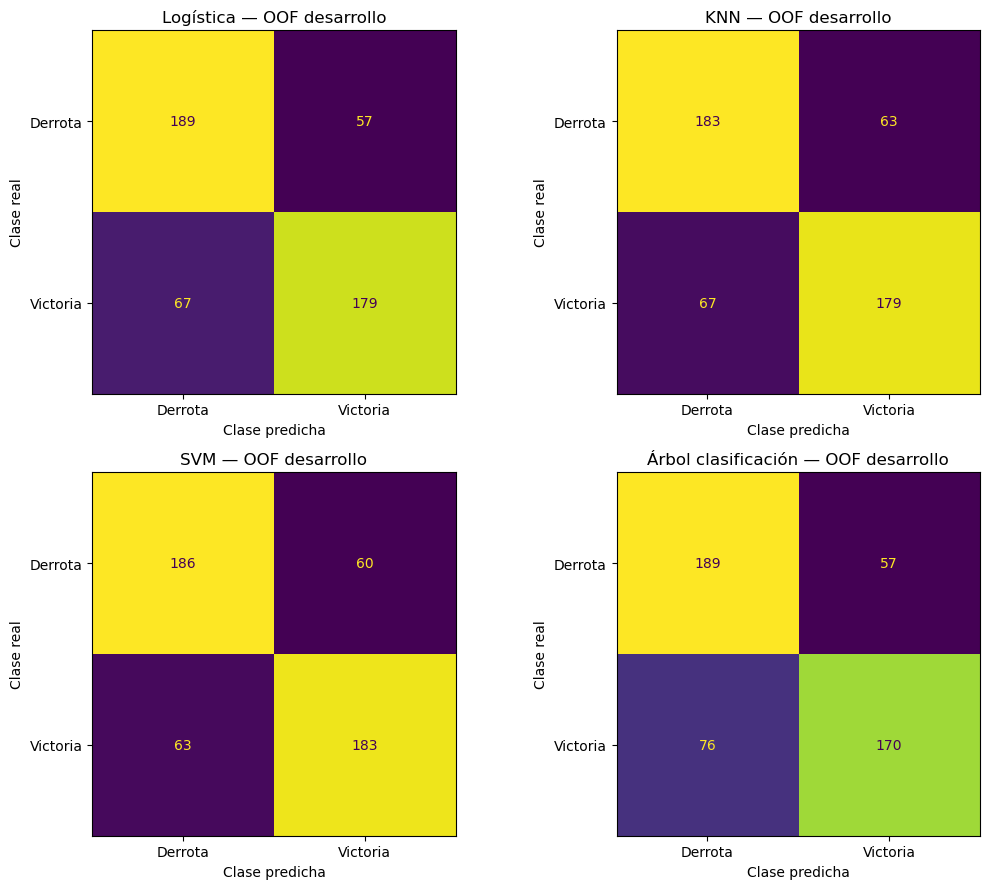

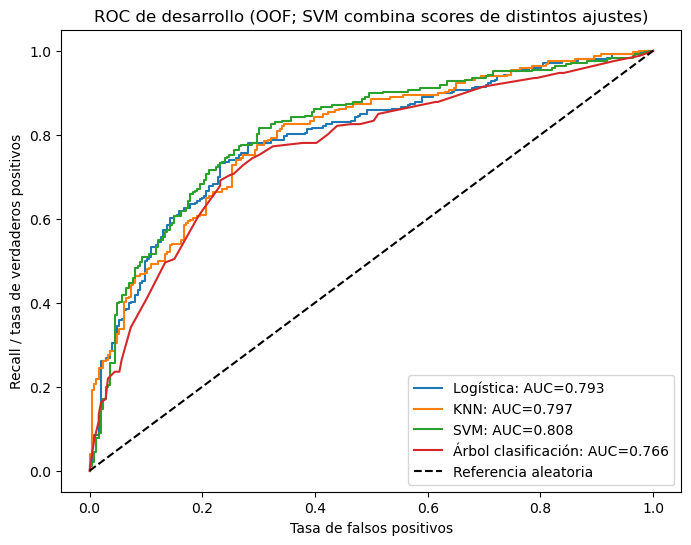

,clase,precision,recall,f1-score,support,modelo
0,0,0.7383,0.7683,0.7530,246.0000,Logística
1,1,0.7585,0.7276,0.7427,246.0000,Logística
2,accuracy,0.7480,0.7480,0.7480,0.7480,Logística
3,macro avg,0.7484,0.7480,0.7479,492.0000,Logística
4,weighted avg,0.7484,0.7480,0.7479,492.0000,Logística
5,0,0.7320,0.7439,0.7379,246.0000,KNN
6,1,0.7397,0.7276,0.7336,246.0000,KNN
7,accuracy,0.7358,0.7358,0.7358,0.7358,KNN
8,macro avg,0.7358,0.7358,0.7358,492.0000,KNN
9,weighted avg,0.7358,0.7358,0.7358,492.0000,KNN


**Lectura de las matrices y del reporte.** Los cuatro candidatos se equivocan en cantidades parecidas en ambas clases, es decir, ninguno tiende a predecir solo victoria o solo derrota. Por ejemplo, SVM reconoce 183 de 246 victorias y 186 de 246 derrotas. El que más se aleja de ese equilibrio es el árbol de clasificación: su recall de victoria (0.691) es menor que su recall de derrota (0.768), así que tiende a pronosticar derrota algo más seguido.

En las curvas ROC, todos los modelos quedan claramente por encima de la diagonal aleatoria: ordenan razonablemente bien a ganadores y perdedores.

**Precaución al leer la AUC de este gráfico.** Cada curva junta predicciones de cinco modelos distintos (uno por fold). En SVM esto es más delicado, porque sus *scores* no son probabilidades y su escala puede cambiar de un ajuste a otro. Por eso usamos esta curva solo de forma descriptiva. Para comparar modelos usamos la AUC promedio calculada **dentro** de cada fold (tabla de la sección 4.7), y la AUC definitiva se calcula en la prueba final con un único modelo.

In [55]:
cls_oof = {}
fig, axes = plt.subplots(2,2,figsize=(11,9))
oof_reports = []
for ax,(name,search) in zip(axes.flat,cls_searches.items()):
    est = clone(search.best_estimator_)
    pred = cross_val_predict(est,Xc,yc,cv=cls_folds,method="predict",n_jobs=1)
    method = "decision_function" if name == "SVM" else "predict_proba"
    raw_score = cross_val_predict(est,Xc,yc,cv=cls_folds,method=method,n_jobs=1)
    score = raw_score if method == "decision_function" else raw_score[:,1]
    cls_oof[name] = {"pred":pred,"score":score}
    ConfusionMatrixDisplay.from_predictions(yc,pred,labels=[0,1],display_labels=["Derrota","Victoria"],ax=ax,colorbar=False)
    ax.set_title(name + " — OOF desarrollo")
    ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
    report = pd.DataFrame(classification_report(yc,pred,labels=[0,1],output_dict=True,zero_division=0)).T
    report["modelo"] = name
    oof_reports.append(report.reset_index(names="clase"))
plt.tight_layout(); savefig("matrices_cuatro_clasificadores_OOF.png")
fig, ax = plt.subplots(figsize=(8,6))
for name, values in cls_oof.items():
    fpr,tpr,_ = roc_curve(yc,values["score"])
    ax.plot(fpr,tpr,label=f"{name}: AUC={roc_auc_score(yc,values['score']):.3f}")
ax.plot([0,1],[0,1],"k--",label="Referencia aleatoria")
ax.set(xlabel="Tasa de falsos positivos",ylabel="Recall / tasa de verdaderos positivos",title="ROC de desarrollo (OOF; SVM combina scores de distintos ajustes)")
ax.legend(); savefig("ROC_cuatro_clasificadores_OOF.png")
oof_report_table = pd.concat(oof_reports,ignore_index=True)
display(oof_report_table)
oof_report_table.to_csv(OUT / "reportes_clasificacion_OOF.csv",index=False)
tn_o,fp_o,fn_o,tp_o=confusion_matrix(yc,cls_oof[cls_initial_name]["pred"],labels=[0,1]).ravel()
tree_rep=oof_report_table[oof_report_table.modelo=="Árbol clasificación"].set_index("clase")
display(Markdown(f"""**Lectura de las matrices y del reporte.** Los cuatro candidatos se equivocan en cantidades parecidas en ambas clases, es decir, ninguno tiende a predecir solo victoria o solo derrota. Por ejemplo, {cls_initial_name} reconoce {tp_o} de {tp_o+fn_o} victorias y {tn_o} de {tn_o+fp_o} derrotas. El que más se aleja de ese equilibrio es el árbol de clasificación: su recall de victoria ({tree_rep.loc['1','recall']:.3f}) es menor que su recall de derrota ({tree_rep.loc['0','recall']:.3f}), así que tiende a pronosticar derrota algo más seguido.

En las curvas ROC, todos los modelos quedan claramente por encima de la diagonal aleatoria: ordenan razonablemente bien a ganadores y perdedores.

**Precaución al leer la AUC de este gráfico.** Cada curva junta predicciones de cinco modelos distintos (uno por fold). En SVM esto es más delicado, porque sus *scores* no son probabilidades y su escala puede cambiar de un ajuste a otro. Por eso usamos esta curva solo de forma descriptiva. Para comparar modelos usamos la AUC promedio calculada **dentro** de cada fold (tabla de la sección 4.7), y la AUC definitiva se calcula en la prueba final con un único modelo."""))

## 4.8 Balance de clases: aplicación y experimento controlado

Un dataset está **desbalanceado** cuando una clase tiene muchas más observaciones que la otra. En ese caso los modelos tienden a favorecer a la clase mayoritaria, y métricas como accuracy pueden verse engañosamente buenas.

**¿Nuestro dataset está desbalanceado?** No. Cada partida aporta exactamente un ganador y un perdedor, así que la clasificación queda 50/50 por construcción (lo vimos en 4.1 y 4.3). Las partidas con etiquetas dudosas no las "compensamos" sobremuestreando: simplemente las excluimos.

Como la evaluación pide aplicar técnicas de balance, abordamos el tema en dos partes.

**Parte A: comprobación con los datos reales.** Aplicamos pesos de clase (`class_weight="balanced"`) y sobremuestreo (`RandomOverSampler`) a la regresión logística con los folds originales. Esperamos que **no cambie nada**, porque no hay clase minoritaria que corregir. Sirve para mostrar que la técnica no se aplica "por aplicar".

**Parte B: experimento con desbalance simulado.** Para ver las técnicas funcionando creamos un desbalance artificial:

1. En cada fold, dentro del **entrenamiento**, conservamos solo un tercio de los ganadores. Queda una proporción aproximada de 3 derrotas por cada victoria.
2. Entrenamos regresión logística con tres estrategias sobre esas mismas filas reducidas:
   - **Sin corrección** (referencia).
   - **Pesos de clase:** el modelo penaliza más los errores en la clase minoritaria, sin cambiar los datos.
   - **Sobremuestreo aleatorio:** se repiten al azar filas de la clase minoritaria hasta igualar ambas clases.
3. Evaluamos siempre sobre la **validación original, sin modificar** (partidas completas y distribución natural). El balanceo se aplica solo al entrenamiento: si balanceáramos también la validación, mediríamos sobre datos que no representan la realidad.
4. Repetimos con tres semillas para no depender de un único sorteo.

Este experimento rompe a propósito algunas parejas ganador/perdedor dentro del entrenamiento para simular un sesgo de muestreo, pero **nunca** reparte una partida entre entrenamiento y validación.

**¿Por qué sobremuestreo aleatorio y no SMOTE?** SMOTE crea observaciones nuevas interpolando entre vecinos. En nuestros datos eso podría generar valores imposibles, como 1,4 rondas ganadas o mezclas de mapas. El sobremuestreo aleatorio solo repite filas reales, así que respeta mapas, conteos y valores económicos válidos. SMOTENC, la variante para datos mixtos, maneja mejor las categorías, pero tampoco garantiza conteos enteros, y para este experimento no necesitamos datos sintéticos.

El sobremuestreo va dentro de un `Pipeline` de `imblearn`, lo que asegura que se aplique solo al entrenar y nunca sobre los datos de validación.

,fold,original_0,original_1,resample_0,resample_1
0,1,196,196,196,196
1,2,197,197,197,197
2,3,197,197,197,197
3,4,197,197,197,197
4,5,197,197,197,197


F1_macro        Balanced_accuracy       
                   mean    std              mean    std
estrategia                                             
pesos            0.7482 0.0647            0.7483 0.0647
sin corrección   0.7482 0.0647            0.7483 0.0647
sobremuestreo    0.7482 0.0647            0.7483 0.0647

F1_macro        Balanced_accuracy        Recall_1         \
                   mean    std              mean    std     mean    std   
estrategia                                                                
pesos            0.7333 0.0692            0.7334 0.0692   0.7294 0.0716   
sin corrección   0.6527 0.0434            0.6749 0.0380   0.4268 0.0607   
sobremuestreo    0.7326 0.0686            0.7327 0.0686   0.7267 0.0762   

               Recall_0         
                   mean    std  
estrategia                      
pesos            0.7375 0.0770  
sin corrección   0.9231 0.0477  
sobremuestreo    0.7388 0.0680

,TN,FP,FN,TP
estrategia,,,,
pesos,544,194,200,538
sin corrección,681,57,423,315
sobremuestreo,545,193,202,536


**Nota sobre la tabla TN/FP/FN/TP:** suma las 15 evaluaciones (5 folds × 3 semillas). Cada partida de desarrollo se valida una vez por semilla, así que estos totales no representan partidas adicionales independientes.

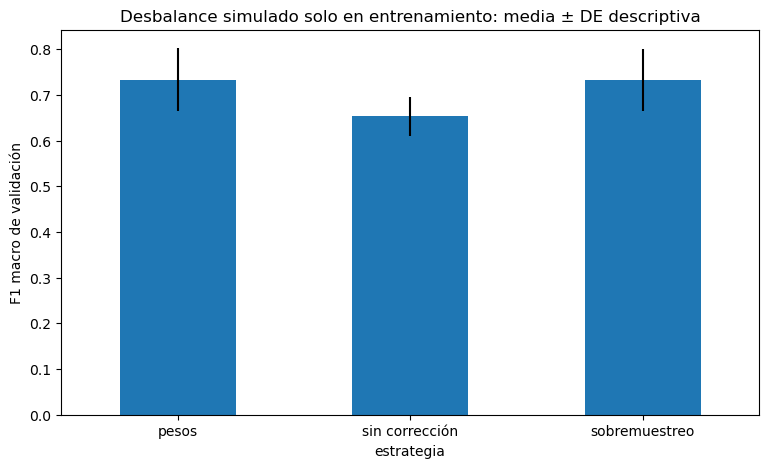

**Conclusión de balance.**

*Parte A (datos reales).* La primera tabla muestra que `RandomOverSampler` no agrega ninguna fila: los conteos antes y después son idénticos. La segunda muestra que las tres estrategias obtienen el mismo F1 macro (sin corrección 0.748, pesos 0.748, sobremuestreo 0.748). Es lo esperado: con clases balanceadas no hay nada que corregir.

*Parte B (desbalance simulado).* Aquí sí se ven el efecto del desbalance y el de su corrección.

- **Sin corrección**, el modelo se inclina hacia la clase mayoritaria (derrota): reconoce el 92.3% de las derrotas, pero solo el 42.7% de las victorias. Su F1 macro medio baja a **0.653**.
- **Con pesos de clase** el F1 macro sube a **0.733** y **con sobremuestreo** a **0.733**. Ambas técnicas equilibran los recalls (con pesos: victoria 72.9%, derrota 73.7%) y quedan cerca del rendimiento con datos balanceados (0.748).
- Las dos técnicas logran casi el mismo resultado, lo que tiene sentido: ambas hacen que la clase minoritaria "pese" lo mismo que la mayoritaria durante el entrenamiento.

La tabla TN/FP/FN/TP lo confirma: sin corrección hay 423 victorias clasificadas como derrotas (FN), y con pesos ese número baja a 200.

Tomamos estas cifras como descriptivas. Las 15 evaluaciones comparten datos, así que no son 15 experimentos independientes. El experimento sirve para mostrar cómo funcionan las técnicas sin modificar nuestra población principal, donde el balance ya existe de forma natural.

In [56]:
balance_counts, natural_rows, simulated_rows = [], [], []
for fold,(tr,va) in enumerate(cls_folds,1):
    Xt,yt = Xc.iloc[tr],yc.iloc[tr]
    Xv,yv = Xc.iloc[va],yc.iloc[va]
    ros = RandomOverSampler(random_state=SEED)
    _, y_res = ros.fit_resample(Xt,yt)
    balance_counts.append({"fold":fold,"original_0":int((yt==0).sum()),"original_1":int((yt==1).sum()),
                           "resample_0":int((y_res==0).sum()),"resample_1":int((y_res==1).sum())})
    for strategy in ["sin corrección","pesos","sobremuestreo"]:
        model = LogisticRegression(C=1,max_iter=3000,random_state=SEED,
                                   class_weight="balanced" if strategy=="pesos" else None)
        steps = [("prep",make_preprocessor(CLS_FEATURES))]
        if strategy=="sobremuestreo": steps.append(("balance",RandomOverSampler(random_state=SEED)))
        pipe = ImbPipeline(steps+[("model",model)])
        pipe.fit(Xt,yt); pred=pipe.predict(Xv)
        natural_rows.append({"fold":fold,"estrategia":strategy,"F1_macro":f1_score(yv,pred,average="macro"),
                            "Balanced_accuracy":balanced_accuracy_score(yv,pred)})
    for seed in [42,43,44]:
        rng = np.random.default_rng(seed + fold*100)
        winner_idx = tr[yc.iloc[tr].to_numpy()==1]
        loser_idx = tr[yc.iloc[tr].to_numpy()==0]
        reduced = np.sort(np.concatenate([loser_idx,rng.choice(winner_idx,size=max(1,len(winner_idx)//3),replace=False)]))
        assert set(cls_dev.iloc[reduced].MatchId).isdisjoint(cls_dev.iloc[va].MatchId)
        for strategy in ["sin corrección","pesos","sobremuestreo"]:
            model = LogisticRegression(C=1,max_iter=3000,random_state=seed,
                                       class_weight="balanced" if strategy=="pesos" else None)
            steps=[("prep",make_preprocessor(CLS_FEATURES))]
            if strategy=="sobremuestreo": steps.append(("balance",RandomOverSampler(random_state=seed)))
            pipe=ImbPipeline(steps+[("model",model)])
            pipe.fit(Xc.iloc[reduced],yc.iloc[reduced]); pred=pipe.predict(Xv)
            tn,fp,fn,tp=confusion_matrix(yv,pred,labels=[0,1]).ravel()
            simulated_rows.append({"fold":fold,"seed":seed,"estrategia":strategy,
                "train_0":int((yc.iloc[reduced]==0).sum()),"train_1":int((yc.iloc[reduced]==1).sum()),
                "F1_macro":f1_score(yv,pred,average="macro"),"Balanced_accuracy":balanced_accuracy_score(yv,pred),
                "Recall_1":recall_score(yv,pred),"Recall_0":recall_score(yv,pred,pos_label=0),
                "TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp)})
balance_counts=pd.DataFrame(balance_counts)
natural_balance=pd.DataFrame(natural_rows)
simulated_balance=pd.DataFrame(simulated_rows)
display(balance_counts)
display(natural_balance.groupby("estrategia")[["F1_macro","Balanced_accuracy"]].agg(["mean","std"]))
balance_summary=simulated_balance.groupby("estrategia")[["F1_macro","Balanced_accuracy","Recall_1","Recall_0"]].agg(["mean","std"])
display(balance_summary)
display(simulated_balance.groupby("estrategia")[["TN","FP","FN","TP"]].sum())
display(Markdown("**Nota sobre la tabla TN/FP/FN/TP:** suma las 15 evaluaciones (5 folds × 3 semillas). Cada partida de desarrollo se valida una vez por semilla, así que estos totales no representan partidas adicionales independientes."))
balance_counts.to_csv(OUT / "balance_conteos_originales.csv",index=False)
natural_balance.to_csv(OUT / "balance_distribucion_natural.csv",index=False)
simulated_balance.to_csv(OUT / "balance_experimento_controlado.csv",index=False)
fig,ax=plt.subplots(figsize=(9,5))
simulated_balance.groupby("estrategia")["F1_macro"].mean().plot.bar(ax=ax,yerr=simulated_balance.groupby("estrategia")["F1_macro"].std(),rot=0)
ax.set(ylabel="F1 macro de validación",title="Desbalance simulado solo en entrenamiento: media ± DE descriptiva")
savefig("balance_experimento.png")
means=simulated_balance.groupby("estrategia").F1_macro.mean()
natural_f1=natural_balance.groupby("estrategia").F1_macro.mean()
sim_recalls=simulated_balance.groupby("estrategia")[["Recall_1","Recall_0"]].mean()
sim_conf=simulated_balance.groupby("estrategia")[["TN","FP","FN","TP"]].sum()
display(Markdown(f"""**Conclusión de balance.**

*Parte A (datos reales).* La primera tabla muestra que `RandomOverSampler` no agrega ninguna fila: los conteos antes y después son idénticos. La segunda muestra que las tres estrategias obtienen el mismo F1 macro (sin corrección {natural_f1['sin corrección']:.3f}, pesos {natural_f1['pesos']:.3f}, sobremuestreo {natural_f1['sobremuestreo']:.3f}). Es lo esperado: con clases balanceadas no hay nada que corregir.

*Parte B (desbalance simulado).* Aquí sí se ven el efecto del desbalance y el de su corrección.

- **Sin corrección**, el modelo se inclina hacia la clase mayoritaria (derrota): reconoce el {sim_recalls.loc['sin corrección','Recall_0']:.1%} de las derrotas, pero solo el {sim_recalls.loc['sin corrección','Recall_1']:.1%} de las victorias. Su F1 macro medio baja a **{means['sin corrección']:.3f}**.
- **Con pesos de clase** el F1 macro sube a **{means['pesos']:.3f}** y **con sobremuestreo** a **{means['sobremuestreo']:.3f}**. Ambas técnicas equilibran los recalls (con pesos: victoria {sim_recalls.loc['pesos','Recall_1']:.1%}, derrota {sim_recalls.loc['pesos','Recall_0']:.1%}) y quedan cerca del rendimiento con datos balanceados ({natural_f1['sin corrección']:.3f}).
- Las dos técnicas logran casi el mismo resultado, lo que tiene sentido: ambas hacen que la clase minoritaria "pese" lo mismo que la mayoritaria durante el entrenamiento.

La tabla TN/FP/FN/TP lo confirma: sin corrección hay {sim_conf.loc['sin corrección','FN']} victorias clasificadas como derrotas (FN), y con pesos ese número baja a {sim_conf.loc['pesos','FN']}.

Tomamos estas cifras como descriptivas. Las 15 evaluaciones comparten datos, así que no son 15 experimentos independientes. El experimento sirve para mostrar cómo funcionan las técnicas sin modificar nuestra población principal, donde el balance ya existe de forma natural."""))

## 4.9 Complejidad: overfitting y underfitting

El objetivo de un modelo es **generalizar**, es decir, predecir bien datos que no vio al entrenar. Hay dos formas de fallar:

- **Overfitting (sobreajuste):** el modelo aprende "demasiado", incluido el ruido del entrenamiento. Se reconoce porque su desempeño en **entrenamiento es mucho mejor que en validación**, y esa brecha crece a medida que el modelo se hace más complejo.
- **Underfitting (subajuste):** el modelo es demasiado simple para captar el patrón. Se reconoce porque rinde mal **incluso en entrenamiento** y apenas supera a la línea base.

Para observar ambos fenómenos usamos el árbol de decisión, porque su complejidad depende de un solo parámetro fácil de entender: la **profundidad** (`max_depth`). Un árbol de profundidad 1 hace una sola pregunta; un árbol sin límite puede seguir dividiendo hasta tener hojas con una sola observación. Entrenamos árboles de distintas profundidades, medimos su desempeño en entrenamiento y en validación cruzada (con los mismos folds por partida) y graficamos ambas curvas. No fijamos una brecha "aceptable" universal: interpretamos la tendencia.

En los demás modelos la complejidad depende de otros hiperparámetros, que ya ajustamos en las búsquedas de 4.6 y 4.7:

- **Ridge:** un `alpha` mayor achica los coeficientes y deja un modelo más simple.
- **Logística y SVM:** un `C` mayor reduce la regularización y deja un modelo más flexible.
- **KNN:** con pocos vecinos las fronteras son muy locales (riesgo de sobreajuste); con muchos vecinos son más suaves.
- **Árboles:** más profundidad y hojas más pequeñas significan más complejidad.

,tarea,profundidad,train,CV,CV_sd
0,regresión,1,24.6450,24.6769,0.7802
1,regresión,3,24.2369,24.3936,0.7278
2,regresión,6,23.7989,24.3416,0.8691
3,regresión,10,22.6294,25.1892,0.6739
4,regresión,sin límite,6.0278,32.3058,0.7021
5,clasificación,1,0.7135,0.7093,0.0588
6,clasificación,2,0.7466,0.7074,0.0596
7,clasificación,4,0.7726,0.6885,0.0493
8,clasificación,6,0.8327,0.6845,0.0543
9,clasificación,sin límite,1.0000,0.6609,0.0153


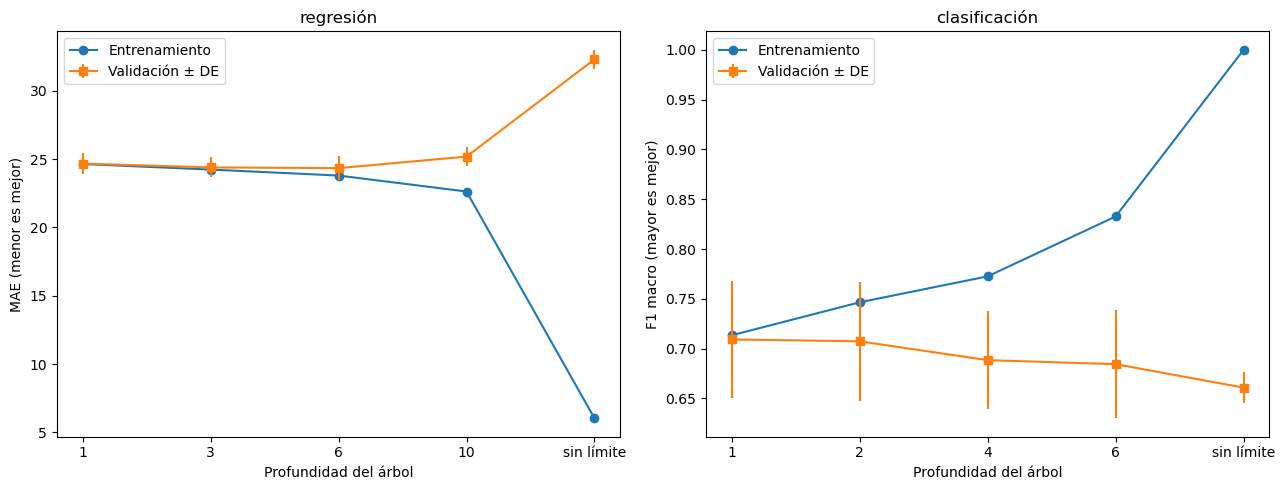

**Regresión (MAE, menor es mejor).** Con profundidad 1, el error de entrenamiento (24.645) y el de validación (24.677) son casi iguales: el árbol es simple y no memoriza. Al aumentar la profundidad, el error de entrenamiento baja siempre, pero el de validación deja de mejorar y luego empeora. En el árbol sin límite la diferencia es extrema: MAE 6.028 en entrenamiento frente a 32.306 en validación. El árbol memorizó el entrenamiento y perdió capacidad de generalizar; es un caso claro de **sobreajuste**. El mejor MAE de validación aparece con profundidad 6, lo que coincide con la profundidad que eligió la búsqueda de 4.6.

**Clasificación (F1 macro, mayor es mejor).** Aquí el patrón es todavía más marcado. El F1 de entrenamiento sube de 0.713 (profundidad 1) a 1.000 (sin límite, es decir, acierta todo el entrenamiento), mientras que el F1 de validación baja de 0.709 a 0.661. El mejor resultado de validación lo obtiene el árbol más simple (profundidad 1). Con tan pocas variables y observaciones, cada nivel extra del árbol aprende detalles de las partidas de entrenamiento que no se repiten en otras. En 4.7 la búsqueda eligió una profundidad mayor, pero combinada con `min_samples_leaf`, que limita el tamaño de las hojas; aquí variamos solo la profundidad, sin esa restricción.

In [57]:
complexity_rows=[]
for task,depths,X,y,folds,features,scoring in [
    ("regresión",[1,3,6,10,None],Xr,yr,reg_folds,REG_FEATURES,"neg_mean_absolute_error"),
    ("clasificación",[1,2,4,6,None],Xc,yc,cls_folds,CLS_FEATURES,"f1_macro")]:
    for depth in depths:
        model=DecisionTreeRegressor(max_depth=depth,random_state=SEED) if task=="regresión" else DecisionTreeClassifier(max_depth=depth,random_state=SEED)
        result=cross_validate(make_pipeline(model,features,False),X,y,cv=folds,scoring=scoring,
                              return_train_score=True,n_jobs=1,error_score="raise")
        factor=-1 if task=="regresión" else 1
        complexity_rows.append({"tarea":task,"profundidad":"sin límite" if depth is None else str(depth),
            "train":factor*np.mean(result["train_score"]),"CV":factor*np.mean(result["test_score"]),
            "CV_sd":np.std(result["test_score"],ddof=1)})
complexity=pd.DataFrame(complexity_rows)
display(complexity)
complexity.to_csv(OUT / "curvas_complejidad.csv",index=False)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,task in zip(axes,["regresión","clasificación"]):
    part=complexity[complexity.tarea==task]
    ax.plot(part.profundidad,part.train,"o-",label="Entrenamiento")
    ax.errorbar(part.profundidad,part.CV,yerr=part.CV_sd,fmt="s-",label="Validación ± DE")
    ax.set(xlabel="Profundidad del árbol",ylabel="MAE (menor es mejor)" if task=="regresión" else "F1 macro (mayor es mejor)",title=task)
    ax.legend()
plt.tight_layout(); savefig("curvas_complejidad.png")
reg_part=complexity[complexity.tarea=="regresión"].reset_index(drop=True)
cls_part=complexity[complexity.tarea=="clasificación"].reset_index(drop=True)
reg_best_depth=reg_part.loc[reg_part.CV.idxmin(),"profundidad"]
cls_best_depth=cls_part.loc[cls_part.CV.idxmax(),"profundidad"]
display(Markdown(f"""**Regresión (MAE, menor es mejor).** Con profundidad 1, el error de entrenamiento ({reg_part.train.iloc[0]:.3f}) y el de validación ({reg_part.CV.iloc[0]:.3f}) son casi iguales: el árbol es simple y no memoriza. Al aumentar la profundidad, el error de entrenamiento baja siempre, pero el de validación deja de mejorar y luego empeora. En el árbol sin límite la diferencia es extrema: MAE {reg_part.train.iloc[-1]:.3f} en entrenamiento frente a {reg_part.CV.iloc[-1]:.3f} en validación. El árbol memorizó el entrenamiento y perdió capacidad de generalizar; es un caso claro de **sobreajuste**. El mejor MAE de validación aparece con profundidad {reg_best_depth}, lo que coincide con la profundidad que eligió la búsqueda de 4.6."""))
display(Markdown(f"""**Clasificación (F1 macro, mayor es mejor).** Aquí el patrón es todavía más marcado. El F1 de entrenamiento sube de {cls_part.train.iloc[0]:.3f} (profundidad 1) a {cls_part.train.iloc[-1]:.3f} (sin límite, es decir, acierta todo el entrenamiento), mientras que el F1 de validación baja de {cls_part.CV.iloc[0]:.3f} a {cls_part.CV.iloc[-1]:.3f}. El mejor resultado de validación lo obtiene el árbol más simple (profundidad {cls_best_depth}). Con tan pocas variables y observaciones, cada nivel extra del árbol aprende detalles de las partidas de entrenamiento que no se repiten en otras. En 4.7 la búsqueda eligió una profundidad mayor, pero combinada con `min_samples_leaf`, que limita el tamaño de las hojas; aquí variamos solo la profundidad, sin esa restricción."""))

**¿Y el subajuste?** En regresión, incluso los mejores árboles tienen errores parecidos en entrenamiento y validación (alrededor de 24 unidades) y mejoran muy poco frente a predecir la mediana. Este patrón, con error alto en ambos conjuntos, es el típico del **subajuste**. Sin embargo, no creemos que se deba a que el modelo sea demasiado simple, porque un árbol más profundo no mejora la validación. La explicación más probable es que **las variables disponibles al inicio de la ronda contienen poca información sobre cuánto sobrevivirá un jugador**. Con estas curvas no podemos separar con certeza las dos causas (modelo insuficiente o predictores insuficientes), pero la evidencia apunta a la segunda.

En resumen, esta sección justifica por qué **no elegimos el modelo con mejor ajuste en entrenamiento**: el árbol sin límite sería el "mejor" en entrenamiento y el peor en validación.

## 4.10 Comparación dirigida de características y selección cerrada

Hasta aquí elegimos el mejor algoritmo de cada tarea usando todas las variables. Ahora nos preguntamos: **¿necesitamos realmente todas esas variables?** Si un modelo con menos variables rinde casi igual, preferimos el más simple (principio de **parsimonia**): es más fácil de explicar, depende de menos datos y tiene menos riesgo de sobreajuste.

En vez de probar todas las combinaciones posibles, comparamos el conjunto completo contra **un subconjunto definido de antemano** y con una justificación concreta:

| Tarea | Variable(s) que retiramos | Por qué lo probamos |
|---|---|---|
| Regresión | `TeamStartingEquipmentValue` | Está muy correlacionada con el equipamiento individual (sección 4.4); queremos saber si aporta algo adicional |
| Clasificación | `T_First2EquipMean` y `CT_First2EquipMean` (economía) | Nuestra pregunta de investigación se centra en las rondas iniciales; queremos medir cuánto depende el modelo de la economía |

Para que la comparación sea justa mantenemos **los mismos hiperparámetros** y los mismos folds. Lo único que cambia son las variables.

**Regla de decisión (definida antes de ver los resultados):**

- Regresión: elegimos la versión reducida si su MAE no empeora más de un **1 %** respecto de la completa.
- Clasificación: elegimos la versión reducida si su F1 macro no baja más de **0,01** puntos.

Estos márgenes son reglas prácticas que fijamos nosotros para favorecer la simplicidad. No son pruebas estadísticas ni tolerancias exigidas por el negocio.

Con esta comparación **cerramos la selección de modelos**. Todo se decidió con el conjunto de desarrollo; la prueba final todavía no se ha usado. Como la búsqueda de hiperparámetros no usó validación cruzada anidada, los resultados de desarrollo pueden ser algo optimistas, y por eso la estimación definitiva la entrega la prueba final.

Al final de la celda revisamos también los **residuos** del regresor elegido (diferencia entre el valor real y el predicho), para entender dónde se equivoca más antes de pasar a la evaluación.

,modelo,MAE_CV,MAE_sd,MAE_train,RMSE_CV,RMSE_sd,RMSE_train,R2_CV,R2_sd,R2_train,segundos_fit,tarea,variante,features,F1_macro_CV,F1_macro_sd,F1_macro_train,Balanced_accuracy_CV,Balanced_accuracy_sd,Balanced_accuracy_train,Accuracy_CV,Accuracy_sd,Accuracy_train,Precision_1_CV,Precision_1_sd,Precision_1_train,Recall_1_CV,Recall_1_sd,Recall_1_train,ROC_AUC_CV,ROC_AUC_sd,ROC_AUC_train
0,Árbol regresión completo,24.2533,0.7570,23.9661,35.3110,5.6287,35.0705,0.0406,0.0143,0.0714,0.0879,regresión,completo,"Map, Team, RoundId, RoundStartingEquipmentValu...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Árbol regresión reducido,24.3509,0.7639,24.1568,35.3328,5.6293,35.2743,0.0394,0.0161,0.0606,0.0706,regresión,reducido,"Map, Team, RoundId, RoundStartingEquipmentValue",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,SVM completo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0129,clasificación,completo,"Map, T_First2Wins, CT_First2Wins, T_First2Equi...",0.7503,0.0744,0.7846,0.7504,0.0741,0.7846,0.7504,0.0741,0.7846,0.7512,0.0661,0.7864,0.7445,0.0965,0.7815,0.8101,0.0733,0.8575
3,SVM reducido,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0149,clasificación,reducido,"Map, T_First2Wins, CT_First2Wins",0.4803,0.0451,0.4981,0.5205,0.0278,0.5376,0.5205,0.0278,0.5376,0.5179,0.0528,0.5571,0.5381,0.3140,0.5444,0.5297,0.0509,0.5667


**Selección cerrada de regresión: Árbol regresión (reducido).** Al retirar `TeamStartingEquipmentValue`, el MAE de validación pasa de 24.253 a 24.351, un cambio de +0.40 % (dentro del margen de 1 %). Esto confirma lo que sugería la correlación de 4.4: el equipamiento del equipo repite casi la misma información que el equipamiento individual, así que preferimos el modelo más simple. Predictores finales: `Map, Team, RoundId, RoundStartingEquipmentValue`.

**Selección cerrada de clasificación: SVM (completo).** Al retirar la economía, el F1 macro de validación pasa de 0.750 a 0.480, una caída de 0.270 puntos (muy por fuera del margen de 0,01). Sin las variables económicas el desempeño cae a un nivel cercano al azar (F1 macro de 0,5): **casi toda la capacidad predictiva del modelo viene de la economía** y no de las victorias en las rondas iniciales, en línea con las correlaciones de 4.4. Por eso conservamos el conjunto completo. Predictores finales: `Map, T_First2Wins, CT_First2Wins, T_First2EquipMean, CT_First2EquipMean`.

En ambos casos se mantienen los hiperparámetros elegidos por validación cruzada (se imprimen abajo) y **la prueba final todavía no intervino en ninguna decisión**.

regresión {'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 6, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 300, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}
clasificación {'C': 1, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'probability': False, 'random_state': 42, 'shrinking': True, 'tol': 0.001, 'verbose': False}


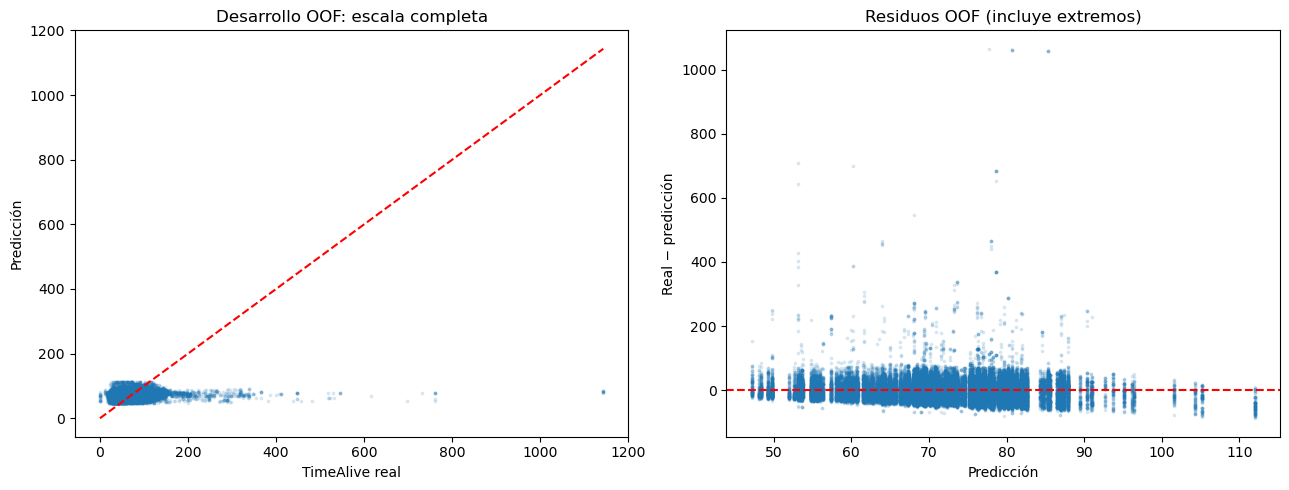

,count,mean,median
Map,,,
de_dust2,14740,24.9344,22.0908
de_inferno,22579,25.1510,22.0354
de_mirage,15419,23.6238,19.7391
de_nuke,10329,22.8533,20.0420


,count,mean,median
Team,,,
CounterTerrorist,31535,24.4784,21.7120
Terrorist,31532,24.2230,20.4281


In [58]:
ablation_rows=[]
chosen_models={}
for task,name,initial,X,y,folds,full,reduced,scoring,primary in [
    ("regresión",reg_initial_name,reg_initial,Xr,yr,reg_folds,REG_FEATURES,[c for c in REG_FEATURES if c!="TeamStartingEquipmentValue"],reg_scoring,"MAE"),
    ("clasificación",cls_initial_name,cls_initial,Xc,yc,cls_folds,CLS_FEATURES,["Map","T_First2Wins","CT_First2Wins"],cls_scoring,"F1_macro")]:
    variants={}
    for label,features in [("completo",full),("reducido",reduced)]:
        est=clone(initial)
        scale=not isinstance(est.named_steps["model"],(DecisionTreeRegressor,DecisionTreeClassifier))
        est.set_params(prep=make_preprocessor(features,scale))
        scores=cross_validate(est,X,y,cv=folds,scoring=scoring,return_train_score=True,n_jobs=1,error_score="raise")
        rec=cv_record(name+" "+label,scores,scoring,["MAE","RMSE"] if task=="regresión" else [])
        rec.update(tarea=task,variante=label,features=", ".join(features))
        ablation_rows.append(rec)
        variants[label]=(est,rec,features)
    full_score=variants["completo"][1][primary+"_CV"]
    reduced_score=variants["reducido"][1][primary+"_CV"]
    use_reduced=reduced_score <= full_score*1.01 if task=="regresión" else reduced_score >= full_score-0.01
    label="reducido" if use_reduced else "completo"
    chosen_models[task]={"name":name,"variant":label,"estimator":variants[label][0],"record":variants[label][1],"features":variants[label][2]}
ablation=pd.DataFrame(ablation_rows)
display(ablation.dropna(axis=1,how="all"))
ablation.to_csv(OUT / "comparacion_subconjuntos_CV.csv",index=False)
reg_choice=chosen_models["regresión"]; cls_choice=chosen_models["clasificación"]
ab_sel=ablation.set_index(["tarea","variante"])
reg_full_mae=ab_sel.loc[("regresión","completo"),"MAE_CV"]; reg_red_mae=ab_sel.loc[("regresión","reducido"),"MAE_CV"]
cls_full_f1=ab_sel.loc[("clasificación","completo"),"F1_macro_CV"]; cls_red_f1=ab_sel.loc[("clasificación","reducido"),"F1_macro_CV"]
reg_reason=("Esto confirma lo que sugería la correlación de 4.4: el equipamiento del equipo repite casi la misma información que el equipamiento individual, así que preferimos el modelo más simple."
            if reg_choice["variant"]=="reducido" else
            "La variable del equipo aporta lo suficiente para justificar mantenerla.")
cls_reason=("Sin las variables económicas el desempeño cae a un nivel cercano al azar (F1 macro de 0,5): **casi toda la capacidad predictiva del modelo viene de la economía** y no de las victorias en las rondas iniciales, en línea con las correlaciones de 4.4. Por eso conservamos el conjunto completo."
            if cls_choice["variant"]=="completo" else
            "Las variables económicas no aportan lo suficiente para mantenerlas, así que preferimos el modelo más simple.")
display(Markdown(f"""**Selección cerrada de regresión: {reg_choice['name']} ({reg_choice['variant']}).** Al retirar `TeamStartingEquipmentValue`, el MAE de validación pasa de {reg_full_mae:.3f} a {reg_red_mae:.3f}, un cambio de {100*(reg_red_mae/reg_full_mae-1):+.2f} % ({'dentro' if reg_red_mae<=reg_full_mae*1.01 else 'fuera'} del margen de 1 %). {reg_reason} Predictores finales: `{', '.join(reg_choice['features'])}`."""))
display(Markdown(f"""**Selección cerrada de clasificación: {cls_choice['name']} ({cls_choice['variant']}).** Al retirar la economía, el F1 macro de validación pasa de {cls_full_f1:.3f} a {cls_red_f1:.3f}, una caída de {cls_full_f1-cls_red_f1:.3f} puntos ({'dentro' if cls_red_f1>=cls_full_f1-0.01 else 'muy por fuera'} del margen de 0,01). {cls_reason} Predictores finales: `{', '.join(cls_choice['features'])}`.

En ambos casos se mantienen los hiperparámetros elegidos por validación cruzada (se imprimen abajo) y **la prueba final todavía no intervino en ninguna decisión**."""))
for task,choice in chosen_models.items():
    print(task,choice["estimator"].named_steps["model"].get_params())

# Diagnóstico de residuos de desarrollo: predicciones OOF del candidato cerrado.
reg_oof_pred=cross_val_predict(reg_choice["estimator"],Xr,yr,cv=reg_folds,n_jobs=1)
reg_oof_frame=reg_dev[["MatchId","Map","Team","TimeAlive"]].copy()
reg_oof_frame["prediccion"]=reg_oof_pred
reg_oof_frame["residuo"]=yr.to_numpy()-reg_oof_pred
reg_oof_frame["error_abs"]=reg_oof_frame.residuo.abs()
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].scatter(yr,reg_oof_pred,s=3,alpha=.12)
limits=[min(yr.min(),reg_oof_pred.min()),max(yr.max(),reg_oof_pred.max())]
axes[0].plot(limits,limits,"r--"); axes[0].set(xlabel="TimeAlive real",ylabel="Predicción",title="Desarrollo OOF: escala completa")
axes[1].scatter(reg_oof_pred,reg_oof_frame.residuo,s=3,alpha=.12)
axes[1].axhline(0,color="red",ls="--"); axes[1].set(xlabel="Predicción",ylabel="Real − predicción",title="Residuos OOF (incluye extremos)")
plt.tight_layout(); savefig("residuos_regresion_OOF.png")
display(reg_oof_frame.groupby("Map").error_abs.agg(["count","mean","median"]))
display(reg_oof_frame.groupby("Team").error_abs.agg(["count","mean","median"]))
reg_oof_frame.to_csv(OUT / "predicciones_regresion_OOF.csv",index=False)

### Interpretación de los residuos del regresor

- **Gráfico de la izquierda (real vs. predicho).** Si el modelo fuera perfecto, todos los puntos estarían sobre la línea roja (predicción = valor real). En cambio, las predicciones se concentran en una franja estrecha, aproximadamente entre 50 y 110 unidades, mientras que los valores reales van desde casi 0 hasta más de 1.000. En la práctica el modelo predice valores cercanos al promedio y los ajusta un poco según mapa, lado, ronda y equipamiento.
- **Gráfico de la derecha (residuos).** Los residuos (real − predicción) negativos son acotados, pero hay residuos positivos de varios cientos de unidades. Es decir, el modelo **subestima los tiempos de supervivencia largos y no anticipa los casos extremos**. Es esperable, porque esos casos dependen de lo que ocurre durante la ronda.
- **Errores por mapa y por lado.** Los errores medios son parecidos, entre ~23 y ~25 unidades: el modelo no falla de forma muy distinta en un mapa o lado en particular. `de_nuke` y `de_mirage` tienen errores algo menores.
- **Media vs. mediana del error.** La mediana del error absoluto (≈ 20–22) es menor que la media (≈ 23–25). La mayoría de las predicciones tiene errores moderados, y unos pocos errores muy grandes suben el promedio.

# FASE 5 — EVALUACIÓN

En esta fase usamos por primera vez el **conjunto de prueba**, que mantuvimos aparte durante todo el modelado. Las decisiones ya están cerradas: no cambiaremos modelos, variables ni hiperparámetros según lo que veamos aquí. Si lo hiciéramos, la prueba dejaría de ser una evaluación independiente y se convertiría en otro conjunto de ajuste.

## 5.1 Prueba final de regresión

Pasos que seguimos:

1. **Reentrenamos** el regresor elegido, con sus hiperparámetros y variables ya fijados, usando **todo el conjunto de desarrollo** para aprovechar el máximo de datos.
2. **Predecimos** `TimeAlive` en las partidas de prueba.
3. **Comparamos** con las líneas base (media y mediana), calculadas solo con desarrollo.
4. Calculamos MAE, RMSE y R² en las unidades originales, **sin recortar ni eliminar** valores extremos.

Sumamos dos análisis complementarios:

- **MAE promedio por partida.** El MAE normal da más peso a las partidas con más filas; este promedio da el mismo peso a cada partida.
- **Intervalo de confianza por *bootstrap* de partidas.** Remuestreamos con reemplazo las partidas de prueba 400 veces y recalculamos el MAE en cada repetición; los percentiles 2,5 y 97,5 forman un intervalo aproximado del 95 %. Remuestreamos partidas completas, no filas, por la misma razón que en 4.3. El intervalo refleja cuánto podría variar el MAE con otras partidas de prueba, pero **no** incluye la incertidumbre de haber elegido o reentrenado el modelo.

Por último, separamos los errores según si el valor real supera o no el **percentil 99 de `TimeAlive` en desarrollo**. Este corte es solo diagnóstico: **no elimina ninguna fila** del resultado global, pero permite ver cuánto influyen los casos extremos.

,modelo,MAE,RMSE,R2
0,Árbol regresión,26.3411,78.6485,0.0069
1,Dummy mediana,27.2532,79.0736,-0.0039
2,Dummy media,27.3526,78.9375,-0.0004


MAE medio con igual peso por partida: 26.037297297737595
Predicciones negativas: 0


,métrica,estimación,IC95_inferior,IC95_superior
0,MAE,26.3411,23.0204,32.2716


,rango,n,MAE,RMSE
0,Hasta p99 de desarrollo,15852,23.1838,27.7929
1,Sobre p99 de desarrollo,148,364.5179,765.4919


,count,mean,median
Map,,,
de_dust2,4380,23.9537,21.4545
de_inferno,6290,31.4627,22.4424
de_mirage,3570,22.6175,20.8383
de_nuke,1760,21.5319,18.5868


,count,mean,median
Team,,,
CounterTerrorist,8000,26.3450,22.1043
Terrorist,8000,26.3372,20.6895


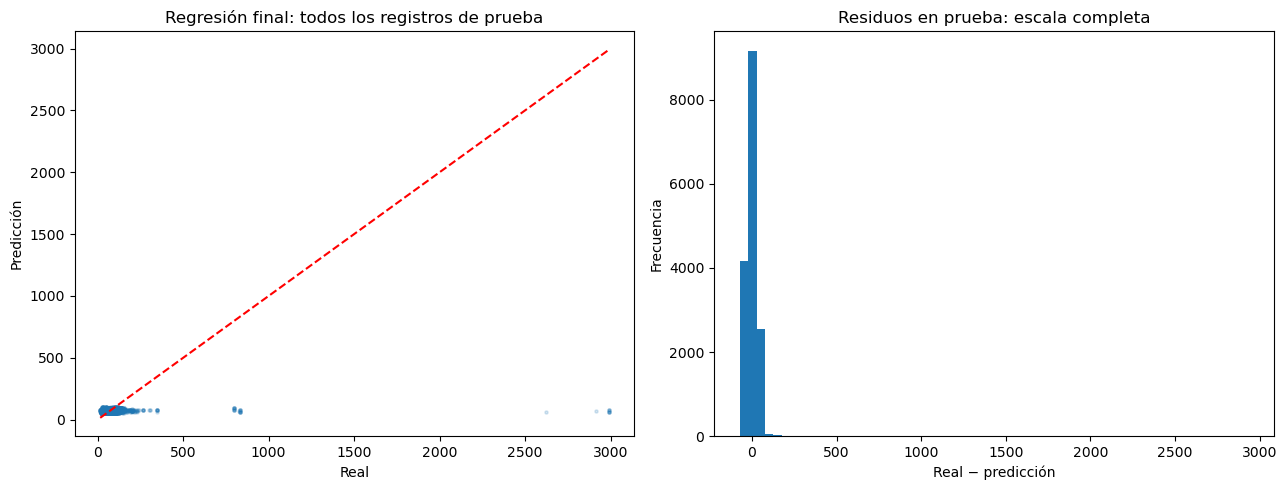

In [59]:
final_reg=clone(reg_choice["estimator"]).fit(Xr,yr)
pred_reg=final_reg.predict(reg_test[REG_FEATURES])
ytr=reg_test.TimeAlive.to_numpy()
reg_test_rows=[]
for name,pred in [(reg_choice["name"],pred_reg),
                  ("Dummy mediana",np.repeat(yr.median(),len(reg_test))),
                  ("Dummy media",np.repeat(yr.mean(),len(reg_test)))]:
    reg_test_rows.append({"modelo":name,"MAE":mean_absolute_error(ytr,pred),
                         "RMSE":np.sqrt(mean_squared_error(ytr,pred)),"R2":r2_score(ytr,pred)})
reg_final_table=pd.DataFrame(reg_test_rows)
display(reg_final_table)
reg_final_table.to_csv(OUT / "evaluacion_final_regresion.csv",index=False)
reg_predictions=reg_test[["MatchId","RoundId","InternalTeamId","SteamId","Map","Team","TimeAlive"]].copy()
reg_predictions["prediccion"]=pred_reg
reg_predictions["residuo"]=ytr-pred_reg
reg_predictions["error_absoluto"]=np.abs(ytr-pred_reg)
reg_predictions.to_csv(OUT / "predicciones_prueba_regresion.csv",index=False)
group_mae=reg_predictions.groupby("MatchId").error_absoluto.mean()
print("MAE medio con igual peso por partida:",group_mae.mean())
print("Predicciones negativas:",int((pred_reg<0).sum()))

def group_bootstrap(groups,metric_fn,n=400):
    groups=np.asarray(groups)
    unique=np.unique(groups)
    positions=[np.flatnonzero(groups==g) for g in unique]
    rng=np.random.default_rng(SEED)
    values=[]
    for _ in range(n):
        idx=np.concatenate([positions[i] for i in rng.integers(0,len(unique),len(unique))])
        values.append(metric_fn(idx))
    return np.percentile(values,[2.5,97.5]).tolist()

reg_mae_ci=group_bootstrap(reg_test.MatchId,lambda i:mean_absolute_error(ytr[i],pred_reg[i]))
display(pd.DataFrame([{"métrica":"MAE","estimación":mean_absolute_error(ytr,pred_reg),
                       "IC95_inferior":reg_mae_ci[0],"IC95_superior":reg_mae_ci[1]}]))

# Umbral diagnóstico fijado en desarrollo, sin excluir observaciones de la evaluación global.
tail_cut=float(yr.quantile(.99))
reg_predictions["rango_target"]=np.where(reg_predictions.TimeAlive>tail_cut,"Sobre p99 de desarrollo","Hasta p99 de desarrollo")
range_rows=[]
for label,part in reg_predictions.groupby("rango_target"):
    range_rows.append({"rango":label,"n":len(part),"MAE":part.error_absoluto.mean(),
                       "RMSE":np.sqrt(np.mean(part.residuo**2))})
reg_ranges=pd.DataFrame(range_rows)
display(reg_ranges)
display(reg_predictions.groupby("Map").error_absoluto.agg(["count","mean","median"]))
display(reg_predictions.groupby("Team").error_absoluto.agg(["count","mean","median"]))
reg_ranges.to_csv(OUT / "errores_regresion_por_rango.csv",index=False)
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].scatter(ytr,pred_reg,s=5,alpha=.18)
limits=[min(ytr.min(),pred_reg.min()),max(ytr.max(),pred_reg.max())]
axes[0].plot(limits,limits,"r--"); axes[0].set(xlabel="Real",ylabel="Predicción",title="Regresión final: todos los registros de prueba")
axes[1].hist(reg_predictions.residuo,bins=60)
axes[1].set(xlabel="Real − predicción",ylabel="Frecuencia",title="Residuos en prueba: escala completa")
plt.tight_layout(); savefig("regresion_prueba_final.png")

In [60]:
reg_metrics=reg_final_table.iloc[0]
reg_base=reg_final_table.loc[reg_final_table.modelo=="Dummy mediana"].iloc[0]
reg_gain=100*(1-reg_metrics.MAE/reg_base.MAE)
reg_cv=reg_choice["record"]["MAE_CV"]
reg_utility=("aporta una mejora frente a la mediana" if reg_gain>0 else "no mejora la mediana en esta prueba")
range_by=reg_ranges.set_index("rango")
low_range=range_by.loc["Hasta p99 de desarrollo"]; high_range=range_by.loc["Sobre p99 de desarrollo"]
map_err=reg_predictions.groupby("Map").error_absoluto.agg(["mean","median"])
worst_map=map_err["mean"].idxmax()
reg_cv_in_ci="incluye" if reg_mae_ci[0]<=reg_cv<=reg_mae_ci[1] else "no incluye"
display(Markdown(f"""**Conclusión de regresión.**

**Resultado principal.** El **{reg_choice['name']} ({reg_choice['variant']})** obtiene en las **{reg_test.MatchId.nunique()} partidas de prueba** un **MAE de {reg_metrics.MAE:.3f}**: en promedio, su predicción se aleja {reg_metrics.MAE:.1f} unidades de tiempo del valor real. Si en lugar del modelo predijéramos siempre la mediana de desarrollo, el MAE sería {reg_base.MAE:.3f}. La mejora relativa es de **{reg_gain:.2f} %**: el modelo {reg_utility}, pero la ganancia es modesta.

**Comparación con la validación cruzada.** En desarrollo el MAE fue {reg_cv:.3f}. El intervalo bootstrap aproximado del MAE de prueba es [{reg_mae_ci[0]:.3f}, {reg_mae_ci[1]:.3f}]: es amplio y {reg_cv_in_ci} el valor de CV, así que buena parte de la diferencia puede explicarse por qué partidas quedaron en la prueba. El MAE medio por partida ({group_mae.mean():.3f}) es parecido al MAE por fila, por lo que el resultado no depende de unas pocas partidas con muchos registros.

**¿Por qué el RMSE ({reg_metrics.RMSE:.3f}) es tanto mayor que el MAE?** El RMSE eleva cada error al cuadrado, así que unos pocos errores enormes pesan muchísimo. La tabla por rangos lo confirma: las {int(low_range.n):,} filas cuyo valor real llega hasta el p99 de desarrollo ({tail_cut:.1f}) tienen MAE {low_range.MAE:.3f} y RMSE {low_range.RMSE:.3f}, mientras que las {int(high_range.n)} filas sobre ese umbral ({high_range.n/len(reg_predictions):.1%} del total) tienen MAE {high_range.MAE:.3f}. El gráfico de dispersión muestra la causa: la prueba contiene valores reales de hasta {ytr.max():.0f}, pero las predicciones del árbol se mantienen en una franja estrecha. El mismo efecto explica que `{worst_map}` tenga el mayor error medio ({map_err.loc[worst_map,'mean']:.1f}) aunque su mediana ({map_err.loc[worst_map,'median']:.1f}) sea parecida a la de los otros mapas. Recordamos que el umbral p99 es solo diagnóstico: **no se eliminó ninguna fila** del resultado global.

**¿Qué significa un R² de {reg_metrics.R2:.4f}?** Que el modelo reduce el error cuadrático apenas un poco respecto de predecir la media de la propia prueba. Dicho de otra forma, casi no explica por qué algunos jugadores sobreviven más que otros.

**Respuesta práctica.** El regresor cumple el procedimiento metodológico y supera levemente a la línea base, pero **no es lo bastante preciso para estimar cuánto sobrevivirá un jugador concreto**. Tampoco definimos un error "aceptable", porque no tenemos un criterio de negocio para fijarlo. Para mejorar esta predicción harían falta variables con más información sobre lo que ocurre en la ronda, siempre que estén disponibles en el momento de predecir.
"""))

**Conclusión de regresión.**

**Resultado principal.** El **Árbol regresión (reducido)** obtiene en las **67 partidas de prueba** un **MAE de 26.341**: en promedio, su predicción se aleja 26.3 unidades de tiempo del valor real. Si en lugar del modelo predijéramos siempre la mediana de desarrollo, el MAE sería 27.253. La mejora relativa es de **3.35 %**: el modelo aporta una mejora frente a la mediana, pero la ganancia es modesta.

**Comparación con la validación cruzada.** En desarrollo el MAE fue 24.351. El intervalo bootstrap aproximado del MAE de prueba es [23.020, 32.272]: es amplio y incluye el valor de CV, así que buena parte de la diferencia puede explicarse por qué partidas quedaron en la prueba. El MAE medio por partida (26.037) es parecido al MAE por fila, por lo que el resultado no depende de unas pocas partidas con muchos registros.

**¿Por qué el RMSE (78.649) es tanto mayor que el MAE?** El RMSE eleva cada error al cuadrado, así que unos pocos errores enormes pesan muchísimo. La tabla por rangos lo confirma: las 15,852 filas cuyo valor real llega hasta el p99 de desarrollo (147.5) tienen MAE 23.184 y RMSE 27.793, mientras que las 148 filas sobre ese umbral (0.9% del total) tienen MAE 364.518. El gráfico de dispersión muestra la causa: la prueba contiene valores reales de hasta 2991, pero las predicciones del árbol se mantienen en una franja estrecha. El mismo efecto explica que `de_inferno` tenga el mayor error medio (31.5) aunque su mediana (22.4) sea parecida a la de los otros mapas. Recordamos que el umbral p99 es solo diagnóstico: **no se eliminó ninguna fila** del resultado global.

**¿Qué significa un R² de 0.0069?** Que el modelo reduce el error cuadrático apenas un poco respecto de predecir la media de la propia prueba. Dicho de otra forma, casi no explica por qué algunos jugadores sobreviven más que otros.

**Respuesta práctica.** El regresor cumple el procedimiento metodológico y supera levemente a la línea base, pero **no es lo bastante preciso para estimar cuánto sobrevivirá un jugador concreto**. Tampoco definimos un error "aceptable", porque no tenemos un criterio de negocio para fijarlo. Para mejorar esta predicción harían falta variables con más información sobre lo que ocurre en la ronda, siempre que estén disponibles en el momento de predecir.


## 5.2 Prueba final de clasificación

Seguimos el mismo procedimiento que en regresión: reentrenamos el clasificador elegido con todo el desarrollo, predecimos las partidas de prueba y comparamos contra la línea base.

**Clase positiva y tipos de error.** La clase positiva es **victoria** (`MatchWinner = 1`). Por lo tanto:

- **Falso positivo (FP):** el modelo dice que el equipo gana, pero pierde.
- **Falso negativo (FN):** el modelo dice que el equipo pierde, pero gana.

No le damos más importancia a uno que al otro, porque no hay un costo de negocio documentado que lo justifique.

**Qué mostramos:**

- **Tabla de métricas** del modelo y de la línea base.
- **Reporte de clasificación** con precision, recall y F1 por clase.
- **Matriz de confusión** en dos versiones: con cantidades y normalizada por fila. En la normalizada cada fila suma 1 y la diagonal muestra el recall de cada clase, es decir, qué proporción de las derrotas y de las victorias reales se reconoció.
- **Curva ROC** del modelo final, esta vez con un único ajuste (sin el problema de mezclar *scores* de varios modelos que mencionamos en 4.7.1).
- **Intervalo bootstrap** del F1 macro, remuestreando partidas como en regresión.

Una aclaración: si el modelo elegido es SVM, la curva ROC usa su *score* de decisión, que **no es una probabilidad**. Por eso no hablamos de "probabilidad de ganar" en sus resultados. Tampoco presentamos como calibradas las probabilidades de otros modelos, porque no lo comprobamos.

Al final revisamos algo propio de este problema: como cada equipo se predice por separado, el modelo podría decir que ambos rivales ganan, o que ambos pierden. Contamos cuántas partidas de prueba tienen ese problema.

,modelo,F1_macro,Accuracy,Balanced_accuracy,Precision_1,Recall_1,F1_1,Especificidad,ROC_AUC,TN,FP,FN,TP
0,SVM,0.6693,0.6694,0.6694,0.6721,0.6613,0.6667,0.6774,0.7214,42,20,21,41
1,Dummy mayoritaria,0.3333,0.5000,0.5000,0.0000,0.0000,0.0000,1.0000,0.5000,62,0,62,0


,precision,recall,f1-score,support
Derrota,0.6667,0.6774,0.6720,62.0000
Victoria,0.6721,0.6613,0.6667,62.0000
accuracy,0.6694,0.6694,0.6694,0.6694
macro avg,0.6694,0.6694,0.6693,124.0000
weighted avg,0.6694,0.6694,0.6693,124.0000


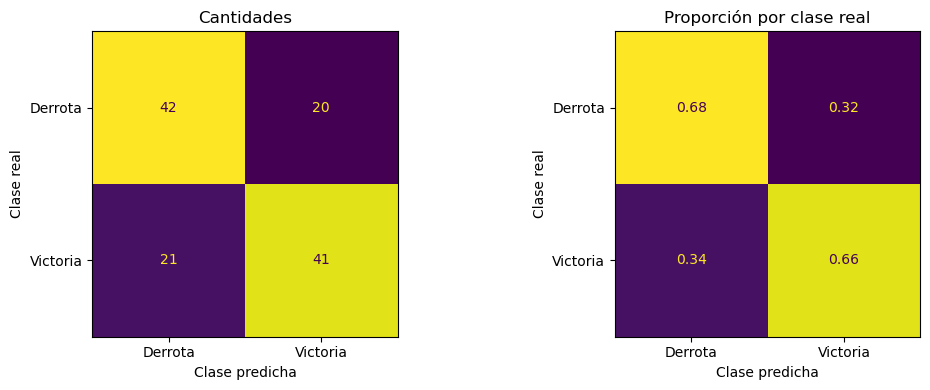

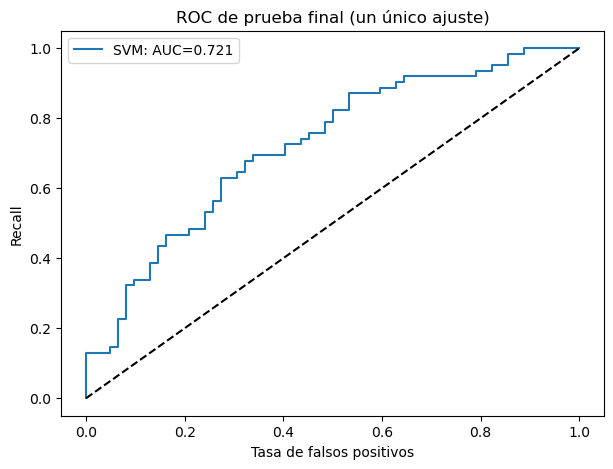

,métrica,estimación,IC95_inferior,IC95_superior
0,F1 macro,0.6693,0.5484,0.7821


Partidas con predicciones independientes que no asignan exactamente un ganador: 7


In [61]:
final_cls=clone(cls_choice["estimator"]).fit(Xc,yc)
ytest_cls=cls_test.MatchWinner.to_numpy()
pred_cls=final_cls.predict(cls_test[CLS_FEATURES])
uses_decision=isinstance(final_cls.named_steps["model"],SVC)
score_cls=final_cls.decision_function(cls_test[CLS_FEATURES]) if uses_decision else final_cls.predict_proba(cls_test[CLS_FEATURES])[:,1]

def cls_metrics(y,pred,score):
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {"F1_macro":f1_score(y,pred,average="macro"),"Accuracy":accuracy_score(y,pred),
            "Balanced_accuracy":balanced_accuracy_score(y,pred),"Precision_1":precision_score(y,pred,zero_division=0),
            "Recall_1":recall_score(y,pred,zero_division=0),"F1_1":f1_score(y,pred,zero_division=0),
            "Especificidad":tn/(tn+fp),"ROC_AUC":roc_auc_score(y,score),
            "TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp)}

cls_final_metrics=cls_metrics(ytest_cls,pred_cls,score_cls)
final_dummy=clone(dummy_cls).fit(Xc,yc)
dummy_pred=final_dummy.predict(cls_test[CLS_FEATURES])
dummy_prob=final_dummy.predict_proba(cls_test[CLS_FEATURES])[:,1]
dummy_final_metrics=cls_metrics(ytest_cls,dummy_pred,dummy_prob)
cls_final_table=pd.DataFrame([dict(modelo=cls_choice["name"],**cls_final_metrics),
                             dict(modelo="Dummy mayoritaria",**dummy_final_metrics)])
display(cls_final_table)
cls_final_table.to_csv(OUT / "evaluacion_final_clasificacion.csv",index=False)
cls_report=pd.DataFrame(classification_report(ytest_cls,pred_cls,labels=[0,1],target_names=["Derrota","Victoria"],output_dict=True,zero_division=0)).T
display(cls_report)
cls_report.to_csv(OUT / "reporte_final_clasificacion.csv")
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,norm,title in [(axes[0],None,"Cantidades"),(axes[1],"true","Proporción por clase real")]:
    ConfusionMatrixDisplay.from_predictions(ytest_cls,pred_cls,labels=[0,1],display_labels=["Derrota","Victoria"],
                                           normalize=norm,ax=ax,colorbar=False,values_format=".2f" if norm else "d")
    ax.set_title(title)
    ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
plt.tight_layout(); savefig("clasificacion_matrices_prueba.png")
fig,ax=plt.subplots(figsize=(7,5))
fpr,tpr,_=roc_curve(ytest_cls,score_cls)
ax.plot(fpr,tpr,label=f"{cls_choice['name']}: AUC={cls_final_metrics['ROC_AUC']:.3f}")
ax.plot([0,1],[0,1],"k--"); ax.set(xlabel="Tasa de falsos positivos",ylabel="Recall",title="ROC de prueba final (un único ajuste)")
ax.legend(); savefig("ROC_prueba_final.png")
cls_f1_ci=group_bootstrap(cls_test.MatchId,lambda i:f1_score(ytest_cls[i],pred_cls[i],average="macro"))
display(pd.DataFrame([{"métrica":"F1 macro","estimación":cls_final_metrics["F1_macro"],
                       "IC95_inferior":cls_f1_ci[0],"IC95_superior":cls_f1_ci[1]}]))
cls_predictions=cls_test[["MatchId","InternalTeamId","Map","MatchWinner"]].copy()
cls_predictions["prediccion"]=pred_cls
cls_predictions["score_victoria" if uses_decision else "probabilidad_victoria_no_calibrada"]=score_cls
cls_predictions.to_csv(OUT / "predicciones_prueba_clasificacion.csv",index=False)
predicted_winners=cls_predictions.groupby("MatchId").prediccion.sum()
incoherent_count=int((predicted_winners!=1).sum())
print("Partidas con predicciones independientes que no asignan exactamente un ganador:",incoherent_count)

In [62]:
m=cls_final_metrics
cls_gain=m["F1_macro"]-dummy_final_metrics["F1_macro"]
cls_cv=cls_choice["record"]["F1_macro_CV"]
cls_cv_in_ci="incluye" if cls_f1_ci[0]<=cls_cv<=cls_f1_ci[1] else "no incluye"
score_label="score de decisión" if uses_decision else "probabilidad estimada"
display(Markdown(f"""**Conclusión de clasificación.**

**Resultado principal.** El **{cls_choice['name']} ({cls_choice['variant']})** obtiene en las **{cls_test.MatchId.nunique()} partidas de prueba** un **F1 macro de {m['F1_macro']:.3f}**, balanced accuracy de {m['Balanced_accuracy']:.3f} y ROC-AUC de {m['ROC_AUC']:.3f}. La línea base, que siempre predice la misma clase, obtiene F1 macro {dummy_final_metrics['F1_macro']:.3f}, así que el modelo mejora {cls_gain:+.3f} puntos. En términos simples, acierta el resultado de alrededor del {m['Accuracy']:.0%} de los equipos, frente al 50 % que se lograría adivinando.

**Lectura de la matriz de confusión.** De las {m['TP']+m['FN']} victorias reales, el modelo reconoce {m['TP']} (TP) y se le escapan {m['FN']} (FN): recall de victoria = {m['Recall_1']:.3f}. De las {m['TN']+m['FP']} derrotas reales, reconoce {m['TN']} (TN) y en {m['FP']} casos predice una victoria que no ocurrió (FP): especificidad = {m['Especificidad']:.3f}. Cuando el modelo predice victoria, acierta el {m['Precision_1']:.1%} de las veces (precision). Los errores se reparten casi por igual entre ambas clases, así que el modelo no está sesgado hacia ninguna. Por eso accuracy, balanced accuracy y F1 macro casi coinciden; en un problema desbalanceado podrían diferir bastante.

**¿Qué significa el ROC-AUC?** Un AUC de {m['ROC_AUC']:.3f} quiere decir que, si tomamos al azar un equipo ganador y uno perdedor, el modelo le asigna un {score_label} más alto al ganador en aproximadamente el {m['ROC_AUC']:.0%} de los casos. Es una capacidad de discriminación **moderada**: bastante mejor que el azar (50 %), pero lejos de ser perfecta.

**Comparación con la validación cruzada.** El F1 macro bajó de **{cls_cv:.3f}** en CV a **{m['F1_macro']:.3f}** en prueba (diferencia de {cls_cv-m['F1_macro']:.3f}). El intervalo bootstrap, [{cls_f1_ci[0]:.3f}, {cls_f1_ci[1]:.3f}], es amplio porque la prueba tiene solo {cls_test.MatchId.nunique()} partidas, y {cls_cv_in_ci} el valor de CV. Parte de la caída puede deberse a la variabilidad de una muestra pequeña, aunque también es posible que la CV haya sido algo optimista por haberse usado para elegir el modelo. No atribuimos la caída a una sola causa y **no modificamos el modelo** después de ver estos resultados.

**Coherencia entre rivales.** En **{incoherent_count} de {cls_test.MatchId.nunique()} partidas** el modelo no asigna exactamente un ganador: predice que ambos equipos ganan o que ambos pierden. Ocurre porque cada equipo se clasifica de forma independiente, sin que el modelo sepa que su rival está en la misma partida. Una formulación que compare directamente a los dos equipos podría resolverlo, pero sería una extensión que no agregamos después de ver la prueba.
"""))

**Conclusión de clasificación.**

**Resultado principal.** El **SVM (completo)** obtiene en las **62 partidas de prueba** un **F1 macro de 0.669**, balanced accuracy de 0.669 y ROC-AUC de 0.721. La línea base, que siempre predice la misma clase, obtiene F1 macro 0.333, así que el modelo mejora +0.336 puntos. En términos simples, acierta el resultado de alrededor del 67% de los equipos, frente al 50 % que se lograría adivinando.

**Lectura de la matriz de confusión.** De las 62 victorias reales, el modelo reconoce 41 (TP) y se le escapan 21 (FN): recall de victoria = 0.661. De las 62 derrotas reales, reconoce 42 (TN) y en 20 casos predice una victoria que no ocurrió (FP): especificidad = 0.677. Cuando el modelo predice victoria, acierta el 67.2% de las veces (precision). Los errores se reparten casi por igual entre ambas clases, así que el modelo no está sesgado hacia ninguna. Por eso accuracy, balanced accuracy y F1 macro casi coinciden; en un problema desbalanceado podrían diferir bastante.

**¿Qué significa el ROC-AUC?** Un AUC de 0.721 quiere decir que, si tomamos al azar un equipo ganador y uno perdedor, el modelo le asigna un score de decisión más alto al ganador en aproximadamente el 72% de los casos. Es una capacidad de discriminación **moderada**: bastante mejor que el azar (50 %), pero lejos de ser perfecta.

**Comparación con la validación cruzada.** El F1 macro bajó de **0.750** en CV a **0.669** en prueba (diferencia de 0.081). El intervalo bootstrap, [0.548, 0.782], es amplio porque la prueba tiene solo 62 partidas, y incluye el valor de CV. Parte de la caída puede deberse a la variabilidad de una muestra pequeña, aunque también es posible que la CV haya sido algo optimista por haberse usado para elegir el modelo. No atribuimos la caída a una sola causa y **no modificamos el modelo** después de ver estos resultados.

**Coherencia entre rivales.** En **7 de 62 partidas** el modelo no asigna exactamente un ganador: predice que ambos equipos ganan o que ambos pierden. Ocurre porque cada equipo se clasifica de forma independiente, sin que el modelo sepa que su rival está en la misma partida. Una formulación que compare directamente a los dos equipos podría resolverlo, pero sería una extensión que no agregamos después de ver la prueba.


## 5.3 Interpretación de los modelos y respuesta al negocio

Además de medir qué tan bien predicen los modelos, queremos entender **en qué se basan para predecir**. La forma de hacerlo depende del tipo de modelo:

- **Modelos lineales (Ridge, logística):** sus coeficientes indican cuánto cambia la predicción cuando una variable aumenta y las demás se mantienen constantes. Como las variables numéricas están estandarizadas, los coeficientes son comparables entre sí.
- **Árboles de decisión:** se pueden leer sus reglas (umbrales aprendidos) y calcular la **importancia por reducción de impureza**, que mide cuánto contribuye cada variable a mejorar las divisiones del árbol. Esta importancia no es causal y, cuando dos variables están relacionadas, puede repartirse entre ellas.
- **SVM con kernel RBF:** no entrega coeficientes globales interpretables, porque su frontera curva se construye a partir de distancias a los vectores de soporte. En ese caso nos apoyamos en la comparación de subconjuntos de variables de la sección 4.10.

**Sobre la pregunta de negocio**, respondemos con **asociaciones y capacidad predictiva** en el momento definido. Nuestros datos son históricos (observacionales): no hicimos un experimento en el que algunos equipos ganaran rondas o compraran equipamiento "a propósito". Por eso no podemos concluir que ganar una ronda o comprar cierto equipamiento **cause** un cambio en el resultado de la partida.

,feature,importancia_impureza
1,RoundStartingEquipmentValue,0.5097
0,RoundId,0.2212
3,Map_de_inferno,0.1758
7,Team_Terrorist,0.0540
6,Team_CounterTerrorist,0.0170
4,Map_de_mirage,0.0141
2,Map_de_dust2,0.0074
5,Map_de_nuke,0.0007


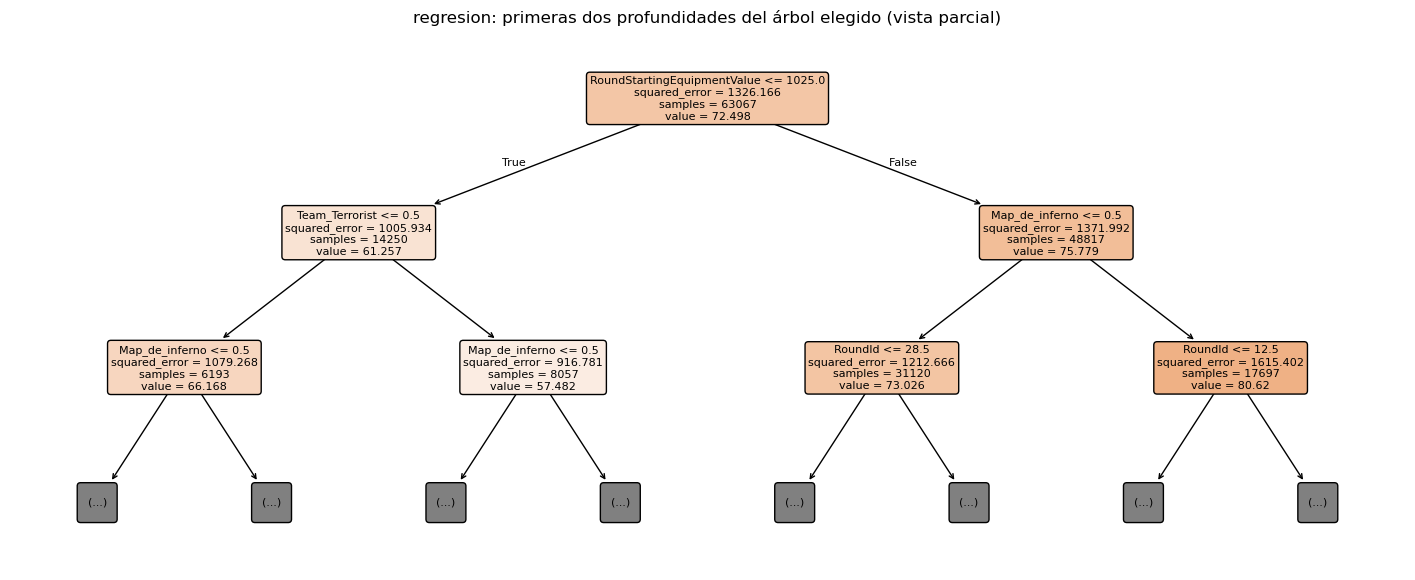

**Modelo de clasificación:** el SVC elegido (kernel `rbf`) no ofrece coeficientes globales interpretables. Su frontera de decisión se construye a partir de distancias a los vectores de soporte, no como una suma ponderada de variables. Por eso su interpretación se apoya en la comparación de subconjuntos de variables (4.10) y en el análisis de errores.

**Interpretación del árbol de regresión.** La variable más importante es `RoundStartingEquipmentValue` (51.0% de la importancia total), seguida de `RoundId` (22.1%) y `Map_de_inferno` (17.6%). Es decir, el árbol se apoya sobre todo en el equipamiento individual al inicio de la ronda y en la posición de la ronda dentro de la partida. El diagrama muestra solo los dos primeros niveles para que sea legible; ahí se ven los primeros cortes que usa el modelo y el valor promedio que predice en cada rama. Estas importancias indican qué variables usa el árbol para dividir los datos, no que esas variables causen un mayor tiempo de supervivencia.

**Aporte de las características en clasificación.** Como el modelo elegido no tiene coeficientes, usamos la comparación de 4.10: sin las variables económicas el F1 macro de validación es 0.480, frente a 0.750 con ellas, y se conserva la variante **completo**. La economía de las primeras rondas observadas es, por lejos, la información que más aporta al clasificador; las victorias en esas rondas, por sí solas, apenas permiten distinguir ganadores de perdedores.

Esto responde nuestra pregunta de investigación de forma parcial y algo inesperada: **en estos datos, ganar las primeras rondas no es un buen predictor del resultado de la partida, mientras que el equipamiento en esas rondas sí lo es**. Esa asociación es negativa (sección 4.4) y no nos permite afirmar una relación causal. Además, estos predictores solo se conocen después del corte temporal descrito en 4.1.

**Aporte de las características en regresión.** Al retirar el equipamiento del equipo, el MAE de validación cambia de 24.253 a 24.351, y se conserva la variante **reducido**. Una vez que el modelo conoce el mapa, el lado, la ronda y el equipamiento individual, el equipamiento del equipo no agrega información relevante (para este algoritmo y esta muestra).


In [63]:
interpretation_tables={}
for label,model in [("regresion",final_reg),("clasificacion",final_cls)]:
    names=model.named_steps["prep"].get_feature_names_out()
    estimator=model.named_steps["model"]
    if hasattr(estimator,"coef_"):
        values=np.asarray(estimator.coef_).ravel()
        table=pd.DataFrame({"feature":names,"coeficiente":values})
        table["magnitud"]=table.coeficiente.abs()
        table=table.sort_values("magnitud",ascending=False)
        display(table)
        table.to_csv(OUT / f"coeficientes_{label}.csv",index=False)
        interpretation_tables[label]=table
    elif hasattr(estimator,"feature_importances_"):
        table=pd.DataFrame({"feature":names,"importancia_impureza":estimator.feature_importances_}).sort_values("importancia_impureza",ascending=False)
        display(table)
        table.to_csv(OUT / f"importancias_{label}.csv",index=False)
        interpretation_tables[label]=table
        fig,ax=plt.subplots(figsize=(18,7))
        plot_tree(estimator,feature_names=list(names),max_depth=2,filled=True,rounded=True,fontsize=8,ax=ax)
        ax.set_title(f"{label}: primeras dos profundidades del árbol elegido (vista parcial)")
        savefig(f"arbol_{label}_interpretacion.png")
    else:
        display(Markdown(f"**Modelo de {'clasificación' if label=='clasificacion' else 'regresión'}:** el {type(estimator).__name__} elegido (kernel `{estimator.get_params().get('kernel','')}`) no ofrece coeficientes globales interpretables. Su frontera de decisión se construye a partir de distancias a los vectores de soporte, no como una suma ponderada de variables. Por eso su interpretación se apoya en la comparación de subconjuntos de variables (4.10) y en el análisis de errores."))

ab_reg=ablation[ablation.tarea=="regresión"].set_index("variante")
ab_cls=ablation[ablation.tarea=="clasificación"].set_index("variante")
reg_imp=interpretation_tables.get("regresion")
if reg_imp is not None and "importancia_impureza" in reg_imp:
    top_imp=reg_imp.head(3).reset_index(drop=True)
    display(Markdown(f"""**Interpretación del árbol de regresión.** La variable más importante es `{top_imp.feature[0]}` ({top_imp.importancia_impureza[0]:.1%} de la importancia total), seguida de `{top_imp.feature[1]}` ({top_imp.importancia_impureza[1]:.1%}) y `{top_imp.feature[2]}` ({top_imp.importancia_impureza[2]:.1%}). Es decir, el árbol se apoya sobre todo en el equipamiento individual al inicio de la ronda y en la posición de la ronda dentro de la partida. El diagrama muestra solo los dos primeros niveles para que sea legible; ahí se ven los primeros cortes que usa el modelo y el valor promedio que predice en cada rama. Estas importancias indican qué variables usa el árbol para dividir los datos, no que esas variables causen un mayor tiempo de supervivencia."""))
display(Markdown(f"""**Aporte de las características en clasificación.** Como el modelo elegido no tiene coeficientes, usamos la comparación de 4.10: sin las variables económicas el F1 macro de validación es {ab_cls.loc['reducido','F1_macro_CV']:.3f}, frente a {ab_cls.loc['completo','F1_macro_CV']:.3f} con ellas, y se conserva la variante **{cls_choice['variant']}**. La economía de las primeras rondas observadas es, por lejos, la información que más aporta al clasificador; las victorias en esas rondas, por sí solas, apenas permiten distinguir ganadores de perdedores.

Esto responde nuestra pregunta de investigación de forma parcial y algo inesperada: **en estos datos, ganar las primeras rondas no es un buen predictor del resultado de la partida, mientras que el equipamiento en esas rondas sí lo es**. Esa asociación es negativa (sección 4.4) y no nos permite afirmar una relación causal. Además, estos predictores solo se conocen después del corte temporal descrito en 4.1.

**Aporte de las características en regresión.** Al retirar el equipamiento del equipo, el MAE de validación cambia de {ab_reg.loc['completo','MAE_CV']:.3f} a {ab_reg.loc['reducido','MAE_CV']:.3f}, y se conserva la variante **{reg_choice['variant']}**. Una vez que el modelo conoce el mapa, el lado, la ronda y el equipamiento individual, el equipamiento del equipo no agrega información relevante (para este algoritmo y esta muestra).
"""))

## 5.4 Ventajas y limitaciones de las métricas

Ninguna métrica cuenta la historia completa por sí sola. Por eso reportamos varias y explicamos por qué elegimos una como principal en cada tarea. La tabla resume qué aporta cada métrica, qué no muestra y qué valor obtuvo nuestro modelo final en la prueba.

| Métrica | Qué permite leer | Limitación | Uso y valor en este trabajo |
|---|---|---|---|
| MAE | Error absoluto promedio, en unidades de `TimeAlive` | No resalta los errores extremos tanto como RMSE | **Principal en regresión** por ser fácil de interpretar. Prueba: 26,34 |
| RMSE | Penaliza más los errores grandes | Puede quedar dominada por pocos tiempos extremos | Complemento; lo leemos junto al diagnóstico por rangos. Prueba: 78,65 |
| R² | Mejora frente a predecir la media del conjunto evaluado | Depende de la variabilidad del test, puede ser negativo y no es un porcentaje de aciertos | Muestra la poca capacidad explicativa del regresor. Prueba: 0,007 |
| Accuracy | Fracción total de aciertos | Puede ocultar fallos en una clase si hay desbalance | Aquí es legible porque las clases están balanceadas. Prueba: 0,669 |
| Precision de victoria = TP/(TP+FP) | Qué tan confiables son las victorias pronosticadas | No muestra cuántas victorias se escaparon | Prueba: 0,672 |
| Recall de victoria = TP/(TP+FN) | Proporción de ganadores reconocidos | No penaliza por sí sola las falsas alarmas | Prueba: 0,661 |
| Especificidad = TN/(TN+FP) | Proporción de derrotas reconocidas | No informa sobre las victorias omitidas | Prueba: 0,677 |
| F1 = 2·precision·recall/(precision+recall) | Equilibrio entre precision y recall de una clase | No usa TN directamente y depende del umbral | F1 de victoria en prueba: 0,667 |
| F1 macro | Promedio del F1 de ambas clases, con el mismo peso | Puede ocultar diferencias entre clases si no se muestran por separado | **Principal en clasificación.** Prueba: 0,669 |
| Balanced accuracy | Promedio del recall de cada clase | No incorpora precision | Complemento del F1 macro. Prueba: 0,669 |
| ROC-AUC | Qué tan bien ordena positivos sobre negativos considerando todos los umbrales | No es accuracy, no mide calibración ni la utilidad de un umbral concreto | Muestra una discriminación moderada. Prueba: 0,721 |

Otras dos variantes de F1 que vimos en el curso:

- **F1 micro** coincide con accuracy en clasificación de una sola etiqueta cuando se incluyen ambas clases, así que no agrega una visión distinta aquí.
- **F1 ponderado (*weighted*)** pondera cada clase por su cantidad de observaciones. Con datos desbalanceados le da menos visibilidad a la clase minoritaria, como habría pasado en el experimento de 4.8. Por eso preferimos el F1 macro.

En nuestro caso, como las clases están balanceadas, accuracy, balanced accuracy y F1 macro casi coinciden. En el experimento con desbalance simulado (4.8) vimos lo contrario: sin corrección, el modelo reconocía muy bien las derrotas y muy mal las victorias, algo que solo se nota mirando los recalls por clase. Ninguna métrica, por sí sola, demuestra utilidad estratégica.

## 5.5 Limitaciones y alcance de las conclusiones

Es importante dejar claro hasta dónde llegan nuestras conclusiones. Junto a cada limitación indicamos qué implica para la interpretación de los resultados.

1. **Las filas no son independientes.** Las ~79 mil filas de regresión vienen de solo 333 partidas, y las filas de una misma partida se parecen entre sí. Por eso separamos y remuestreamos por partida. *Implicancia:* la cantidad real de información es menor de lo que sugiere el número de filas.
2. **La generalización se limita a partidas parecidas.** Un mismo jugador puede aparecer en varias partidas y no hay fechas para hacer una prueba temporal. *Implicancia:* no sabemos cómo se comportaría el modelo con jugadores nuevos, mapas nuevos o partidas futuras (por ejemplo, después de cambios en el juego).
3. **Partidas excluidas.** Las partidas sin un ganador interpretable quedaron fuera de la clasificación. *Implicancia:* el modelo no dice nada sobre empates o partidas incompletas.
4. **Valores extremos de `TimeAlive`.** Los conservamos por la decisión tomada en la Fase 3, y afectan mucho a RMSE y R². No pudimos verificar su origen porque no tenemos un diccionario de datos. *Implicancia:* si fueran errores de registro, el RMSE real sería mejor que el reportado; si son reales, el modelo no logra anticiparlos.
5. **Momento de la predicción.** El clasificador necesita las rondas iniciales de ambos lados, que se conocen cerca de la mitad de la partida. *Implicancia:* no es una predicción previa a la partida, y tampoco usa el marcador completo de ese momento, que probablemente sería más informativo.
6. **Muestra y búsqueda acotadas.** Usamos 5 folds y una grilla limitada, sin validación cruzada anidada, y la prueba de clasificación tiene solo 62 partidas. *Implicancia:* los resultados de desarrollo pueden ser optimistas y los de prueba tienen intervalos amplios.
7. **Intervalos bootstrap aproximados.** Solo reflejan la variación por las partidas de prueba disponibles, no la de elegir o reentrenar el modelo ni cambios en la población.
8. **Balance simulado.** El experimento de desbalance (4.8) es una simulación didáctica; no indica que ese desbalance exista en la población real.
9. **Sin calibración ni causalidad.** No verificamos que las probabilidades estén calibradas ni que las predicciones de dos rivales sean coherentes. Las asociaciones y la importancia de variables no demuestran causalidad.

**Trabajo futuro.** No implementamos despliegue porque no es parte de esta evaluación. Para mejorar el estudio proponemos: incorporar fechas para hacer una validación temporal, conseguir un diccionario de datos que aclare las unidades y el origen de los extremos, sumar más partidas y plantear la clasificación como una comparación directa entre los dos rivales. Cualquier mejora debería evaluarse con un nuevo conjunto de prueba independiente.

## 5.6 Conclusiones finales de EP2

Para cerrar resumimos qué hicimos, qué obtuvimos y qué significa. El texto se genera a partir de las métricas calculadas en las celdas anteriores, así que si el notebook se vuelve a ejecutar las cifras se actualizan solas. Separamos dos cosas: **haber aplicado correctamente la metodología**, que sí logramos, y **haber obtenido un modelo útil en la práctica**, que se logra solo en parte.

In [64]:
# Derivar el resumen desde la evaluación, sin depender de las celdas de interpretación.
reg_metrics=reg_final_table.loc[reg_final_table.modelo==reg_choice["name"]].iloc[0]
reg_base=reg_final_table.loc[reg_final_table.modelo=="Dummy mediana"].iloc[0]
reg_gain=100*(1-reg_metrics.MAE/reg_base.MAE)
reg_cv=reg_choice["record"]["MAE_CV"]
reg_utility=("aporta una mejora frente a la mediana" if reg_gain>0 else "no mejora la mediana en esta prueba")
m=cls_final_metrics
means=simulated_balance.groupby("estrategia").F1_macro.mean()

conclusion_text=f"""### Conclusiones del proyecto

**1. Qué hicimos.** Aplicamos las fases de Modelado y Evaluación de CRISP-DM sobre los datos preparados en la Fase 3. Entrenamos dos algoritmos de regresión (Ridge y árbol de regresión) para predecir `TimeAlive` y cuatro de clasificación (regresión logística, KNN, SVM y árbol de clasificación) para predecir `MatchWinner`, además de modelos de referencia (Dummy). Elegimos los hiperparámetros con validación cruzada de 5 folds agrupada por partida, ajustamos todo el preprocesamiento dentro de pipelines para evitar *data leakage* y reservamos un conjunto de prueba que usamos una sola vez, al final.

**2. Calidad de los datos de entrada.** Antes de modelar resolvimos la advertencia pendiente de la Fase 3: excluimos {len(invalid_ids)} partidas sin un ganador interpretable en vez de inventar su resultado. La clasificación quedó con {len(cls_data)} equipos-partida de {cls_data.MatchId.nunique()} partidas, perfectamente balanceada (un ganador y un perdedor por partida). La regresión conservó {len(reg_data):,} registros.

**3. Regresión.** El modelo elegido fue **{reg_choice['name']} ({reg_choice['variant']})**. En la prueba obtuvo MAE **{reg_metrics.MAE:.3f}**, RMSE **{reg_metrics.RMSE:.3f}** y R² **{reg_metrics.R2:.3f}**. Supera a la predicción constante de la mediana en **{reg_gain:.2f} %**; es decir, {reg_utility}, pero la mejora es pequeña y el R² cercano a cero indica que el modelo casi no explica la variación del tiempo de supervivencia. Concluimos que la información disponible al inicio de la ronda (mapa, lado, número de ronda y equipamiento) **no basta para estimar con precisión cuánto sobrevivirá un jugador**: ese tiempo depende sobre todo de lo que ocurre durante la ronda. Los valores extremos se mantuvieron y explican la gran diferencia entre MAE y RMSE.

**4. Clasificación.** El modelo elegido fue **{cls_choice['name']} ({cls_choice['variant']})**. En la prueba obtuvo F1 macro **{m['F1_macro']:.3f}**, accuracy **{m['Accuracy']:.3f}** y ROC-AUC **{m['ROC_AUC']:.3f}**, frente a un F1 macro de {dummy_final_metrics['F1_macro']:.3f} de la línea base. Reconoce el {m['Recall_1']:.1%} de las victorias y el {m['Especificidad']:.1%} de las derrotas, con {m['FP']} falsos positivos y {m['FN']} falsos negativos repartidos de forma equilibrada. El F1 macro bajó de {cls_choice['record']['F1_macro_CV']:.3f} en validación cruzada a {m['F1_macro']:.3f} en prueba, así que lo calificamos como un desempeño **moderado**, no alto. La predicción está disponible recién al terminar las primeras rondas observadas de ambos lados, no al comienzo de la partida.

**5. Respuesta a la pregunta de investigación.** Nos preguntamos cómo cambia la probabilidad de ganar según el desempeño del equipo en las primeras rondas de cada lado. Los resultados muestran que **la cantidad de rondas iniciales ganadas casi no se asocia con ganar la partida** en estos datos, mientras que **el equipamiento en esas rondas aporta la mayor parte de la capacidad predictiva** (sin la economía, el F1 macro de validación cae de {ab_cls.loc['completo','F1_macro_CV']:.3f} a {ab_cls.loc['reducido','F1_macro_CV']:.3f}). Es una asociación, no una causa: a partir de ella no podemos recomendar gastar más o menos.

**6. Sobreajuste y subajuste.** Con curvas de complejidad comprobamos que los árboles muy profundos memorizan el entrenamiento y empeoran en validación, así que no elegimos modelos por su desempeño en entrenamiento. En regresión, los errores altos y parecidos en entrenamiento y validación indican que faltan variables informativas, más que un modelo demasiado simple.

**7. Balance de clases.** En nuestros datos no fue necesario balancear, porque el diseño ya es 50/50. Para mostrar las técnicas simulamos un desbalance 3:1 en entrenamiento: sin corrección el F1 macro fue {means['sin corrección']:.3f}, con pesos de clase llegó a {means['pesos']:.3f} y con sobremuestreo a {means['sobremuestreo']:.3f}, recuperando casi el desempeño original.

**8. Limitaciones.** Las conclusiones son predictivas y valen para partidas parecidas a las del dataset. No demuestran causalidad, no se validaron con jugadores ni periodos nuevos, y las predicciones de dos rivales pueden ser incoherentes entre sí ({incoherent_count} partidas de prueba no recibieron exactamente un ganador).

**Cierre.** Cumplimos el objetivo académico de la evaluación: cada decisión de modelado quedó justificada con métricas, gráficos y reglas definidas antes de usar la prueba, y el resultado es reproducible. Al mismo tiempo, somos honestos con el alcance: el clasificador tiene una capacidad predictiva moderada y el regresor apenas supera a la línea base, así que ninguno está listo para usarse como herramienta operativa sin más datos y validación adicional.
"""
display(Markdown(conclusion_text))
(OUT / "Conclusiones_EP2.md").write_text(conclusion_text,encoding="utf-8")
summary={"regresion":{"modelo":reg_choice["name"],"variante":reg_choice["variant"],
        "features":reg_choice["features"],"metricas_prueba":reg_metrics.drop("modelo").to_dict(),
        "MAE_CV":reg_cv,"MAE_IC95":reg_mae_ci,"mejora_MAE_vs_mediana_pct":reg_gain,
        "params":final_reg.named_steps["model"].get_params()},
    "clasificacion":{"modelo":cls_choice["name"],"variante":cls_choice["variant"],
        "features":cls_choice["features"],"metricas_prueba":cls_final_metrics,"F1_macro_IC95":cls_f1_ci,
        "partidas_sin_ganador_unico_predicho":incoherent_count,
        "params":final_cls.named_steps["model"].get_params()},
    "filas":{"regresion":len(reg_data),"clasificacion":len(cls_data)},
    "exclusiones_EP2":invalid_ids.tolist(),"sha256_csv":sha256,"seed":SEED}
(OUT / "resumen_resultados.json").write_text(json.dumps(summary,indent=2,ensure_ascii=False,default=str),encoding="utf-8")

### Conclusiones del proyecto

**1. Qué hicimos.** Aplicamos las fases de Modelado y Evaluación de CRISP-DM sobre los datos preparados en la Fase 3. Entrenamos dos algoritmos de regresión (Ridge y árbol de regresión) para predecir `TimeAlive` y cuatro de clasificación (regresión logística, KNN, SVM y árbol de clasificación) para predecir `MatchWinner`, además de modelos de referencia (Dummy). Elegimos los hiperparámetros con validación cruzada de 5 folds agrupada por partida, ajustamos todo el preprocesamiento dentro de pipelines para evitar *data leakage* y reservamos un conjunto de prueba que usamos una sola vez, al final.

**2. Calidad de los datos de entrada.** Antes de modelar resolvimos la advertencia pendiente de la Fase 3: excluimos 13 partidas sin un ganador interpretable en vez de inventar su resultado. La clasificación quedó con 616 equipos-partida de 308 partidas, perfectamente balanceada (un ganador y un perdedor por partida). La regresión conservó 79,067 registros.

**3. Regresión.** El modelo elegido fue **Árbol regresión (reducido)**. En la prueba obtuvo MAE **26.341**, RMSE **78.649** y R² **0.007**. Supera a la predicción constante de la mediana en **3.35 %**; es decir, aporta una mejora frente a la mediana, pero la mejora es pequeña y el R² cercano a cero indica que el modelo casi no explica la variación del tiempo de supervivencia. Concluimos que la información disponible al inicio de la ronda (mapa, lado, número de ronda y equipamiento) **no basta para estimar con precisión cuánto sobrevivirá un jugador**: ese tiempo depende sobre todo de lo que ocurre durante la ronda. Los valores extremos se mantuvieron y explican la gran diferencia entre MAE y RMSE.

**4. Clasificación.** El modelo elegido fue **SVM (completo)**. En la prueba obtuvo F1 macro **0.669**, accuracy **0.669** y ROC-AUC **0.721**, frente a un F1 macro de 0.333 de la línea base. Reconoce el 66.1% de las victorias y el 67.7% de las derrotas, con 20 falsos positivos y 21 falsos negativos repartidos de forma equilibrada. El F1 macro bajó de 0.750 en validación cruzada a 0.669 en prueba, así que lo calificamos como un desempeño **moderado**, no alto. La predicción está disponible recién al terminar las primeras rondas observadas de ambos lados, no al comienzo de la partida.

**5. Respuesta a la pregunta de investigación.** Nos preguntamos cómo cambia la probabilidad de ganar según el desempeño del equipo en las primeras rondas de cada lado. Los resultados muestran que **la cantidad de rondas iniciales ganadas casi no se asocia con ganar la partida** en estos datos, mientras que **el equipamiento en esas rondas aporta la mayor parte de la capacidad predictiva** (sin la economía, el F1 macro de validación cae de 0.750 a 0.480). Es una asociación, no una causa: a partir de ella no podemos recomendar gastar más o menos.

**6. Sobreajuste y subajuste.** Con curvas de complejidad comprobamos que los árboles muy profundos memorizan el entrenamiento y empeoran en validación, así que no elegimos modelos por su desempeño en entrenamiento. En regresión, los errores altos y parecidos en entrenamiento y validación indican que faltan variables informativas, más que un modelo demasiado simple.

**7. Balance de clases.** En nuestros datos no fue necesario balancear, porque el diseño ya es 50/50. Para mostrar las técnicas simulamos un desbalance 3:1 en entrenamiento: sin corrección el F1 macro fue 0.653, con pesos de clase llegó a 0.733 y con sobremuestreo a 0.733, recuperando casi el desempeño original.

**8. Limitaciones.** Las conclusiones son predictivas y valen para partidas parecidas a las del dataset. No demuestran causalidad, no se validaron con jugadores ni periodos nuevos, y las predicciones de dos rivales pueden ser incoherentes entre sí (7 partidas de prueba no recibieron exactamente un ganador).

**Cierre.** Cumplimos el objetivo académico de la evaluación: cada decisión de modelado quedó justificada con métricas, gráficos y reglas definidas antes de usar la prueba, y el resultado es reproducible. Al mismo tiempo, somos honestos con el alcance: el clasificador tiene una capacidad predictiva moderada y el regresor apenas supera a la línea base, así que ninguno está listo para usarse como herramienta operativa sin más datos y validación adicional.


2305

## Referencias técnicas

[scikit-learn: CV y grupos](https://scikit-learn.org/stable/modules/cross_validation.html), [pipelines y prevención de fuga](https://scikit-learn.org/stable/common_pitfalls.html), [imbalanced-learn: remuestreo sin fuga](https://imbalanced-learn.org/stable/common_pitfalls.html) y [sobremuestreo](https://imbalanced-learn.org/stable/over_sampling.html).

## Anexo — Control de ejecución y trazabilidad


Las tablas, figuras, particiones, exclusiones, predicciones y conclusiones quedan en `resultados/`. El hash del CSV y las versiones permiten identificar esta ejecución. El análisis utiliza el dataset local y no requiere servicios externos.
**Dependencias:** `requirements_ep2.txt` contiene las versiones para instalar el entorno del proyecto con Python 3.14.0. La identificación del dataset y las versiones registradas con los resultados están en `resultados/manifiesto.json`.


In [65]:
assert len(reg_searches)==2 and len(cls_searches)==4
assert len(reg_folds)==len(cls_folds)==5
assert set(reg_dev.MatchId).isdisjoint(reg_test.MatchId)
assert set(cls_dev.MatchId).isdisjoint(cls_test.MatchId)
assert len(pred_reg)==len(reg_test) and len(pred_cls)==len(cls_test)
assert np.isfinite(pred_reg).all() and np.isfinite(score_cls).all()
assert set(pred_cls).issubset({0,1})
checks=pd.DataFrame({"control":["Dos regresores y cuatro clasificadores","Cinco folds por tarea",
    "Sin solapamiento de partidas train/test","Predicciones finales completas y finitas", "Conclusiones y resumen exportados"],
    "estado":["OK"]*5})
display(checks)
checks.to_csv(OUT / "verificacion_ejecucion.csv",index=False)
print("Ejecución finalizada. Hash del CSV:",sha256)

,control,estado
0,Dos regresores y cuatro clasificadores,OK
1,Cinco folds por tarea,OK
2,Sin solapamiento de partidas train/test,OK
3,Predicciones finales completas y finitas,OK
4,Conclusiones y resumen exportados,OK


Ejecución finalizada. Hash del CSV: 678bda701515bd4d0c07f623924f0e878000065f3a050cdd8282c450caae1569
